# Palmer 2007 CTD Data 
# Cleaned up version 2 : October 8 2026 

- Cruise data from NBP07-02 can be found at the Marine Geoscience Data System.
- Cruise documents are here.
    - https://www.marine-geo.org/tools/search/entry.php?id=NBP0702#documents 
- Data downloads are here.
    - https://www.marine-geo.org/tools/search/entry.php?id=NBP0702#datasets
- CTD from the cruise are in: Inverse_Modeling_Subgroup/NBP0702_CTD/ 

Improvements I've made 
- change the isotherm LNM to an isopycnal LNM to test what difference it makes 
- remove any unused code blocks to simplify 
- remove the zero profile and zero section? if I never use them 
- mark on TS heatmap the total transport (or split into transport in and out) just for sanity check that the bins add up 
- fix TS bot tri so heatmap shows all transport 
- convert density space to have lnm_isopycnal also 


Notes for what to improve 
- look at the oxygen information again? 
    - check on other tracers or ADCP from this cruise 
- could try to constrain transport for the different sub boxes, see if they add up? -
- 
- change lat lon to actual x straight line between pairs? thermal wind does use actual distance, latlon is just for orientation of flow? 
- check on iceshelf sections if they can extend out to a further station and get cutoff at a midpoint 
- adapt transport sensitivity to work for lnm_isotherm and lnm_isopycnal 

- add trough labels to plots 
- can the iceshelf overturning replicate the whole shelf overturning? 



Taking some notes for our meeting with Kevin (July 30, 2026):

- Need to estimate the shelf overturning circulation in density space --> <span style="color:pink">can we see an ice-shelf overturning; understand how this would relate to water mass transformation.</span>

- Think about how we would estimate these transports in temperature and salinity space; this is essentially conditioning the transport on two tracers (e.g. discretizing temperature and salinity and then finding your discretized transport in your dT and dS binning).

- <span style="color:pink">Suggest go back to the longer shelf-break section to see if we can estimate the overturning in density space (also try this in T/S space?).</span>



## imports

In [1]:
import os
import sys  
import numpy as np  

def FileLst(key):
    #sys.path.append(walker)
    Lst = np.array([])
    for root, dirs, files in os.walk('.'):
        for name in files:
            #if name.endswith(key) == True:
            if name.find(key) != -1:
                #print(name)
                Lst = np.append(Lst, name)
            #sys.path.append(pth)
            #walkdir(pth)
    return Lst


# from fileio_wrapper import Fileio
# from Fileio import FileList # wasnt working 

import netCDF4 as nc
import matplotlib.pyplot as plt

import pandas as pd

from matplotlib import path
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.ticker as mticker
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import cartopy.crs as ccrs
import cartopy.feature as cfeature

import xarray as xr
import argopy
import datetime
import gsw
from datetime import datetime

import glob
from pyproj import Transformer, Geod

from scipy.interpolate import griddata
from geopy.distance import geodesic # use to get distance between coordinates 
from geopy import distance
from itertools import accumulate
from scipy.interpolate import interp1d
from matplotlib.ticker import ScalarFormatter
import matplotlib.colors as colors

from matplotlib.scale import FuncScale
import matplotlib.ticker as ticker
import seaborn as sns


In [2]:
# load in all files with path name for ctd data 
path = '/home/edworak/eady-data1/Palmer/NBP0702_nc_ctd/'
files = glob.glob('/home/edworak/eady-data1/Palmer/NBP0702_nc_ctd/*.nc')

############# IMPORT NBP0702 Hydrography from CCHDO
lst = glob.glob('/home/edworak/eady-data1/Palmer/NBP0702_nc_ctd/*.nc')


## make into one dataset 
# I am loading in information from each dataset and combining it 
datasets = []

for i, file in enumerate(lst):

    ds = xr.open_dataset(file)
    # remove singleton dims if present
    ds = ds.squeeze()
    # add profile dimension
    ds = ds.expand_dims(profile=[i])
    datasets.append(ds)

# concatenate profiles
ctd_all = xr.concat(
    datasets,
    dim='profile',
    join='outer')
ctd_all



KeyboardInterrupt: 

### rtopo : ice shelf (2016)
### gebco : bathymetry (2025)

In [ ]:
#%%  MAKE THE ICE SHELF MASK USING BEDMAP 3 DATA

pth = '/home/edworak/eady-data1/Palmer/'
ds = xr.open_dataset(pth+'RTopo-2.0.1_30sec_Antarctica_aux.nc')

ice = ds['amask']
lat = ds['lat']
lon = ds['lon']
kp = (lon[:]>-150) & (lon[:]<-90)
sice = ice[:,kp]
kp2 = (lat[:]>-77)
sice = sice[kp2,:]
Lat = lat[kp2]
Lon = lon[kp]

# Mask:  0 = ocean, 1 = grounded ice, 2 = floating ice, 3 = bare land.
sice = sice[:].astype(float)

# nan out ocean
sice = sice.where(sice != 0) 

sice = sice.where(sice != 1) 

#nan out bare land
sice = sice.where(sice != 3)

shelf=sice.copy()
shelf = shelf.where(sice != 1) 

lan=sice.copy()
lan = lan.where(sice != 2) 

# shelf is no ocean, no bare land, just the sea ice mask 




#%%

############# IMPORT NBP0702 Hydrography from CCHDO

lst = glob.glob('/home/edworak/eady-data1/Palmer/NBP0702_nc_ctd/*.nc')
# imported the whole list of files but just reading in the first one 
l = lst[0]

ds = nc.Dataset(l)

p = ds['pressure'][:].data   
T = ds['temperature'][:].data
s = ds['salinity'][:].data       
o = ds['oxygen'][:].data

st = float(l[-16:-13])*np.ones(len(o))
la = ds['latitude']*np.ones(len(o))
lo = ds['longitude']*np.ones(len(o))

for l in lst[1:]:
    
    ds = nc.Dataset(l)

    p = np.hstack([p,ds['pressure'][:].data])   
    #T = ds['temperature'][:].data
    T = np.hstack([T,ds['temperature'][:].data])  
    #p = ds['salinity'][:].data   
    s = np.hstack([s,ds['salinity'][:].data])    
    #o = ds['oxygen'][:].data
    o = np.hstack([o,ds['oxygen'][:].data])
    
    la = np.hstack([la,ds['latitude']*np.ones(len(ds['pressure'][:].data))])
    lo = np.hstack([lo,ds['longitude']*np.ones(len(ds['pressure'][:].data))])

    st = np.hstack([st,float(l[-16:-13])*np.ones(len(ds['pressure'][:].data  ))])
    

dat = np.vstack([st,la,lo,p,T,s,o]).T


df = pd.DataFrame({'sta':st,'lat':la,'lon':lo,'pdb':p,'T':T,'sal':s,'oxy':o})
df.sort_values(by='sta',inplace=True)

u = df['sta'].unique()


kp = (df['lon']<-95) & (df['lon']>-135)

amdf = df.loc[kp,:]  
fdf = amdf.drop_duplicates(subset=['sta'], keep='first')
fdf


,sta,lat,lon,pdb,T,sal,oxy
12280,40.0,-72.521202,-124.766502,81.0,-1.6543,33.9818,6.1294
139588,41.0,-72.794197,-122.487701,435.0,-0.2802,34.3430,4.9024
13882,42.0,-72.653000,-122.461998,512.0,1.3288,34.7071,4.3364
138798,43.0,-72.615196,-120.213699,136.0,-1.8181,34.0955,6.1754
139764,44.0,-71.899696,-118.652802,159.0,-1.5853,34.0886,6.2244
...,...,...,...,...,...,...,...
121893,185.0,-71.072304,-105.282501,529.0,1.1398,34.7221,4.4667
122139,186.0,-71.062302,-105.277000,227.0,-0.5246,34.2638,5.5077
123050,187.0,-71.056000,-105.275497,543.0,1.2183,34.7191,4.4317
124070,188.0,-71.050499,-105.275703,964.0,0.7413,34.7138,4.7117


In [ ]:


# use_box= np.array([115, 116, 117, 118, 119, 122, 123, 125, 126, 127, 129, 131, 40, 132, 41, 133, 43, 134, 135, 136, 137, 139, 140, 142, 143, 144, 145, 147, 148, 149, 151, 152, 154, 161, 164, 163, 162, 161, 160])
# amdf_cross_sec = amdf.loc[amdf['sta'].isin(use_box),:]
# fdf = amdf_cross_sec.drop_duplicates(subset=['sta'], keep='first')



# 3. Setup the Figure and Projection
fig = plt.figure(figsize=(13, 8))

ax = fig.add_subplot(1, 1, 1, projection=ccrs.SouthPolarStereo(central_longitude=-110))
ax.set_extent([-135, -97, -76, -70], ccrs.PlateCarree())

pth = '/home/edworak/eady-data1/Palmer/'
ds = xr.open_dataset(pth+'gebco_2025_sub_ice.nc')


# 2. Subset to the Barents Sea (if the file is global)
# GEBCO variables are usually named 'elevation' or 'z'
amsjo = ds.sel(lon=slice(-150, -90), lat=slice(-76, -68))

# 4. Plot Bathymetry
# We use 'Blues_r' for ocean depth and set a robust range
plot = amsjo.elevation.plot(
    ax=ax, 
    transform=ccrs.PlateCarree(), 
    cmap='Blues_r', 
    vmin=-1000, vmax=0,  
    cbar_kwargs={'label': 'Depth (m)', 'shrink': 0.5,},
    zorder=0,)

ax.contourf(Lon, Lat, shelf, levels=[2,2.01], transform=ccrs.PlateCarree(),cmap='winter')


ax.scatter(fdf['lon'],fdf['lat'],
             c='orange',marker='o',s=20,
             label='NBP0702 Stations',transform=ccrs.PlateCarree(), )

for i,row in fdf.iterrows():
    if i % 2 == 0:
        # plt.scatter(row['lon'],row['lat'])
        ax.text(row['lon'],row['lat'],str(row['sta']), fontsize = 8, transform=ccrs.PlateCarree())

    
# 5. Add Map Features
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.LAND, facecolor='lightgrey',zorder=10)
ax.add_feature(cfeature.BORDERS, linestyle=':', alpha=0.5)

# Add gridlines
gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
gl.top_labels = False
gl.right_labels = False


#plt.title('North Sea Fixed or Floating', fontsize=14)
ax.set_aspect(1)
plt.show()


KeyboardInterrupt: 

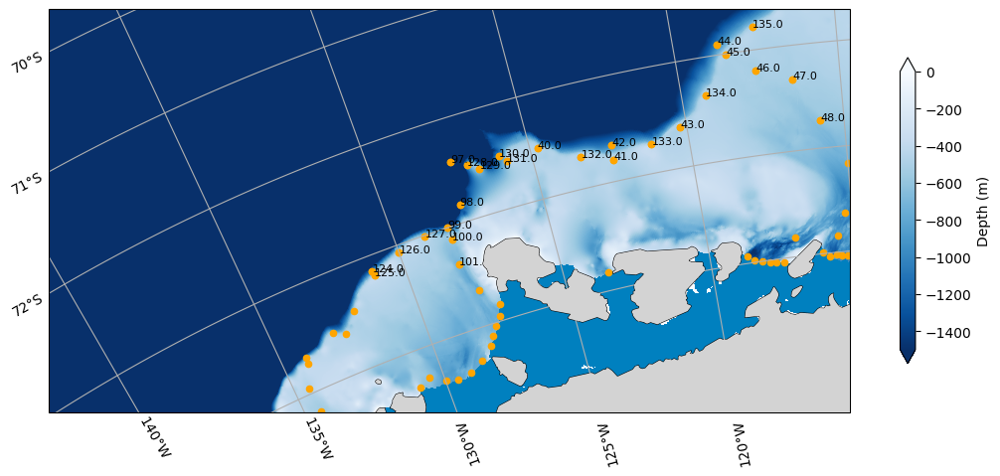

In [ ]:
#%%
# 3. Setup the Figure and Projection
fig = plt.figure(figsize=(13, 8))
#ax = plt.axes(projection=ccrs.Orthographic(central_longitude=20, central_latitude=65))

ax = fig.add_subplot(1, 1, 1, projection=ccrs.SouthPolarStereo(central_longitude=-110))

"""# from zig zag section with a ton of profiles 
lon_min = -106.3
lon_max = -104.3
lat_min = -71.2 
lat_max = -71 """

""" # 160 - 164 
lon_min = -105
lon_max = -100
lat_min = -72 
lat_max = -70.3 """ 

""" # 115 - 120 
lon_min = -138
lon_max = -132
lat_min = -74.6 
lat_max = -73.3 """ 

"""# 108 - 113
lon_min = -132
lon_max = -127
lat_min = -74.6 
lat_max = -74.1
"""

"""# ice shelves 
lon_min = -120
lon_max = -110
lat_min = -74.4
lat_max = -73.3"""


# shelf  
lon_min = -140
lon_max = -115
lat_min = -73.4
lat_max = -71.7


# 135, 136, 137, 139, 140, 142, 143, 144, 145, 147, 148, 149, 151, 152, 154, 155, 156, 157
# change fdf_sel below !! 
"""lon_min = -120
lon_max = -100
lat_min = -72 
lat_max = -70.3"""


ax.set_extent([lon_min, lon_max, lat_min, lat_max], ccrs.PlateCarree())

pth = '/home/edworak/eady-data1/Palmer/'
# ds = nc.Dataset(pth+'gebco_2025_sub_ice.nc', "r", format="NETCDF4")
ds = xr.open_dataset(pth+'gebco_2025_sub_ice.nc')


# 2. Subset to the Barents Sea (if the file is global)
# GEBCO variables are usually named 'elevation' or 'z'
# amsjo = ds.sel(lon=slice(-115, -95), lat=slice(-76, -70))
amsjo = ds.sel(lon=slice(-150, -90), lat=slice(-76, -68))


# 4. Plot Bathymetry
# We use 'Blues_r' for ocean depth and set a robust range
plot = amsjo.elevation.plot(
    ax=ax, 
    transform=ccrs.PlateCarree(), 
    cmap='Blues_r', 
    vmin=-1500, vmax=0,  # Barents Sea is relatively shallow (~230m avg)
    cbar_kwargs={'label': 'Depth (m)', 'shrink': 0.5,},
    zorder=0,)

ax.contourf(Lon, Lat, shelf, levels=[2,2.01], transform=ccrs.PlateCarree(),cmap='winter')


# for all non shelf plots 
fdf_sel = fdf.loc[(fdf.lon >= lon_min) & (fdf.lon <= lon_max) & (fdf.lat >= lat_min) & (fdf.lat <= lat_max)]

ax.scatter(fdf['lon'],fdf['lat'],
             c='orange',marker='o',s=20,
             label='NBP0702 Stations',transform=ccrs.PlateCarree(), )


"""
# just for shelf section plot 
use_shelf = np.array([135, 136, 137, 139, 140, 142, 143, 144, 145, 147, 148, 149, 151, 152, 154, 155, 156, 157])
amdf_shelf = amdf.loc[amdf['sta'].isin(use_shelf),:]
fdf_sel = amdf_shelf.drop_duplicates(subset=['sta'], keep='first')
"""

ax.scatter(fdf_sel['lon'],fdf_sel['lat'],
             c='orange',marker='o',s=20,
             label='NBP0702 Stations',transform=ccrs.PlateCarree(), )


for i,row in fdf_sel.iterrows():
        ax.text(row['lon'],row['lat'],str(row['sta']), fontsize = 8, transform=ccrs.PlateCarree())

    
# 5. Add Map Features
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.LAND, facecolor='lightgrey',zorder=10)
ax.add_feature(cfeature.BORDERS, linestyle=':', alpha=0.5)

# Add gridlines
gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
gl.top_labels = False
gl.right_labels = False


#plt.title('North Sea Fixed or Floating', fontsize=14)
ax.set_aspect(1)
plt.show()


## plot interpolated sections 

For CTD sections:
- interpolate horizontally (across longitude)
- preserve the actual sampled depths
- leave regions below the deepest cast as NaN
- show the original cast locations

1. Put all profiles onto a common depth grid 
2. Interpolate only across x at each depth level

- use interp1d : 1D piecewise linear or spline interpolating function from given data points
- enumerate: enumerate(), it returns an enumerate object, which is a type of lazy iterator that yields pairs (tuples) of (index, element). dont have to add a counter yourself 

## density gsw 

gsw.density.sigma0(SA, CT)[source]
- Calculates potential density anomaly with reference pressure of 0 dbar, this being this particular potential density minus 1000 kg/m^3. This function has inputs of Absolute
  Salinity and Conservative Temperature. This function uses the computationally-efficient expression for specific volume in terms of SA, CT and p (Roquet et al., 2015).

Parameters:
SAarray-like
Absolute Salinity, g/kg

CTarray-like
Conservative Temperature (ITS-90), degrees C

Returns:
sigma0array-like, kg/m^3
potential density anomaly with respect to a reference pressure of 0 dbar, that is, this potential density - 1000 kg/m^3.

## thermal wind

- lets try this with stations 46 and 47
  1. get two close profiles to create a station pair
  2. change T and S into density using sigma0, plot this 
  3. get horizonal density difference between stations and b\plot dV/dZ to get the vertical shear profile, check units and magnitude
  4. sum the vertical shear over z and plot
  5. check what is the velocity field if v=0 at z=0 and if v=0 at z=-H
  6. do this again with two far from each other profiles
  7. check for two close and two far profiles: check no net transport (m^3/s) for the two stations, vol transport = 0 
  8. after I complete for one station pair, do process along shelf

--------

- references: Andys 'Frontal Structure' paper, replicate figures with distance and latitude, can measure distance from above bottom of seafloor, look at appendix fig 16 station pair description

- look at Jacobs 2012


### note 
- Remember that the thermal wind relationship always gives you the velocity shear profile perpendicular to the station pairs, regardless of orientation.  One way to think about this is that you can always orient your axes so that x-direction is the direction of pair separation and the flow is in the y-direction. 

## Level of no motion 
<span style="color:pink">

To get the level of no motion I can subtract the mean of the profile from each point of the profile. 
Wherever that new profile intersects the zero line is my level of no motion. 
The profile above 0 and below zero should be equal and opposite for a sum of zero over the profile. This means that Vref is the profiles negative mean.    

</span>

- Should check on the impact of eliminating the surface and bottom to make profiles match for getting a shear between two profiles 
- Can use bottom triangles to fix the issue of the bottom
- Are there strong surface flows in the top 3 meters and can I just interpolate to the surface? 

### transport calculation 

<span style="color:pink">

T = T baroclinic + T offset = 0 

</span>


## bottom triangles 

- use the gradient of shallower profile to extrapolate down to depth of the other profile
- get geostrophic velocity from deep profile and extrapolated profile
- find the transport through the bottom triangle

- some station pairs have a large depth difference, I need to extrapolate density before converting to velocity again
- take an approach more simlar to thompson and heywood since it assumes that there may be significant flow at the bottom 

# Analyze cross sections 
- Want to look at a bunch of sections of stations that intersect along or cross shelf
- start with sections of 115-120 or 159-162+ area
- then look along the ice shelf
- if I want to look at the shelf break with on and off shelf pairs then I can do the bottom triangles since that's where theres a big depth difference

<span style="color:pink">

def cross_section_depth 
- takes the station pairs in the list of stations given, and it calculates the pair distance, the center latitude and longitude, the sigma0 potential denisty, the shear, velocity, and transport
- calculated on station pairs, n-1 profiles

def interp_pair
- calculates interpolation from output of cross_section_depth masks the bottom (max commomn depth of station pair) to fill with nans to only display legitimate depths

def interp_cast 
- interpolates fields of temp, salinity, oxygen, density
- also masks the bottom (seafloor) with nans 

</span>

- T, S, σ₀	station locations
- dρ/dy	station pairs
- dv/dz	station pairs
- v(z)	station pairs
- transport(z)	station pairs

In [ ]:
# select out bathymetry line 
pth = '/home/edworak/eady-data1/Palmer/'
ds = xr.open_dataset(pth+'gebco_2025_sub_ice.nc')
# 2. Subset to the Barents Sea (if the file is global)
# GEBCO variables are usually named 'elevation' or 'z'
amsjo = ds.sel(lon=slice(-150, -90), lat=slice(-76, -68))
amsjo.elevation


pth = '/home/edworak/eady-data1/Palmer/'
gebco = xr.open_dataset(pth+'gebco_2025_sub_ice.nc')
gebco

<xarray.Dataset> Size: 7GB
Dimensions:    (lat: 43200, lon: 86400)
Coordinates:
  * lon        (lon) float64 691kB -180.0 -180.0 -180.0 ... 180.0 180.0 180.0
  * lat        (lat) float64 346kB -90.0 -89.99 -89.99 ... 89.99 89.99 90.0
Data variables:
    crs        |S1 1B ...
    elevation  (lat, lon) int16 7GB ...
Attributes: (12/36)
    title:                           The GEBCO_2025 Grid - a continuous terra...
    summary:                         The GEBCO_2025 Grid is a continuous, glo...
    keywords:                        BATHYMETRY/SEAFLOOR TOPOGRAPHY, DIGITAL ...
    Conventions:                     CF-1.6, ACDD-1.3
    id:                              DOI: 10.5285/37c52e96-24ea-67ce-e063-708...
    naming_authority:                https://dx.doi.org
    ...                              ...
    geospatial_vertical_units:       meters
    geospatial_vertical_resolution:  1.0
    geospatial_vertical_positive:    up
    identifier_product_doi:          DOI: 10.5285/37c52e96-24ea-67ce-e063-708...
    references:                      DOI: 10.5285/37c52e96-24ea-67ce-e063-708...
    node_offset:                     1.0

### Bottom Triangles

bottom triangles 

From Thompson and Heywood: 
- calculate the geopotential anomaly of A and B CTD profiles 
- use the gradient of geopotential at bottom to linearly extrapolate down the shallow profile to the deep profile 
- create a weighted average of geopotential anomalies and thrn infer geostrophic velocity 
- use the extrapolated velocity to get transport 

- I actually need to interpolate the density in the bottom triangle 
- weigh the density by the density profiler its closer to 
- get dx as linear line between casts 


What I need: 
- density station a (shallower), density station b (deeper) (use instead of the geopotential anomaly in Thompson and Heywood, 2008)
- gradient of density station a at the bottom, linear extrapolate to depth of station b 
- create new density at each level from pair_bottom to deep_bottom, use a weighted average of station a and b based on x distance to closer station 
- get the geostrophic velocity using the extrapolated density, 

get shear from thermal wind inside triangle:  
- shear = - (g / (rho * f)) * (density difference/horizontal difference)
- shear = - (g / (rho * f)) * ((potdens_two - potdens_one)/dm_pair)

get velocity from shear inside triangle: 
- velocity = summed shear per depth level * thickness of depth layer 
- straight from density: velocity = ((station b density - weighted density average) / (f * horizontal difference)) 
        * (station depth difference / difference z to deep_bottom)

get transport from velocity inside triangle: 
- transport = velocity(z) * horizontal distance * (difference z to deep_bottom / station depth difference) summed from pair_bottom to deep_bottom 

In [ ]:
def bottom_triangles(p_a, potdens_a, potdens_b, p_b_full, potdens_b_full, pair_bottom, deep_bottom, dz, distance):
    # station a = shallow station (bottom = pair_bottom), station b = deep station (bottom = deep_bottom).
    # p_b_full/potdens_b_full must reach deep_bottom 
    if not np.isfinite(deep_bottom) or deep_bottom <= pair_bottom:
        return p_a, potdens_a, potdens_b, np.full(len(p_a), distance, dtype=float)

    # pressure levels spanning the triangle: from deepest common level to deep cast
    p_tri = np.arange(pair_bottom + dz, deep_bottom, dz)
    p_tri = np.append(p_tri, deep_bottom)

    # linearly extrapolate station a below its own bottom using its own density gradient
    # use a linear fit over the last ~15 dbar of real data, CTD casts often have a noisy or spiked last reading near the seafloor 
    
    # last 15 points 
    window = p_a >= p_a[-1] - 15 
    if window.sum() >= 3:
        gradient_a = np.polyfit(p_a[window], potdens_a[window], 1)[0]
    else:
        gradient_a = (potdens_a[-1] - potdens_a[-2]) / (p_a[-1] - p_a[-2])
    potdens_a_tri = potdens_a[-1] + gradient_a * (p_tri - p_a[-1])

    # station b has real data through the triangle, match to station a structure 
    potdens_b_tri = np.interp(p_tri, p_b_full, potdens_b_full)

    # weighted average of stations a and b
    # weigh density by closer station, same as Thompson 2008 once combined with dx width taper 
    weight_a = (deep_bottom - p_tri) / (deep_bottom - pair_bottom)
    weighted_potdens_a = potdens_a_tri * weight_a + potdens_b_tri * (1 - weight_a)

    # taper dx linearly from the full pair distance at pair_bottom to 0 at deep_bottom
    taper_dist = interp1d([pair_bottom, deep_bottom], [distance, 0.0], kind='linear')
    dist_tri = taper_dist(p_tri)

    # for export 
    p_fullprof = np.concatenate((p_a, p_tri))
    potdens_a_fullprof = np.concatenate((potdens_a, weighted_potdens_a))
    potdens_b_fullprof = np.concatenate((potdens_b, potdens_b_tri))
    dist_fullprof = np.concatenate((np.full(len(p_a), distance, dtype=float), dist_tri))

    return p_fullprof, potdens_a_fullprof, potdens_b_fullprof, dist_fullprof

### Level of no motion isotherm

- pick a level of no motion based on the thermocline 
- set it to 0 deg or 0.5 deg, it appears that the level of no motion is a bit shallower than the thermocline based on previous sensitivity plots 
- pick gradient working from bottom up since some of the ice shelf sections have warm surface water above the thermocline 

In [ ]:
# df ~ amdf_cross_sec

def isotherm_lnm(df, latlon, temp_threshold=0.0):
    # find, for every xi column, the depth of the first temp_threshold isotherm working up from the bottom 
    # spatially variable lnm_depth

    # -----------------------------------------
    # Regular grids
    xi = np.linspace(df[latlon].min(), df[latlon].max(), 300)
    zi = np.linspace(0, 2000, 600)

    # empty array
    Ti = np.full((len(zi), len(xi)), np.nan)

    # -----------------------------------------
    # Interpolate temperature across latitude/longitude, same approach as interp_cast
    for k, z in enumerate(zi):

        # data near this depth, pools every station in that section near that depth
        layer = df[np.abs(df.pdb - z) < 2]

        # skip if there's no data at all near this depth
        if len(layer) == 0:
            continue

        if len(layer) == 1:
            # only one station has data at this depth
            j = np.argmin(np.abs(xi - layer[latlon].values[0]))
            Ti[k, j] = layer['T'].values[0]
            continue

        # temperature
        fT = interp1d(layer[latlon], layer['T'], bounds_error=False, fill_value=np.nan)
        Ti[k, :] = fT(xi) # set temp with interpolated values

    # -----------------------------------------
    # for each xi column, walk up from the deepest valid level and find the first place T crosses temp_threshold 
    # linearly interpolate between the two nearby zi levels 
    lnm_depth = np.full(len(xi), np.nan)

    # work through x grid 
    for j in range(len(xi)):
        # temp on that x value, check that more than 2 points
        col = Ti[:, j]
        valid = np.where(~np.isnan(col))[0]
        
        # nan if fewer than two points 
        if len(valid) < 2:
            continue

        valid = valid[::-1]  # deepest first, walking up from the bottom
        for idx in range(len(valid) - 1):
            # deep and shallow depths and temps 
            k_deep, k_shallow = valid[idx], valid[idx + 1]
            t_deep, t_shallow = col[k_deep], col[k_shallow]

            # no sign change 
            if t_deep == t_shallow:
                continue

            # sign change (or exact hit) between these two levels = the isotherm crossing
            if (t_deep - temp_threshold) * (t_shallow - temp_threshold) <= 0:
                frac = (t_deep - temp_threshold) / (t_deep - t_shallow)
                #get partial depth of LNM from linear interpolation between two points, since zi grid is coarse 
                lnm_depth[j] = zi[k_deep] + frac * (zi[k_shallow] - zi[k_deep])
                break

    return xi, zi, Ti, lnm_depth

### LNM isopycnal

In [ ]:
# df ~ amdf_cross_sec

def isopycnal_lnm(df, latlon, dens_threshold=27.5):
    # find, for every xi column, the depth of the first dens_threshold isopycnal working up from the bottom 
    # going from high to low density now 

    # -----------------------------------------
    # Regular grids
    xi = np.linspace(df[latlon].min(), df[latlon].max(), 300)
    zi = np.linspace(0, 2000, 600)

    # empty array
    Di = np.full((len(zi), len(xi)), np.nan)

    # -----------------------------------------
    # Interpolate density across latitude/longitude, same approach as interp_cast
    for k, z in enumerate(zi):

        # data near this depth, pools every station in that section near that depth
        layer = df[np.abs(df.pdb - z) < 2]

        # skip if there's no data at all near this depth
        if len(layer) == 0:
            continue

        # density
        lat = layer.lat.values
        lon = layer.lon.values
        p = layer.pdb.values
        SP = layer.sal.values
        SA = gsw.SA_from_SP(SP, p, lon, lat)

        t = layer["T"].values # temperature
        CT = gsw.CT_from_t(SA, t, p)

        potdens = gsw.sigma0(SA, CT)

        if len(layer) == 1:
            # only one station has data at this depth
            j = np.argmin(np.abs(xi - layer[latlon].values[0]))
            Di[k, j] = potdens[0]
            continue

        fD = interp1d(layer[latlon], potdens, bounds_error=False, fill_value=np.nan)
        Di[k, :] = fD(xi) # set density with interpolated values

    # -----------------------------------------
    # for each xi column, walk up from the deepest valid level and find the first place density crosses density_threshold 
    # linearly interpolate between the two nearby zi levels 
    lnm_depth = np.full(len(xi), np.nan)

    # work through x grid 
    for j in range(len(xi)):
        # density on that x value, check that more than 2 points
        col = Di[:, j]
        valid = np.where(~np.isnan(col))[0]
        
        # nan if fewer than two points 
        if len(valid) < 2:
            continue

        valid = valid[::-1]  # deepest first, walking up from the bottom
        for idx in range(len(valid) - 1):
            # deep and shallow depths and densities 
            depth_deep, depth_shallow = valid[idx], valid[idx + 1]
            dens_deep, dens_shallow = col[depth_deep], col[depth_shallow]

            # no sign change 
            if dens_deep == dens_shallow:
                continue

            # sign change (or exact hit) between these two levels = the isopycnal crossing
            if (dens_deep - dens_threshold) * (dens_shallow - dens_threshold) <= 0:
                frac = (dens_deep - dens_threshold) / (dens_deep - dens_shallow)
                #get partial depth of LNM from linear interpolation between two points, since zi grid is coarse 
                lnm_depth[j] = zi[depth_deep] + frac * (zi[depth_shallow] - zi[depth_deep])
                break

    return xi, zi, Di, lnm_depth

### Get Station Locations 

In [ ]:
def get_station_locs(amdf, use, orient=None):
    # one row per station, in transect order
    station_locs = (amdf.loc[amdf.sta.isin(use)]
                 .groupby('sta')[['lat', 'lon']]
                 .first()
                 .reindex(use))

    if orient is not None:
        # attach along-section distance (km), needed when the caller wants to grid/plot
        # in real distance instead of raw lat/lon degrees
        to_km = latlon_to_distance_km(station_locs, orient)
        station_locs = station_locs.copy()
        station_locs['dist_km'] = to_km(station_locs[orient].values)

    return station_locs


def latlon_to_distance_km(station_locs, latlon):
    # maps a lat or lon coordinate value to along-section distance in km, measured from
    # the station with the smallest latlon value (the plot's left edge, since axes are
    # always drawn min -> max)
    order = np.argsort(station_locs[latlon].values)
    coord_sorted = station_locs[latlon].values[order]
    lat_sorted = station_locs['lat'].values[order]
    lon_sorted = station_locs['lon'].values[order]

    cum_km = np.zeros(len(coord_sorted))
    for i in range(1, len(coord_sorted)):
        p1 = (lat_sorted[i-1], lon_sorted[i-1])
        p2 = (lat_sorted[i], lon_sorted[i])
        cum_km[i] = cum_km[i-1] + geodesic(p1, p2).km

    def to_km(x):
        return np.interp(x, coord_sorted, cum_km)

    return to_km

### Bathymetry data

- numpy.interp(x, xp, fp, left=None, right=None, period=None)[source]
- One-dimensional linear interpolation for monotonically increasing sample points.

Inputs: 
- x: array_like
    -  The x-coordinates at which to evaluate the interpolated values.

- xp: 1-D sequence of floats
    - The x-coordinates of the data points, must be increasing if argument period is not specified

- fp: 1-D sequence of float or complex
    - The y-coordinates of the data points, same length as xp.

In [ ]:
def bathy_profile(station_locs, latlon, xi, amsjo):
    # using gebco data 
    # bathymetry sampled on the same grid as the higher resolution CTD data (xi) 
    # bilinearly interpolated along true station to station track, uses 

    order = np.argsort(station_locs[latlon].values) # order stations by latitude or longitude 
    x_anchor = station_locs[latlon].values[order] # get the station lat / lon in order from station list 
    lat_anchor = station_locs['lat'].values[order] 
    lon_anchor = station_locs['lon'].values[order]

    lat_i = np.interp(xi, x_anchor, lat_anchor) #(evaluate values at xi, x-coords of the ctd data points, y-coords of data points)
    lon_i = np.interp(xi, x_anchor, lon_anchor)

    # interpolate the gebco elevation (z-coord) on the grid of interpolated ctd cast grid 
    # linear interpolation 
    bathy_i = amsjo.elevation.interp(
        lat=xr.DataArray(lat_i, dims='xi'),
        lon=xr.DataArray(lon_i, dims='xi'),
        method='linear')

    return -bathy_i.values

In [ ]:
def ctd_bottom_profile(station_locs, latlon, xi, amdf, use):
    # deepest pressure actually recorded by a CTD cast at each station in the section, in the same station order as station_locs
    max_pdb = (amdf.loc[amdf.sta.isin(use)]
                    .groupby('sta')['pdb'].max()
                    .reindex(use))

    order = np.argsort(station_locs[latlon].values)
    x_anchor = station_locs[latlon].values[order]
    depth_anchor = max_pdb.values[order]

    # linearly interpolate the CTD-recorded bottom depth between neighboring stations;
    # np.interp holds the nearest station's depth constant beyond the transect ends
    return np.interp(xi, x_anchor, depth_anchor)


def true_bottom_profile(station_locs, latlon, xi, amsjo, amdf, use):
    # GEBCO bathymetry can be wrong in places (e.g. showing land/shallow shelf where the CTDs actually recorded deep water) 
    # trust whichever is deeper: the GEBCO estimate, or the depth a CTD in the section actually reached
    bathy_depth = bathy_profile(station_locs, latlon, xi, amsjo)
    ctd_depth = ctd_bottom_profile(station_locs, latlon, xi, amdf, use)
    return np.fmax(bathy_depth, ctd_depth)


# Cross Section depth and density 
- lnm_depth: depth (dbar) used for the "level of no motion" offset velocity
- include_bottom_triangle: if True, extend each pair's velocity profile through the bottom triangle (bottom_triangles) before computing the transport

bottom / masks
- within a station pair, always choosing the deeper station of the two as station b despite inc/dec lat/lon 
- calculating real data down to pair_bottom, station a shallow bottom 
- if using bottom triangles, interpolating density gradient of station a to station b to fill in the triangle and have pair reach deep_bottom 
- shear / velocity / transport bounded to deep_bottom, no reliance on GEBCO bathymetry for transport estimate values 

In [ ]:
def cross_section_depth(use, amdf, lnm_depth, g, rho, dz, latlon, inflow, include_bottom_triangle=True, isotherm_temp=None, isopycnal_dens = None, max_latlon=None):
    # to build dataframe into
    pair_list = []
    geod = Geod(ellps="WGS84")  # for true per-pair bearing (bearing-honest sign, see below)

    # if isotherm_temp/isopycnal_dens is set, use a spatially variable level-of-no-motion depth
    # instead of the fixed lnm_depth scalar backup 
    if isotherm_temp is not None:
        amdf_section = amdf.loc[amdf.sta.isin(use)]
        xi_lnm_isotherm, _, _, lnm_depth_arr_isotherm = isotherm_lnm(amdf_section, latlon, temp_threshold=isotherm_temp)

    if isopycnal_dens is not None:
        amdf_section = amdf.loc[amdf.sta.isin(use)]
        xi_lnm_isopycnal, _, _, lnm_depth_arr_isopycnal = isopycnal_lnm(amdf_section, latlon, dens_threshold=isopycnal_dens)

    # max_latlon: optional hard cutoff 
    # lets you append an extra station past the box edge 
    # the direction "outward" is whichever way max_latlon sits relative to the section's start.
    if max_latlon is not None:
        coord_start = amdf.loc[amdf.sta == use[0], latlon].iloc[0]
        cut_direction = 1 if max_latlon >= coord_start else -1

        def _is_outside(coord):
            return cut_direction * (coord - coord_start) > cut_direction * (max_latlon - coord_start)

    # density transformations
    for i in range(len(use)-1):

        # get two stations next to each other to create a station pair 
        sta_one = amdf.loc[(amdf.sta == use[i])].sort_values(by = "pdb").copy()
        sta_two = amdf.loc[(amdf.sta == use[i+1])].sort_values(by = "pdb").copy()

        if sta_one.pdb.max() > sta_two.pdb.max(): 
            sta_b = sta_one # station one is deeper station b
            sta_a = sta_two
        else: 
            sta_b = sta_two
            sta_a = sta_one  # station two is deeper station a

        # find their overlapping depth ranges, deepest common depth is their pair bottom  
        max_common = sta_a.pdb.max()
        min_common = max(sta_a.pdb.min(), sta_b.pdb.min())
        pair_bottom = max_common

        # find the deepest depth reached by either cast in pair 
        deep_bottom = sta_b.pdb.max()

        # limit stations in pair to their common depth range 
        sta_a = sta_a[(sta_a.pdb >= min_common) & (sta_a.pdb <= max_common)]
        sta_b = sta_b[(sta_b.pdb >= min_common) & (sta_b.pdb <= max_common)]

        # make sure same number of depth levels, crop length if needed 
        n = min(len(sta_a), len(sta_b))
        sta_a = sta_a.iloc[:n]
        sta_b = sta_b.iloc[:n]

        # -----------------------------------------

        # use function to get distance between the two neighboring stations, get first lat lon value at index 0 
        p1 = (sta_a.lat.iloc[0], sta_a.lon.iloc[0])

        p2 = (sta_b.lat.iloc[0], sta_b.lon.iloc[0])

        # unsigned distance between stations - this is the REAL physical separation 
        # it's what the thermal-wind shear and the bottom-triangle taper are computed against
        distance = geodesic(p1, p2).m

        # width_scale shrinks only the transport WIDTH for this pair when max_latlon cuts
        # through it (1.0 = no clipping, i.e. the normal case or max_latlon not given)
        width_scale = 1.0
        if max_latlon is not None:
            # use the pair's true geographic order (use[i], use[i+1]), not the depth-based
            # sta_a/sta_b labels above, since "outside" is a geographic notion
            coord_one = sta_one[latlon].iloc[0]
            coord_two = sta_two[latlon].iloc[0]
            one_out = _is_outside(coord_one)
            two_out = _is_outside(coord_two)

            if one_out and two_out:
                # whole pair lies beyond the cutoff - contributes no transport width at all
                width_scale = 0.0
            elif one_out or two_out:
                # cutoff falls between the two stations - clip toward it from the inside station
                if one_out:
                    inner_lat, inner_lon, inner_coord = sta_two.lat.iloc[0], sta_two.lon.iloc[0], coord_two
                    outer_lat, outer_lon, outer_coord = sta_one.lat.iloc[0], sta_one.lon.iloc[0], coord_one
                else:
                    inner_lat, inner_lon, inner_coord = sta_one.lat.iloc[0], sta_one.lon.iloc[0], coord_one
                    outer_lat, outer_lon, outer_coord = sta_two.lat.iloc[0], sta_two.lon.iloc[0], coord_two

                frac = (max_latlon - inner_coord) / (outer_coord - inner_coord)
                cut_lat = inner_lat + frac * (outer_lat - inner_lat)
                cut_lon = inner_lon + frac * (outer_lon - inner_lon)
                clipped_distance = geodesic((inner_lat, inner_lon), (cut_lat, cut_lon)).m
                width_scale = clipped_distance / distance if distance > 0 else 0.0
            # else: neither station is outside - pair fully inside the box, width_scale stays 1.0

        # per-pair geographic orientation, bearing-honest
        az_ab, _, _ = geod.inv(sta_a.lon.iloc[0], sta_a.lat.iloc[0], sta_b.lon.iloc[0], sta_b.lat.iloc[0])
        theta = np.radians(az_ab)

        inflow_resolved = inflow if inflow is not None else ("east" if latlon == "lat" else "north")
        ref_vec = {"east": (1, 0), "west": (-1, 0), "north": (0, 1), "south": (0, -1)}.get(inflow_resolved)
        if ref_vec is None:
            raise ValueError(f"inflow must be None, 'east', 'west', 'north', or 'south', got {inflow!r}")
        ref_east, ref_north = ref_vec
        projection = np.cos(theta) * ref_east - np.sin(theta) * ref_north

        # since measurements will be between the station pairs get averaged middle latitude/longitude for center of grid cell 
        lat_mid = (sta_a.lat.iloc[0] + sta_b.lat.iloc[0]) / 2
        lon_mid = (sta_a.lon.iloc[0] + sta_b.lon.iloc[0]) / 2

        # level-of-no-motion reference depths
        local_lnm_constant = lnm_depth
        coord_mid = lat_mid if latlon == "lat" else lon_mid

        if isotherm_temp is not None:
            local_lnm_isotherm = np.interp(coord_mid, xi_lnm_isotherm, lnm_depth_arr_isotherm)
        else:
            local_lnm_isotherm = np.nan

        if isopycnal_dens is not None:
            local_lnm_isopycnal = np.interp(coord_mid, xi_lnm_isopycnal, lnm_depth_arr_isopycnal)
        else:
            local_lnm_isopycnal = np.nan

        # -----------------------------------------
        # use gsw functions to convert the ctd profile data to sigma0, the potential density anomaly 

        #for station one
        lat_a = sta_a.lat.values
        lon_a = sta_a.lon.values
        p_a = sta_a.pdb.values
        SP_a = sta_a.sal.values
        SA_a = gsw.SA_from_SP(SP_a, p_a, lon_a, lat_a)
        # pt0_a = sta_a["T"].values # can't use .T it will just transpose
        # CT_a = gsw.CT_from_pt(SA_a, pt0_a)
        
        t_a = sta_a["T"].values # temperature 
        CT_a = gsw.CT_from_t(SA_a, t_a, p_a)

        potdens_a = gsw.sigma0(SA_a, CT_a)

        # for station two
        lat_b = sta_b.lat.values
        lon_b = sta_b.lon.values
        p_b = sta_b.pdb.values
        SP_b = sta_b.sal.values
        SA_b = gsw.SA_from_SP(SP_b, p_b, lon_b, lat_b)
        
        t_b = sta_b["T"].values # temperature 
        CT_b = gsw.CT_from_t(SA_b, t_b, p_b)
        potdens_b = gsw.sigma0(SA_b, CT_b)

        # -----------------------------------------
        # coriolis f value based on latitude
        f = gsw.f(lat_mid)
        
        # -----------------------------------------
        distance_arr = np.full(len(p_a), distance, dtype=float) * width_scale

        if include_bottom_triangle:

            # keep station b's full cast (down to deep_bottom) for the bottom-triangle, uncropped
            sta_b_full = sta_b[sta_b.pdb >= min_common]
            
            # station b's full cast (through deep_bottom), used for the bottom-triangle - needs real data below pair_bottom (uncropped)
            p_b_full = sta_b_full.pdb.values
            SA_b_full = gsw.SA_from_SP(sta_b_full.sal.values, p_b_full, lon_b, lat_b)
            # CT_b_full = gsw.CT_from_pt(SA_b_full, sta_b_full["T"].values)
            CT_b_full = gsw.CT_from_t(SA_b_full, sta_b_full["T"].values, p_b_full)

            SP_b_full = sta_b_full.sal.values
            potdens_b_full = gsw.sigma0(SA_b_full, CT_b_full)


            # bottom triangles - extrapolate density down to whichever cast in the pair is deeper
            # pass the REAL (unclipped) distance here: the taper needs the true physical
            # separation between the two casts, the max_latlon clip is applied after, below
            n_before = len(p_a)
            p_a, potdens_a, potdens_b, distance_arr = bottom_triangles(p_a, potdens_a, potdens_b, p_b_full, potdens_b_full, 
                                                                       pair_bottom, deep_bottom, dz, distance)
            distance_arr = distance_arr * width_scale

            # T/S aren't extrapolated by bottom_triangles, pad station a with NaN for the triangle levels 
            #Station b has data in the triangle, so interpolate its T/S/S onto the same p_tri levels bottom_triangles used for potdens_b_tri 

            n_tri = len(p_a) - n_before
            p_tri = p_a[n_before:]
            nan_pad = np.full(n_tri, np.nan)
            SA_a = np.concatenate((SA_a, nan_pad))
            CT_a = np.concatenate((CT_a, nan_pad))
            SP_a = np.concatenate((SP_a, nan_pad))

            SA_b = np.concatenate((SA_b, np.interp(p_tri, p_b_full, SA_b_full)))
            CT_b = np.concatenate((CT_b, np.interp(p_tri, p_b_full, CT_b_full)))
            SP_b = np.concatenate((SP_b, np.interp(p_tri, p_b_full, SP_b_full)))

            # use the full-depth profile for every offset method below        
        
        # get horizontal potdens difference
        hor_diff = (potdens_b - potdens_a)

        # geostrophic + hydrostatic thermal wind, bearing-honest
        shear = (g / (rho * f)) * (hor_diff / distance) * projection

        # -----------------------------------------
        # get vertical shear integral
        # shear is from top to bottom, reverse the order to start integrating at the bottom
        shear_bot = shear[::-1]
        # sum shear per depth level * thickness of depth layer 
        vel_bc = np.cumsum(shear_bot * dz)
        vel_bc = vel_bc[::-1]  # flip back to top to bottom; get unreferenced baroclinic velocity

        H = len(vel_bc) * dz # depth of column 

        # ============================================================
        # offset (referenced) versions of the velocity profile

        # isotherm LNM: reference at the isotherm depth only, never lnm_depth
        if np.isfinite(local_lnm_isotherm) and p_a.max() >= local_lnm_isotherm:
            idx_lnm_isotherm_i = np.argmin(np.abs(p_a - local_lnm_isotherm))
        else:
            idx_lnm_isotherm_i = len(p_a) - 1
        vel_lnm_isotherm = vel_bc - vel_bc[idx_lnm_isotherm_i]
        T_lnm_isotherm = np.sum(vel_lnm_isotherm * distance_arr) * dz

        # isopycnal LNM: reference at the isopycnal depth only, never lnm_depth
        if np.isfinite(local_lnm_isopycnal) and p_a.max() >= local_lnm_isopycnal:
            idx_lnm_isopycnal_i = np.argmin(np.abs(p_a - local_lnm_isopycnal))
        else:
            idx_lnm_isopycnal_i = len(p_a) - 1
        vel_lnm_isopycnal = vel_bc - vel_bc[idx_lnm_isopycnal_i]
        T_lnm_isopycnal = np.sum(vel_lnm_isopycnal * distance_arr) * dz
    
        # -----------------------------------------
        # depth integrated transport over depth profile, use absolute value distance between pair. use for calculations 
        trans_lnm_isotherm = (np.cumsum((vel_lnm_isotherm * distance_arr)[::-1] * dz))[::-1]
        trans_lnm_isopycnal = (np.cumsum((vel_lnm_isopycnal * distance_arr)[::-1] * dz))[::-1]


        trans_per_depth_lnm_isotherm = vel_lnm_isotherm * distance_arr * dz
        trans_per_depth_lnm_isopycnal = vel_lnm_isopycnal * distance_arr * dz


    # -------------------------------------
        # save information into a dataframe

        for k in range(len(p_a)): # in depth range

            pair_list.append({
                'pair': f'{use[i]}-{use[i+1]}',
                'sta1': use[i],
                'sta2': use[i+1],
                'lat': lat_mid,
                'lon': lon_mid,
                'pdb': p_a[k], 
                'potdens': 0.5*(potdens_a[k] + potdens_b[k]), # this is potdens at the midpoint 
                'SA': 0.5*(SA_a[k] + SA_b[k]), # for TS plot
                'CT': 0.5*(CT_a[k] + CT_b[k]),
                'SP': 0.5*(SP_a[k] + SP_b[k]), 
                'shear': shear[k],
                'velocity_bc': vel_bc[k],     

                'velocity_lnm_isotherm': vel_lnm_isotherm[k],
                'transport_lnm_isotherm': trans_lnm_isotherm[k],
                'transport_scalar_lnm_isotherm': T_lnm_isotherm,
                'transport_per_depth_lnm_isotherm': trans_per_depth_lnm_isotherm[k],

                'velocity_lnm_isopycnal': vel_lnm_isopycnal[k],
                'transport_lnm_isopycnal': trans_lnm_isopycnal[k],
                'transport_scalar_lnm_isopycnal': T_lnm_isopycnal,
                'transport_per_depth_lnm_isopycnal': trans_per_depth_lnm_isopycnal[k],

                'distance_m': distance_arr[k],
                'pair_bottom': pair_bottom,
                })

    pair_df = pd.DataFrame(pair_list)

    return pair_df


## Density space overturning 

In [ ]:
def cross_section_density(use, amdf, lnm_depth, g, rho,  latlon, inflow = None, d_rho = 0.02, dz = 1, include_bottom_triangle=True, isotherm_temp=None, isopycnal_dens=None, max_latlon=None):
    # to build dataframe into
    pair_list = []
    geod = Geod(ellps="WGS84")  # for true per-pair bearing (bearing-honest sign, see below)

    # if isotherm_temp/isopycnal_dens is set, use a spatially variable level-of-no-motion depth
    if isotherm_temp is not None:
        amdf_section = amdf.loc[amdf.sta.isin(use)]
        xi_lnm_isotherm, _, _, lnm_depth_arr_isotherm = isotherm_lnm(amdf_section, latlon, temp_threshold=isotherm_temp)

    if isopycnal_dens is not None:
        amdf_section = amdf.loc[amdf.sta.isin(use)]
        xi_lnm_isopycnal, _, _, lnm_depth_arr_isopycnal = isopycnal_lnm(amdf_section, latlon, dens_threshold=isopycnal_dens)

    # max_latlon: optional hard cutoff lets you append an extra station past the box edge so real CTD profile improves the shear / bottom-triangle fill for the edge pair 
    # transport cuts off at max_latlon
    #  "outward" is whichever way max_latlon sits relative to the section's start
    if max_latlon is not None:
        coord_start = amdf.loc[amdf.sta == use[0], latlon].iloc[0]
        cut_direction = 1 if max_latlon >= coord_start else -1

        def _is_outside(coord):
            return cut_direction * (coord - coord_start) > cut_direction * (max_latlon - coord_start)

    # -----------------------------------------
    # build one density axis for the whole section, so transport from every pair can later be summed into the same density bins
    # follows Ruan et al. (2021) eq. 12 sums v(x,rho) across all station pairs at a given rho

    # the axis has to span what actually gets binned below - the pairwise MID-profile density (potdens_mid) 
    potdens_mid_prepass = []

    for i in range(len(use)-1):
        sta_one_pp = amdf.loc[(amdf.sta == use[i])].sort_values(by="pdb").copy()
        sta_two_pp = amdf.loc[(amdf.sta == use[i+1])].sort_values(by="pdb").copy()
        if len(sta_one_pp) == 0 or len(sta_two_pp) == 0:
            continue

        # get max and min common pressure for pair 
        max_common_pp = min(sta_one_pp.pdb.max(), sta_two_pp.pdb.max())
        min_common_pp = max(sta_one_pp.pdb.min(), sta_two_pp.pdb.min())

        # max and min pressure pair 
        max_pp = max(sta_one_pp.pdb.max(), sta_two_pp.pdb.max())
        min_pp = min(sta_one_pp.pdb.min(), sta_two_pp.pdb.min())


        # extract pressures between common max and min 
        sta_one_pp = sta_one_pp[(sta_one_pp.pdb >= min_common_pp) & (sta_one_pp.pdb <= max_common_pp)]
        sta_two_pp = sta_two_pp[(sta_two_pp.pdb >= min_common_pp) & (sta_two_pp.pdb <= max_common_pp)]
        n_pp = min(len(sta_one_pp), len(sta_two_pp))
        sta_one_pp = sta_one_pp.iloc[:n_pp]
        sta_two_pp = sta_two_pp.iloc[:n_pp]

        SA_one_pp = gsw.SA_from_SP(sta_one_pp.sal.values, sta_one_pp.pdb.values, sta_one_pp.lon.values, sta_one_pp.lat.values)
        # potdens_one_pp = gsw.sigma0(SA_one_pp, gsw.CT_from_pt(SA_one_pp, sta_one_pp["T"].values))
        potdens_one_pp = gsw.sigma0(SA_one_pp, gsw.CT_from_t(SA_one_pp, sta_one_pp["T"].values, sta_one_pp.pdb.values))

        SA_two_pp = gsw.SA_from_SP(sta_two_pp.sal.values, sta_two_pp.pdb.values, sta_two_pp.lon.values, sta_two_pp.lat.values)
        # potdens_two_pp = gsw.sigma0(SA_two_pp, gsw.CT_from_pt(SA_two_pp, sta_two_pp["T"].values))
        potdens_two_pp = gsw.sigma0(SA_two_pp, gsw.CT_from_t(SA_two_pp, sta_two_pp["T"].values, sta_two_pp.pdb.values))

        potdens_mid_prepass.append(0.5 * (potdens_one_pp + potdens_two_pp))

    # get averaged density between pair
    potdens_mid_prepass = np.concatenate(potdens_mid_prepass)

    # use identical density axis for section, create bins for later
    rho_min, rho_max = np.nanmin(potdens_mid_prepass), np.nanmax(potdens_mid_prepass)
    n_bins = int(np.ceil((rho_max - rho_min) / d_rho))
    rho_edges = rho_min + d_rho * np.arange(n_bins + 1)
    rho_centers = 0.5 * (rho_edges[:-1] + rho_edges[1:])


    # density transformations
    for i in range(len(use)-1):
        # get two stations next to each other to create a station pair
        sta_one = amdf.loc[(amdf.sta == use[i])].sort_values(by = "pdb").copy()
        sta_two = amdf.loc[(amdf.sta == use[i+1])].sort_values(by = "pdb").copy()

        # find their overlapping depth ranges, deepest common depth is their pair bottom
        max_common = min(sta_one.pdb.max(), sta_two.pdb.max())
        min_common = max(sta_one.pdb.min(), sta_two.pdb.min())
        pair_bottom = max_common

        # find the deepest depth reached by either cast in pair
        deep_bottom = max(sta_one.pdb.max(), sta_two.pdb.max())

        # keep each station's full cast (down to its own bottom) for the bottom-triangle
        # extrapolation below, before cropping sta_one/sta_two down to their common range
        # for the main (above pair_bottom) shear calculation
        sta_one_full = sta_one[sta_one.pdb >= min_common]
        sta_two_full = sta_two[sta_two.pdb >= min_common]

        # limit stations in pair to their common depth range
        sta_one = sta_one[(sta_one.pdb >= min_common) & (sta_one.pdb <= max_common)]
        sta_two = sta_two[(sta_two.pdb >= min_common) & (sta_two.pdb <= max_common)]

        # make sure same number of depth levels, crop length if needed
        n = min(len(sta_one), len(sta_two))
        sta_one = sta_one.iloc[:n]
        sta_two = sta_two.iloc[:n]

        # -----------------------------------------

        # use function to get distance between the two neighboring stations, get first lat lon value at index 0
        p1 = (sta_one.lat.iloc[0],
              sta_one.lon.iloc[0])

        p2 = (sta_two.lat.iloc[0],
              sta_two.lon.iloc[0])

        # unsigned distance between stations -  physical separation 
        # what the thermal-wind shear and the bottom-triangle taper are computed against
        distance = geodesic(p1, p2).m

        # width_scale shrinks only the transport WIDTH for this pair when max_latlon cuts through it 
        width_scale = 1.0
        if max_latlon is not None:
            coord_one = sta_one[latlon].iloc[0]
            coord_two = sta_two[latlon].iloc[0]
            one_out = _is_outside(coord_one)
            two_out = _is_outside(coord_two)

            if one_out and two_out:
                # whole pair lies beyond the cutoff - contributes no transport width at all
                width_scale = 0.0
            elif one_out or two_out:
                # cutoff falls between the two stations - clip toward it from the inside station
                if one_out:
                    inner_lat, inner_lon, inner_coord = sta_two.lat.iloc[0], sta_two.lon.iloc[0], coord_two
                    outer_lat, outer_lon, outer_coord = sta_one.lat.iloc[0], sta_one.lon.iloc[0], coord_one
                else:
                    inner_lat, inner_lon, inner_coord = sta_one.lat.iloc[0], sta_one.lon.iloc[0], coord_one
                    outer_lat, outer_lon, outer_coord = sta_two.lat.iloc[0], sta_two.lon.iloc[0], coord_two

                frac = (max_latlon - inner_coord) / (outer_coord - inner_coord)
                cut_lat = inner_lat + frac * (outer_lat - inner_lat)
                cut_lon = inner_lon + frac * (outer_lon - inner_lon)
                clipped_distance = geodesic((inner_lat, inner_lon), (cut_lat, cut_lon)).m
                width_scale = clipped_distance / distance if distance > 0 else 0.0
            # else: neither station is outside - pair fully inside the box, width_scale stays 1.0

        # per-pair geographic orientation, bearing-honest

        # gives bearing based on lat lon points 
        az_one_two, _, _ = geod.inv(sta_one.lon.iloc[0], sta_one.lat.iloc[0], sta_two.lon.iloc[0], sta_two.lat.iloc[0])
        theta = np.radians(az_one_two)

        inflow_resolved = inflow if inflow is not None else ("east" if latlon == "lat" else "north")
        ref_vec = {"east": (1, 0), "west": (-1, 0), "north": (0, 1), "south": (0, -1)}.get(inflow_resolved)
        if ref_vec is None:
            raise ValueError(f"inflow must be None, 'east', 'west', 'north', or 'south', got {inflow!r}")
        ref_east, ref_north = ref_vec
        projection = np.cos(theta) * ref_east - np.sin(theta) * ref_north

        # since measurements will be between the station pairs get averaged middle latitude/longitude for center of grid cell
        lat_mid = (sta_one.lat.iloc[0] + sta_two.lat.iloc[0]) / 2
        lon_mid = (sta_one.lon.iloc[0] + sta_two.lon.iloc[0]) / 2

        # level-of-no-motion reference depths, computed independently per method
        local_lnm_constant = lnm_depth
        coord_mid = lat_mid if latlon == "lat" else lon_mid

        if isotherm_temp is not None:
            local_lnm_isotherm = np.interp(coord_mid, xi_lnm_isotherm, lnm_depth_arr_isotherm)
        else:
            local_lnm_isotherm = np.nan

        if isopycnal_dens is not None:
            local_lnm_isopycnal = np.interp(coord_mid, xi_lnm_isopycnal, lnm_depth_arr_isopycnal)
        else:
            local_lnm_isopycnal = np.nan

        # -----------------------------------------
        # use gsw functions to convert the ctd profile data to sigma0, the potential density anomaly

        #for station one
        lat_one = sta_one.lat.values
        lon_one = sta_one.lon.values
        p_one = sta_one.pdb.values
        SP_one = sta_one.sal.values
        SA_one = gsw.SA_from_SP(SP_one, p_one, lon_one, lat_one)
        # pt0_one = sta_one["T"].values # can't use .T it will just transpose
        # CT_one = gsw.CT_from_pt(SA_one, pt0_one)
        
        t_one = sta_one["T"].values # temperature
        CT_one = gsw.CT_from_t(SA_one, t_one, p_one)
        potdens_one = gsw.sigma0(SA_one, CT_one)

        # for station two
        lat_two = sta_two.lat.values
        lon_two = sta_two.lon.values
        p_two = sta_two.pdb.values
        SP_two = sta_two.sal.values
        SA_two = gsw.SA_from_SP(SP_two, p_two, lon_two, lat_two)
        # pt0_two = sta_two["T"].values # can't use .T it will just transpose
        # CT_two = gsw.CT_from_pt(SA_two, pt0_two)
        
        t_two = sta_two["T"].values # temperature
        CT_two = gsw.CT_from_t(SA_two, t_two, p_two)
 
        potdens_two = gsw.sigma0(SA_two, CT_two)

        # -----------------------------------------
        # coriolis f value based on latitude
        f = gsw.f(lat_mid)

        # -----------------------------------------
        distance_arr = np.full(len(p_one), distance, dtype=float) * width_scale

        if include_bottom_triangle:
            # bottom_triangles needs the shallow station's own gradient at its bottom to
            # extrapolate it down to the deep station's bottom, plus the deep station's full cast 
            if sta_one.pdb.max() <= sta_two.pdb.max():
                p_a, potdens_a, potdens_b_common = p_one, potdens_one, potdens_two
                sta_b_full = sta_two_full
                shallow_is_one = True
            else:
                p_a, potdens_a, potdens_b_common = p_two, potdens_two, potdens_one
                sta_b_full = sta_one_full
                shallow_is_one = False

            lat_b_full = sta_b_full.lat.values
            lon_b_full = sta_b_full.lon.values
            p_b_full = sta_b_full.pdb.values
            SA_b_full = gsw.SA_from_SP(sta_b_full.sal.values, p_b_full, lon_b_full, lat_b_full)
            # CT_b_full = gsw.CT_from_pt(SA_b_full, sta_b_full["T"].values)
            
            CT_b_full = gsw.CT_from_t(SA_b_full, sta_b_full["T"].values, p_b_full)
            potdens_b_full = gsw.sigma0(SA_b_full, CT_b_full)

            n_before = len(p_one)
            p_full, potdens_a_full, potdens_b_full_out, distance_arr = bottom_triangles(
                p_a, potdens_a, potdens_b_common, p_b_full, potdens_b_full, pair_bottom, deep_bottom, dz, distance)
            distance_arr = distance_arr * width_scale

            if shallow_is_one:
                potdens_one, potdens_two = potdens_a_full, potdens_b_full_out
            else:
                potdens_two, potdens_one = potdens_a_full, potdens_b_full_out
            p_one = p_full

            # T/S aren't extrapolated by bottom_triangles (only density is), so pad those
            # with NaN for the extra (triangle) levels
            n_tri = len(p_full) - n_before
            nan_pad = np.full(n_tri, np.nan)
            SA_one = np.concatenate((SA_one, nan_pad))
            SA_two = np.concatenate((SA_two, nan_pad))
            CT_one = np.concatenate((CT_one, nan_pad))
            CT_two = np.concatenate((CT_two, nan_pad))
            SP_one = np.concatenate((SP_one, nan_pad))
            SP_two = np.concatenate((SP_two, nan_pad))

            # use the full-depth profile for every offset method below

        # get horizontal potdens difference
        hor_diff = (potdens_two - potdens_one)

        # geostrophic + hydrostatic thermal wind, bearing-honest: 
        # distance is the geodesic separation, and `projection` is the sign/cardinal-direction decomposition 
        shear = (g / (rho * f)) * (hor_diff / distance) * projection

        # -----------------------------------------
        # get vertical shear integral
        # shear is from top to bottom, reverse the order to start integrating at the bottom
        shear_bot = shear[::-1]

        # velocity itself is identical to the depth-space calculation
        vel_bc = np.cumsum(shear_bot * dz)
        vel_bc = vel_bc[::-1]  # flip back to top to bottom; get unreferenced baroclinic velocity

        # mid-profile density
        potdens_mid = 0.5 * (potdens_one + potdens_two)

        # assign each depth level of this pair to one of the section's shared density bins
        rho_bin_idx = np.digitize(potdens_mid, rho_edges) - 1

        # bottom-triangle levels have NaN density and land outside [0, n_bins) - exclude those here
        valid_bin = np.isfinite(potdens_mid) & (rho_bin_idx >= 0) & (rho_bin_idx < n_bins)
        rho_bin_idx = np.where(valid_bin, rho_bin_idx, np.nan)
        
        # ============================================================
        #  offset (referenced) versions of the velocity profile

        # isotherm LNM: reference at the isotherm depth 
        # if the isotherm is absent here use the deepest available level
        if np.isfinite(local_lnm_isotherm) and p_one.max() >= local_lnm_isotherm:
            idx_lnm_isotherm_i = np.argmin(np.abs(p_one - local_lnm_isotherm))
        else:
            idx_lnm_isotherm_i = len(p_one) - 1
        vel_lnm_isotherm = vel_bc - vel_bc[idx_lnm_isotherm_i]
        T_lnm_isotherm = np.sum(vel_lnm_isotherm * distance_arr) * dz

        # isopycnal LNM: reference at the isopycnal depth 
        # if the isotherm is absent here use the deepest available level
        if np.isfinite(local_lnm_isopycnal) and p_one.max() >= local_lnm_isopycnal:
            idx_lnm_isopycnal_i = np.argmin(np.abs(p_one - local_lnm_isopycnal))
        else:
            idx_lnm_isopycnal_i = len(p_one) - 1
        vel_lnm_isopycnal = vel_bc - vel_bc[idx_lnm_isopycnal_i]
        T_lnm_isopycnal = np.sum(vel_lnm_isopycnal * distance_arr) * dz

        # -----------------------------------------
        # depth integrated transport over depth profile, use absolute value distance between pair. use for calculations
        trans_lnm_isotherm = (np.cumsum((vel_lnm_isotherm * distance_arr)[::-1] * dz))[::-1]
        trans_lnm_isopycnal = (np.cumsum((vel_lnm_isopycnal * distance_arr)[::-1] * dz))[::-1]

        # transport per unit depth - units m^2/s. use for plotting
        trans_per_depth_lnm_isotherm = vel_lnm_isotherm * distance_arr * dz 
        trans_per_depth_lnm_isopycnal = vel_lnm_isopycnal * distance_arr * dz 

    # -------------------------------------
        # save information into a dataframe

        for k in range(len(potdens_one)): # in depth range

            pair_list.append({
                'pair': f'{use[i]}-{use[i+1]}',
                'sta1': use[i],
                'sta2': use[i+1],
                'lat': lat_mid,
                'lon': lon_mid,
                'pdb': p_one[k],
                'potdens': 0.5*( potdens_one[k] + potdens_two[k]),
                'SA': 0.5*(SA_one[k] + SA_two[k]), # for TS plot
                'CT': 0.5*(CT_one[k] + CT_two[k]),
                'SP': 0.5*(SP_one[k] + SP_two[k]),
                'shear': shear[k],
                'velocity_bc': vel_bc[k],                       # raw, unreferenced baroclinic velocity
                'velocity_lnm_isotherm': vel_lnm_isotherm[k],
                'transport_lnm_isotherm': trans_lnm_isotherm[k],
                'transport_scalar_lnm_isotherm': T_lnm_isotherm,
                'velocity_lnm_isopycnal': vel_lnm_isopycnal[k],
                'transport_lnm_isopycnal': trans_lnm_isopycnal[k],
                'transport_scalar_lnm_isopycnal': T_lnm_isopycnal,
                'transport_per_depth_lnm_isotherm': trans_per_depth_lnm_isotherm[k],
                'transport_per_depth_lnm_isopycnal': trans_per_depth_lnm_isopycnal[k],
                'distance_m': distance_arr[k],
                'pair_bottom': pair_bottom,
                'rho_bin_idx': rho_bin_idx[k] })

    pair_df = pd.DataFrame(pair_list)

    # -----------------------------------------
    # density-space overturning: sum transport from every pair that shares a density bin
    # This cumulative sum is the density-space overturning streamfunction Psi(rho), Ruan et al. (2021) eq. 12

    """ on binning vertical space, processes by bins for different velocity methods """ 
    dens_list = []
    for b in range(n_bins):
        rows = pair_df[pair_df['rho_bin_idx'] == b]
        if len(rows) == 0:
            t_zero_pair = t_lnm = t_zero_section = 0.0
            t_lnm_constant = t_lnm_isotherm = t_lnm_isopycnal = 0.0
        
        # scalar sum over depth and stations in section 
        else: 
            dist = rows['distance_m'].abs()
            t_lnm_isotherm = np.sum(rows['velocity_lnm_isotherm'] * dz * dist)
            t_lnm_isopycnal = np.sum(rows['velocity_lnm_isopycnal'] * dz * dist)
        dens_list.append({
            'rho_bin_idx': b,
            'rho_lo': rho_edges[b],
            'rho_hi': rho_edges[b+1],
            'rho_center': rho_centers[b],
            'transport_lnm_isotherm': t_lnm_isotherm,
            'transport_lnm_isopycnal': t_lnm_isopycnal,})
    dens_df = pd.DataFrame(dens_list)

    # cumulative sum from the densest bin (last row) to the lightest (first row), same bottom-to-top logic with density bins 
    for col in ['transport_lnm_isotherm', 'transport_lnm_isopycnal']:
        vals = dens_df[col].to_numpy()
        dens_df[f'psi_{col}'] = np.cumsum(vals[::-1])[::-1]

    return pair_df, dens_df


# Interpolating 

### interp_cast

- This is for temperature, oxygen, salinity
- using sigma0 for density 

bottom / masks 
- for each depth z, fills inbetween any casts that have data near that depth 
- will fill in shallow stations beneath their cast if they are in between stations that reach deeper 
- does not affect transport estimates later on that you view the data reaching to the bottom 

In [ ]:
def interp_cast(df, latlon, amsjo, amdf_cross_sec, use, xcol=None):
    # xcol: column to grid/plot against; defaults to latlon (degrees). Pass "dist_km"
    # (present on df/amdf_cross_sec) to grid in along-section distance instead.
    pos_col = xcol if xcol is not None else latlon
    # -----------------------------------------
    # Regular grids
    xi = np.linspace(df[pos_col].min(), df[pos_col].max(), 300)
    # zi = np.linspace(0, 1000, 300)
    zi = np.linspace(0, 2000, 600)
    
    # unique station longitudes
    stations = np.sort(df[pos_col].unique())
    
    # empty arrays
    Ti = np.full((len(zi), len(xi)), np.nan)
    Oi = np.full((len(zi), len(xi)), np.nan)
    Si = np.full((len(zi), len(xi)), np.nan)
    Di = np.full((len(zi), len(xi)), np.nan)
   
    # -----------------------------------------
    # Interpolate across latitude/longitude
    for k, z in enumerate(zi):
    
        # data near this depth, pools every station in that section near that depth 
        # interpolates data between those points on the whole x grid even if theres shallow stations inbetween deep stations 
        layer = df[np.abs(df.pdb-z)<2]
    
        # skip if there's no data at all near this depth
        if len(layer) == 0:
            continue
    
        # density 
        lat = layer.lat.values
        lon = layer.lon.values 
        p = layer.pdb.values
        SP = layer.sal.values
        SA = gsw.SA_from_SP(SP, p, lon, lat)

        t = layer["T"].values # temperature 
        CT = gsw.CT_from_t(SA, t, p)
        
        potdens = gsw.sigma0(SA, CT)

        if len(layer) == 1:
            # only one station has data at this depth 
            j = np.argmin(np.abs(xi - layer[pos_col].values[0]))
            Ti[k, j] = layer['T'].values[0]
            Oi[k, j] = layer['oxy'].values[0]
            Si[k, j] = layer['sal'].values[0]
            Di[k, j] = potdens[0]
            continue

        # bounds_error = False produces nan outsite full section range of depths 

        # temperature
        fT = interp1d(layer[pos_col], layer['T'], bounds_error=False, fill_value=np.nan)
        Ti[k, :] = fT(xi) # set temp with interpolated values 
    
        # oxygen
        fO = interp1d(layer[pos_col], layer['oxy'], bounds_error=False, fill_value=np.nan)
        Oi[k, :] = fO(xi)
    
        # salinity
        fS = interp1d(layer[pos_col], layer['sal'], bounds_error=False, fill_value=np.nan)
        Si[k, :] = fS(xi)

        fD = interp1d(layer[pos_col], potdens, bounds_error=False, fill_value=np.nan)
        Di[k, :] = fD(xi)
    
    # meshgrid for plotting
    XI, ZI = np.meshgrid(xi, zi)
    
    station_locs = get_station_locs(amdf_cross_sec, use, orient=latlon)
    bathy_latlon = XI[0, :]
    bathy_depth = true_bottom_profile(station_locs, pos_col, bathy_latlon, amsjo, amdf_cross_sec, use)

    # mask everything below the true bottom (deeper of GEBCO bathymetry or recorded CTD depth) - masked to each pair's own max recorded depth
    
    for j, zb in enumerate(bathy_depth):
        if np.isnan(zb):
            continue
        mask = ZI[:, j] > zb
        Ti[mask, j] = np.nan
        Oi[mask, j] = np.nan
        Si[mask, j] = np.nan
        Di[mask, j] = np.nan
    
    # -----------------------------------------

    return XI, ZI, Ti, Oi, Si, Di 


### interp_pair 

- Interpolate shear velocity and transport fields that use station pairs

Bottom / masks
- interpolates between pair centers lat_mid lon_mid, reaches deep_bottom like the cross_section_depth does with bottom triangles 
- density: will fill values across x for any pairs with data at that depth, data fills entire row if only one pair left
- density extended across whole T S domain  
- shear velocity transport: fills in values if two pairs have data at that depth, if one pair has data at that depth it looks empty but there is information 

In [ ]:
# change it so the section can be in the latitude or longitude direction 
def interp_pair(df, field, latlon, amsjo, amdf_cross_sec, use, extend_to_full_domain=False, xcol=None):
    # xcol: column to grid/plot against; defaults to latlon (degrees). Pass "dist_km"
    # (present on df/amdf_cross_sec) to grid in along-section distance instead.
    pos_col = xcol if xcol is not None else latlon

    # interpolation grid 300 points
    # extend_to_full_domain=False (default): grid  cropped between pair midpoints - used for shear/velocity/transport defined between pair centers 
    
    # extend_to_full_domain=True: grid spans the full station-to-station range (same as interp_cast's T/S domain) 
    # used for density, which shouldn't be cropped 

    if extend_to_full_domain:
        xi = np.linspace(amdf_cross_sec[pos_col].min(), amdf_cross_sec[pos_col].max(), 300)
    else:
        xi = np.linspace(df[pos_col].min(), df[pos_col].max(), 300)

    # be careful with max depth assumption? 
    #zi = np.linspace(0,1000,300)
    zi = np.linspace(0,2000,600)

    #for each field 
    FI = np.full((len(zi),len(xi)),np.nan)

    # Interpolate across latitude/longitude
    for k,z in enumerate(zi):

        layer = df[np.abs(df.pdb - z)<2]

        #sort by layer to check that you dont interpolate twice through 
        layer = layer.sort_values(pos_col)
        layer = layer.drop_duplicates(subset=pos_col)

        # drop rows where this field has no value at this depth
        layer = layer[layer[field].notna()]

        # pass through if no data in layer 
        if len(layer) == 0:
            continue
    
        elif len(layer) == 1:
            # only one pair has data at this depth 
            if extend_to_full_domain:
                # hold that one pair's value flat across the whole row
                # FI[k, :] = layer[field].values[0]

                j = np.argmin(np.abs(xi - layer[pos_col].values[0]))
                FI[k, j] = layer[field].values[0]
            else:
                # can't draw a line across x from a single point, so place it at the nearest xi column
                j = np.argmin(np.abs(xi - layer[pos_col].values[0]))
                FI[k, j] = layer[field].values[0]


            continue

        # beyond the outermost pair midpoints: NaN (cropped) by default, or hold the
        # outermost pair's value flat out to the section edges
        fill_value = (layer[field].values[0], layer[field].values[-1]) if extend_to_full_domain else np.nan

        f = interp1d(
            layer[pos_col],
            layer[field],
            bounds_error=False,
            fill_value=fill_value)

        FI[k,:] = f(xi)
    
    XI,ZI = np.meshgrid(xi,zi)
    
    # remove the small overlaps between deeper cast and bathymetry, bathymetry re-sampled on this grid's interpolated xi
    station_locs = get_station_locs(amdf_cross_sec, use, orient=latlon)
    pair_bathy_latlon = XI[0, :] 
    pair_bathy_depth = true_bottom_profile(station_locs, pos_col, pair_bathy_latlon, amsjo, amdf_cross_sec, use)

    for j, zb in enumerate(pair_bathy_depth):
        if np.isnan(zb):
            continue
        mask = ZI[:, j] > zb
        FI[mask, j] = np.nan

    
    return XI,ZI,FI

#### Choose method of plotting / velocity offset


In [ ]:
def method_config(method, lnm_depth):
    configs = {
       #  "lnm_constant": {"suffix": "lnm_constant", "name": f"LNM, set at depth: {lnm_depth} m"},
        "lnm_isotherm": {"suffix": "lnm_isotherm", "name": f"LNM, set at isotherm: {lnm_depth} °C"},
        "lnm_isopycnal": {"suffix": "lnm_isopycnal", "name": f"LNM, set at isopycnal: {lnm_depth} kg/m^3"}}
    if method not in configs:
        raise ValueError(f"method must be one of {list(configs)}, got {method!r}")
    return configs[method]

# Plotting functions 

In [ ]:
def make_cross_sec_plots(amdf_cross_sec, latlon, latlon_label, inflow, use, max_depth, title, 
                         method = "lnm_isotherm", g = 9.81, rho = 1025, dz = 1, lnm_depth = None,
                           isotherm_temp = None, isopycnal_dens = None, max_latlon = None, x_axis = "latlon", tick_interval_km = 50):
    
    # choose method of velocity offset 
    if isotherm_temp is not None:
        cfg = method_config(method, isotherm_temp)
    elif isopycnal_dens is not None:
        cfg = method_config(method, isopycnal_dens)
    else:
        cfg = method_config(method, lnm_depth)
    suffix, method_name = cfg["suffix"], cfg["name"]


    if x_axis not in ("latlon", "distance_km"):
        raise ValueError(f'x_axis must be "latlon" or "distance_km", got {x_axis!r}')
    xcol = latlon if x_axis == "latlon" else "dist_km"

    if xcol != latlon:
        # regrid everything below in real along-section distance (km) instead of raw lat/lon degrees 
        to_km = latlon_to_distance_km(get_station_locs(amdf_cross_sec, use), latlon)
        amdf_cross_sec = amdf_cross_sec.copy()
        amdf_cross_sec[xcol] = to_km(amdf_cross_sec[latlon].values)

    # fig,ax = plt.subplots(6,1, figsize=(18,20), sharex=True ) # width, height
    fig,ax = plt.subplots(5,1, figsize=(18,16), sharex=True ) # width, height

    #------------------------
    XI, ZI, Ti, Oi, Si, Di  = interp_cast(amdf_cross_sec, latlon, amsjo, amdf_cross_sec, use, xcol=xcol)
        # bathymetry on the same xi grid as the data above (dense + bilinear,
    # rather than nearest-neighbor at only the station points)
    station_locs = get_station_locs(amdf_cross_sec, use, orient=latlon)
    bathy_latlon = XI[0, :]
    bathy_depth = true_bottom_profile(station_locs, xcol, bathy_latlon, amsjo, amdf_cross_sec, use)

    # temperature - split colorbar 
    vmax=np.nanmax(Ti) + (0.1 * np.nanmax(Ti))
    vmin=np.nanmin(Ti) - (0.1 * np.nanmin(Ti))
    norm = colors.TwoSlopeNorm(vcenter=0, vmin=vmin, vmax=vmax)
    a=ax[0].contourf(XI,ZI,Ti, levels=40, cmap='RdBu_r', norm = norm)
    
    # if using a spatially variable LNM (isotherm or isopycnal), overlay its depth on the temperature plot
    if isotherm_temp is not None:
        amdf_section = amdf.loc[amdf.sta.isin(use)]
        xi_lnm, _, _, lnm_depth_arr = isotherm_lnm(amdf_section, latlon, temp_threshold=isotherm_temp)
        xi_lnm_plot = to_km(xi_lnm) if xcol != latlon else xi_lnm
        ax[0].plot(xi_lnm_plot, lnm_depth_arr, color = "black", linestyle = "--", label = method_name)
        ax[0].text(0.98, 0.95, f'--- ({method_name})',
            transform=ax[0].transAxes, ha='right', va='top', fontsize=11,
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='black'), zorder=20)

    # salinity
    b=ax[1].contourf(XI,ZI,Si, levels=40, cmap='PRGn')

    # density sigma0
    # need to plot density on interp_cast since it uses the direct T/S 
    # only plot the real density, bottom triangle density is a linear gradient for shear 
    # bottom triangle is unreliable at the bottom but dx goes to 0 in shear  
    c=ax[2].contourf(XI,ZI,Di, levels=40, cmap='viridis')
    contour_lines = ax[2].contour(XI,ZI,Di, levels = 6, colors = "white", linewidths = 1)
    ax[2].clabel(contour_lines, contour_lines.levels[::2], inline=True, fontsize=10)

    if isopycnal_dens is not None:
        amdf_section = amdf.loc[amdf.sta.isin(use)]
        xi_lnm, _, _, lnm_depth_arr = isopycnal_lnm(amdf_section, latlon, dens_threshold=isopycnal_dens)
        xi_lnm_plot = to_km(xi_lnm) if xcol != latlon else xi_lnm
        ax[2].plot(xi_lnm_plot, lnm_depth_arr, color = "black", linestyle = "--", label = method_name)
        ax[2].text(0.98, 0.95, f'--- ({method_name})',
            transform=ax[2].transAxes, ha='right', va='top', fontsize=11,
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='black'), zorder=20)
    
    #------------------------

    pair_df = cross_section_depth(use, amdf_cross_sec, lnm_depth, g = 9.81, rho = 1025, dz = 1, latlon = latlon, inflow = inflow, include_bottom_triangle=True, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens, max_latlon = max_latlon)

    if xcol != latlon:
        pair_df[xcol] = to_km(pair_df[latlon].values)

    # extend density to the full x domain (same as T/S), uses bottom-triangle extrapolation in cross_section_depth
    # XI_dens, ZI_dens, Density = interp_pair(pair_df, 'potdens', latlon, amsjo, amdf_cross_sec, use, extend_to_full_domain=True, xcol=xcol)

    # Shear = pair_df["shear"]
    XI,ZI, Shear = interp_pair(pair_df,'shear', latlon,  amsjo, amdf_cross_sec, use, extend_to_full_domain=False, xcol=xcol)

    XI,ZI, Vel = interp_pair(pair_df, f'velocity_{suffix}', latlon, amsjo, amdf_cross_sec, use, extend_to_full_domain=False, xcol=xcol)

    # depth-per-unit-depth transport for the selected method 
    XI,ZI, Trans = interp_pair(pair_df, f'transport_per_depth_{suffix}', latlon, amsjo, amdf_cross_sec, use, extend_to_full_domain=False, xcol=xcol)

    # max_latlon clips the box edge inside a real station's pair 
    # pair_df's transport WIDTH is  ~0 past that edge but shear/velocity aren't,
    # so blank these three panels past the cutoff to make the box edge visually explicit too
    if max_latlon is not None:
        coord_start = amdf_cross_sec.loc[amdf_cross_sec.sta == use[0], latlon].iloc[0]
        cut_direction = 1 if max_latlon >= coord_start else -1
        # XI is gridded in xcol-space; convert the real-degree cutoff/start to match before comparing
        coord_start_x = to_km(coord_start) if xcol != latlon else coord_start
        max_latlon_x = to_km(max_latlon) if xcol != latlon else max_latlon
        outside_mask = cut_direction * (XI[0, :] - coord_start_x) > cut_direction * (max_latlon_x - coord_start_x)
        Shear = np.where(outside_mask[np.newaxis, :], np.nan, Shear)
        Vel = np.where(outside_mask[np.newaxis, :], np.nan, Vel)
        Trans = np.where(outside_mask[np.newaxis, :], np.nan, Trans)

    # shear - diverging colormap, symmetric 
    vabs = np.nanpercentile(np.abs(Shear), 99.5)
    norm = colors.Normalize(vmin=-vabs, vmax=vabs)
    d=ax[3].contourf(XI,ZI,Shear, levels=np.linspace(-vabs,vabs,40), cmap='RdBu_r', norm = norm, extend='both')
  
    # velocity
    vabs = np.nanpercentile(np.abs(Vel), 99.5)
    norm = colors.Normalize(vmin=-vabs, vmax=vabs)
    # e=ax[4].contourf( XI,ZI,Vel,levels=np.linspace(-vabs,vabs,40), cmap='RdBu_r', norm = norm, extend='both')

    # transport
    vabs = np.nanpercentile(np.abs(Trans), 99.5)
    norm = colors.Normalize(vmin=-vabs, vmax=vabs)
    # f = ax[5]... 
    e=ax[4].contourf( XI,ZI,Trans, levels=np.linspace(-vabs,vabs,40), cmap='RdBu_r', norm = norm, extend='both')

    # add label for net transport across all depth levels, tried to mask out extra transport above ? 
    net_transport =  pair_df.groupby("pair")[f"transport_{suffix}"].first().sum()

    net_transport_sv = net_transport / 1e6 # transport in sverdups

    """ plot label for net transport """
    # change back to ax[5] 
    ax[3].text(0.98, 0.95, f'Net transport ({net_transport_sv:.2f} Sv)',
            transform=ax[4].transAxes, ha='right', va='top', fontsize=16,
               bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='black'), zorder=20)
    
    # lon-oriented sectionsare north positive, lat-oriented sections are east positive
    # for plotting 
    if inflow == None: 
        compass_dir = 'north' if latlon == 'lon' else 'east'
    else: 
        compass_dir = inflow

    # titles = ['Conservative Temperature', 'Absolute Salinity', 'Potential Density Anomaly',
    #           f'Shear (positive = {compass_dir})', f'Offset Velocity per unit depth (positive = {compass_dir})',
    #           f'Transport per unit depth (positive = {compass_dir})']
    # labels = ['°C', 'g kg$^{-1}$', 'kg m$^{-3}$', 's$^{-1}$', 'm s$^{-1}$', 'm$^{2}$ s$^{-1}$']

    titles = ['Conservative Temperature', 'Absolute Salinity', 'Potential Density Anomaly',
              f'Shear (positive = {compass_dir})', f'Transport per unit depth (positive = {compass_dir})']
    labels = ['°C', 'g kg$^{-1}$', 'kg m$^{-3}$', 's$^{-1}$', 'm$^{2}$ s$^{-1}$']

    # data = [amdf_cross_sec, amdf_cross_sec, amdf_cross_sec, pair_df, pair_df, pair_df]
    data = [amdf_cross_sec, amdf_cross_sec, amdf_cross_sec, pair_df,  pair_df]
    # cb = [a, b, c, d, e, f]
    cb = [a, b, c, d, e]

    for i, a in enumerate(ax):
        # stations, station pairs - got too busy 
        # a.scatter(data[i][xcol], data[i].pdb, s=0.005, c='lightgrey')

        # stations for all plots 
        a.scatter(data[0][xcol], data[0].pdb, s=0.02, c='darkgrey')

        a.plot(bathy_latlon, bathy_depth, 'k' ) # add in plotting the bottom bathy
        a.set_ylim(max_depth,0)
        a.set_title(titles[i], y = 1.1, fontsize = 16)
        a.set_xlim(amdf_cross_sec[xcol].min(), amdf_cross_sec[xcol].max())
        a.set_ylabel('Depth (m)', fontsize=16)
        a.tick_params(axis='x', labelsize=16)
        a.tick_params(axis='y', labelsize=16)
        if x_axis == "distance_km":
            # x data is now real distance in km, so ticks every 50 km land evenly on screen
            a.xaxis.set_major_locator(ticker.MultipleLocator(tick_interval_km))

        cbar = fig.colorbar(cb[i], ax=ax[i])
        cbar.set_label(labels[i], size = 18)
        cbar.locator = ticker.MaxNLocator(nbins=6, prune='both')
        cbar.ax.tick_params(labelsize=16)
        cbar.ax.yaxis.get_offset_text().set_fontsize(16)
        formatter = ScalarFormatter(useMathText=True)
        formatter.set_powerlimits((-2,2))

        cbar.formatter = formatter
        cbar.update_ticks()

    if max_latlon is not None:
        max_latlon_plot = to_km(max_latlon) if xcol != latlon else max_latlon
        for i in (3, 4): # 5 
            ax[i].axvline(max_latlon_plot, color='k', linestyle=':', linewidth=1.5, zorder=15)

    station_df = (amdf.loc[amdf.sta.isin(use)].groupby('sta').first().reset_index())
    x = station_df[latlon].values
    if xcol != latlon:
        x = to_km(x)

    # add triangle marker 
    ax[0].scatter(x, np.full(len(x), -20),
               marker='v', s=80,  color='grey', edgecolor='grey', clip_on=False, zorder=5)

    # add station label 
    for xi, sta in zip(x, station_df['sta']):
        ax[0].text(xi, -90, str(int(sta)), ha='center', va='center',
            fontsize=16, clip_on=False, zorder=10 )

    xlabel = latlon_label if x_axis == "latlon" else "Distance (km)"
    # ax[5]
    ax[4].set_xlabel(xlabel, fontsize = 16)

    fig.suptitle(f'{title}\n{method_name}', fontsize = 16, x = 0.42, y = 0.95)


    plt.subplots_adjust(hspace=0.33)

    return

In [ ]:
def make_TS_plots(use, amdf_cross_sec, title, latlon, inflow, method = None, lnm_depth = 400, isotherm_temp = None, isopycnal_dens = None, max_latlon = None):

    cfg = method_config(method, lnm_depth)
    suffix, method_name = cfg["suffix"], cfg["name"]

    if isotherm_temp is not None:
        cfg = method_config(method, isotherm_temp)
        suffix, method_name = cfg["suffix"], cfg["name"]

    if isopycnal_dens is not None:
        cfg = method_config(method, isopycnal_dens)
        suffix, method_name = cfg["suffix"], cfg["name"]


    fig, ax = plt.subplots(figsize=(7,6))

    pair_df = cross_section_depth(use, amdf_cross_sec, lnm_depth, g = 9.81, rho = 1025, dz = 1, latlon = latlon, inflow = inflow, include_bottom_triangle=True, isotherm_temp = isotherm_temp, max_latlon = max_latlon)

    trans_col = f'transport_per_depth_{suffix}'
    transport = pair_df[trans_col]/1e6
    vmax = np.nanpercentile(np.abs(transport), 90)
    if not np.isfinite(vmax) or vmax == 0:
        vmax = np.nanmax(np.abs(transport))
    

    sc = ax.scatter( pair_df["SA"], pair_df["CT"], c=transport, #  vel_off = vel_prof + vel_ref
               cmap="RdBu_r", s=28, alpha=0.9, vmin=-vmax, vmax=vmax, linewidths=0.15) # edgecolors='0.35', 

    cbar = plt.colorbar(sc)
    cbar.set_label(f"Transport (Sv)",  size = 18)
    cbar.locator = ticker.MaxNLocator(nbins=6, prune='both')
    cbar.ax.tick_params(labelsize=16)
    cbar.ax.yaxis.get_offset_text().set_fontsize(16)

    # need to simplify SA and CT into linearized spacing, then create a meshgrid for contour to have 2D input
    # recalculate sigma0 from meshgrid SA and CT
    SA = np.linspace(pair_df.SA.min()-0.05, pair_df.SA.max()+0.05, 100)
    CT = np.linspace(pair_df.CT.min()-0.2, pair_df.CT.max()+0.2, 100)
    SA_grid, CT_grid = np.meshgrid(SA, CT)
    sigma0 = gsw.sigma0(SA_grid, CT_grid)

    contours = ax.contour(SA_grid, CT_grid, sigma0, colors='0.5', linewidths=0.5)
    
    ax.clabel(contours, fontsize=12)
    ax.set_xlabel("Absolute Salinity (g kg$^{-1}$)", fontsize=16)
    ax.set_ylabel("Conservative Temperature (°C)", fontsize=16)
    ax.set_title(f'T–S Diagram: {title} \n  {method_name}', fontsize=18)
    ax.tick_params(axis='x', labelsize=16)
    ax.tick_params(axis='y', labelsize=16)

   
    formatter = ScalarFormatter(useMathText=True)
    # formatter.set_powerlimits((-2,2))

    cbar.formatter = formatter
    cbar.update_ticks()


In [ ]:
def make_combined_TS_plots(pair_df, title, method = None, lnm_depth = None, isotherm_temp = None, isopycnal_dens = None):

    # cfg = method_config(method, lnm_depth)
    # suffix, method_name = cfg["suffix"], cfg["name"]

    if isotherm_temp is not None:
        cfg = method_config(method, isotherm_temp)
        suffix, method_name = cfg["suffix"], cfg["name"]
    
    if isopycnal_dens is not None:
        cfg = method_config(method, isopycnal_dens)
        suffix, method_name = cfg["suffix"], cfg["name"]

    fig, ax = plt.subplots(figsize=(7,6))
    
    depth = pair_df["pdb"]

    sc = ax.scatter( pair_df["SA"], pair_df["CT"], c=depth, #  vel_off = vel_prof + vel_ref
               cmap="Blues", s=28, alpha=0.9, vmin=0, vmax=800, linewidths=0.15) # edgecolors='0.35', 

    cbar = plt.colorbar(sc)
    cbar.set_label(f"Depth (m)",  size = 18)
    cbar.locator = ticker.MaxNLocator(nbins=6, prune='both')
    cbar.ax.tick_params(labelsize=16)
    cbar.ax.yaxis.get_offset_text().set_fontsize(16)
    cbar.ax.invert_yaxis()

    # need to simplify SA and CT into linearized spacing, then create a meshgrid for contour to have 2D input
    # recalculate sigma0 from meshgrid SA and CT
    SA = np.linspace(pair_df.SA.min()-0.05, pair_df.SA.max()+0.05, 100)
    CT = np.linspace(pair_df.CT.min()-0.2, pair_df.CT.max()+0.2, 100)
    SA_grid, CT_grid = np.meshgrid(SA, CT)
    sigma0 = gsw.sigma0(SA_grid, CT_grid)

    contours = ax.contour(SA_grid, CT_grid, sigma0, colors='0.5', linewidths=0.5)
    
    ax.clabel(contours, fontsize=12)
    ax.set_xlabel("Absolute Salinity (g kg$^{-1}$)", fontsize=16)
    ax.set_ylabel("Conservative Temperature (°C)", fontsize=16)
    ax.set_title(f'T–S Diagram: {title} \n  {method_name}', fontsize=18)
    ax.tick_params(axis='x', labelsize=16)
    ax.tick_params(axis='y', labelsize=16)



    TS HEATMAP WITH INTERPOLATED TS 

In [ ]:
# has the option to include multiple sections 

def make_TS_heatmap(use, amdf_cross_sec, latlon, inflow, title, method = "lnm_isotherm", lnm_depth = None, isotherm_temp = None, isopycnal_dens = None, max_latlon = None):

    # input one section or multiple sections 
    is_multi = isinstance(use, (list, tuple)) and len(use) > 0 and np.ndim(use[0]) >= 1
    use_sections = list(use) if is_multi else [use]
    amdf_sections = list(amdf_cross_sec) if is_multi else [amdf_cross_sec]
    n_sections = len(use_sections)

    # latlon / inflow / lnm_depth / max_latlon may be given per section (aligned with
    # use_sections) or as a single value broadcast to every section
    def _broadcast(x):
        if isinstance(x, (list, tuple, np.ndarray)) and len(x) == n_sections:
            return list(x)
        return [x] * n_sections
    latlon_list = _broadcast(latlon)
    inflow_list = _broadcast(inflow)
    lnm_depth_list = _broadcast(lnm_depth)
    max_latlon_list = _broadcast(max_latlon)

    if isotherm_temp is not None:
        cfg = method_config(method, isotherm_temp)
    elif isopycnal_dens is not None:
        cfg = method_config(method, isopycnal_dens)
    else:
        cfg = method_config(method, lnm_depth)
    suffix, method_name = cfg["suffix"], cfg["name"]
    trans_col = f'transport_per_depth_{suffix}'

    dfs = []
    for i in range(n_sections):
        use_i = np.hstack([use_sections[i]])
        amdf_i = amdf_sections[i]
        latlon_i = latlon_list[i]

        pair_df = cross_section_depth(use_i, amdf_i, lnm_depth_list[i], g = 9.81, rho = 1025, dz = 1,
                                       latlon = latlon_i, inflow = inflow_list[i], include_bottom_triangle=True,
                                       isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens,
                                       max_latlon = max_latlon_list[i])

        transport = pair_df[trans_col]/1e6

        # bottom_triangles only extrapolates density (not T/S), so pair_df['SA']/['CT'] are NaN
        # at every bottom-triangle depth level. Fill those rows in - interp_pair across stations
        # at each depth level
        _, _, SA_grid = interp_pair(pair_df, 'SA', latlon_i, amsjo, amdf_i, use_i, extend_to_full_domain=True)
        _, _, CT_grid = interp_pair(pair_df, 'CT', latlon_i, amsjo, amdf_i, use_i, extend_to_full_domain=True)

        x_min, x_max = amdf_i[latlon_i].min(), amdf_i[latlon_i].max()
        xi = np.linspace(x_min, x_max, SA_grid.shape[1])
        zi = np.linspace(0, 2000, SA_grid.shape[0])

        x_idx_row = np.clip(np.round((pair_df[latlon_i].to_numpy() - xi[0]) / (xi[1] - xi[0])).astype(int), 0, len(xi) - 1)
        z_idx_row = np.clip(np.round((pair_df['pdb'].to_numpy() - zi[0]) / (zi[1] - zi[0])).astype(int), 0, len(zi) - 1)

        # fill in the bottom triangle part of SA and CT only - real SA/CT elsewhere is untouched
        SA_filled = pair_df['SA'].where(pair_df['SA'].notna(), SA_grid[z_idx_row, x_idx_row])
        CT_filled = pair_df['CT'].where(pair_df['CT'].notna(), CT_grid[z_idx_row, x_idx_row])

        dfs.append(pd.DataFrame({ "SA": SA_filled, "CT": CT_filled, "T": transport }))

    df = pd.concat(dfs, ignore_index=True)

    vmax = np.nanpercentile(np.abs(df["T"]), 90)
    if not np.isfinite(vmax) or vmax == 0:
        vmax = np.nanmax(np.abs(df["T"]))

    fig, ax = plt.subplots(1, 2, figsize=(14,6))

    # Bin the data 
    d_SA = 0.1
    d_CT = 0.2

    # 3. Create the bins using floor division (represents the left edge of the bin)
    df["SA_bin"] = (df["SA"] // d_SA) * d_SA
    df["CT_bin"] = (df["CT"] // d_CT) * d_CT

    # 4. Group by the bins and aggregate the values (e.g., mean, sum, or count)
    binned_df = (df.groupby(["SA_bin", "CT_bin"])["T"].agg([("T_sum", "sum")]).reset_index())

    pivot_sum = binned_df.pivot_table(index="CT_bin", columns="SA_bin", values="T_sum", aggfunc="sum")

    # count of data points per bin
    pivot_count = df.pivot_table(index="CT_bin", columns="SA_bin", values="T", aggfunc="count")
    pivot_count = pivot_count.reindex_like(pivot_sum)

    pivot_sum = pivot_sum.reindex_like(pivot_count)
    pivot_sum = pivot_sum.where(pivot_count > 0)  # mask only truly-empty bins - every other bin's transport is now real


    sns.heatmap(np.log10(pivot_count), fmt="", cmap="RdBu_r", center=0, ax=ax[0],
                cbar_kws={"label": "Log10 of number data points per bin"}, annot_kws={"fontsize": 10})
    cbar_ax = ax[0].figure.axes[-1]
    cbar_ax.tick_params(labelsize=14)
    cbar_ax.yaxis.label.set_size(16)        

    sns.heatmap(pivot_sum, fmt="", cmap="RdBu_r", center=0, ax=ax[1],
                cbar_kws={"label": "Summed transport per bin (Sv)"}, annot_kws={"fontsize": 10})
    cbar_ax = ax[1].figure.axes[-1]
    cbar_ax.tick_params(labelsize=14)
    cbar_ax.yaxis.label.set_size(16)
    
    # overlay density (sigma0) isopycnals, same style as make_combined_TS_plots - a simple
    # grid across the SA/CT extent, purely for visual reference (not tied to the density bins)
    SA_lin = np.linspace(pivot_sum.columns.min()-0.05, pivot_sum.columns.max()+0.05, 100)
    CT_lin = np.linspace(pivot_sum.index.min()-0.2, pivot_sum.index.max()+0.2, 100)
    SA_contour_grid, CT_contour_grid = np.meshgrid(SA_lin, CT_lin)
    sigma0_grid = gsw.sigma0(SA_contour_grid, CT_contour_grid)

   
    """ plot label for net transport """
    # sum the FULL, unbinned (combined-across-sections) transport column, not pivot_sum
    net_transport = np.nansum(df["T"])
    ax[1].text(0.1, 0.95, f'Net transport ({net_transport:.2f} Sv)',
            transform=ax[1].transAxes, ha='left', va='top', fontsize=16,
               bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='black'), zorder=20)
    
    # sns.heatmap draws cells at integer+0.5 index positions rather than real SA/CT values,
    # so convert the grid to that index space using the known bin widths
    x_idx = (SA_lin - pivot_sum.columns.min()) / d_SA + 0.5
    y_idx = (CT_lin - pivot_sum.index.min()) / d_CT + 0.5

    for a in (ax[0], ax[1]):
        contour_lines = a.contour(x_idx, y_idx, sigma0_grid, colors='0.5', linewidths=0.5)
        a.clabel(contour_lines, fontsize=12)

    for ax in [ax[0], ax[1]]: 
        ax.set_xlabel("Absolute Salinity (g kg$^{-1}$)", fontsize=16)
        ax.set_ylabel("Conservative Temperature (°C)", fontsize=16)
        ax.set_title(f'T–S Diagram: {title} \n  {method_name}', fontsize=18)
        ax.tick_params(axis='x', labelsize=16)
        ax.tick_params(axis='y', labelsize=16)
        
        ax.set_xticklabels([f'{float(t.get_text()):.1f}' if i % 4 == 0 else '' for i, t in enumerate(ax.get_xticklabels())], rotation=0)
        ax.set_yticklabels([f'{float(t.get_text()):.1f}' if i % 2 == 0 else '' for i, t in enumerate(ax.get_yticklabels())], rotation=0)

        ax.invert_yaxis()

    plt.tight_layout()

    need to update plot_net_transport

In [ ]:
def plot_net_transport(pair_df, title):
    # Bar chart of the net transport per station pair for each of the three
    # offset-velocity references, plus the section-wide total

    versions = {
        'zero transport / pair': 'transport_scalar_zero_pair',
        'LNM @ 300 dbar': 'transport_scalar_lnm',
        'zero transport / section': 'transport_scalar_zero_section', }
    colors = ["#80B2CF", "#81C07B", "#E0A7D5"]  

    # one row per pair - the _scalar_ columns repeat the same value at every depth level
    # .first() collapses back to one net-transport number per pair
    net = pair_df.groupby('pair', sort=False)[list(versions.values())].first() / 1e6  # Sv

    x = np.arange(len(net))
    width = 0.25
    offsets = [-width, 0, width]

    fig, ax = plt.subplots(figsize=(9, 4))
    for (label, col), color, off in zip(versions.items(), colors, offsets):
        total = net[col].sum()
        ax.bar(x + off, net[col], width, label=f'{label} (\u03a3 = {total:.3f} Sv)', color=color)

    ax.axhline(0, color='0.3', linewidth=1)
    ax.set_xticks(x)
    ax.set_xticklabels(net.index, rotation=45, ha='right')
    ax.set_ylabel('Net transport per pair (Sv)', fontsize=16)
    ax.set_title(title, fontsize=18)
    ax.tick_params(axis='x', labelsize=16)
    ax.tick_params(axis='y', labelsize=16)
    ax.legend(frameon=False, fontsize=14)

    for label, col in versions.items():
        print(f'{label}: section total = {net[col].sum():.4f} Sv')

    return fig, ax

    need to update plot_lnm_sensitivity

In [ ]:
def plot_lnm_sensitivity(use, amdf, latlon, inflow, title, depths=range(300, 700, 100), g=10, rho=1000, dz=1, isotherm_temp = None):
    """Bar chart of the net transport per station pair for different set LNM depths, plus the section-wide total for each."""

    colors = ["#D79150", "#C7C350", "#74B86C", "#4DB19A", "#6096B6"]

    # each depth needs its own cross_section_depth() call and its own column here
    net = {}
    for lnm_depth in depths:
        pair_df = cross_section_depth(use, amdf, lnm_depth=lnm_depth, inflow = inflow, g=g, rho=rho, dz=dz,
                                 latlon=latlon, include_bottom_triangle=True, isotherm_temp = isotherm_temp)
        # one row per pair - the *_scalar_* columns repeat the same value at every depth level
        # .first() collapses back to one net-transport number per pair
        net[f'LNM @ {lnm_depth} dbar'] = pair_df.groupby('pair', sort=False)['transport_scalar_lnm_constant'].first() / 1e6  # Sv

    net = pd.DataFrame(net)

    x = np.arange(len(net))
    width = 0.8 / len(net.columns)
    offsets = (np.arange(len(net.columns)) - (len(net.columns) - 1) / 2) * width
    compass_dir_pos = 'north' if latlon == 'lon' else 'east'
    compass_dir_neg = 'south' if latlon == 'lon' else 'west'


    fig, ax = plt.subplots(figsize=(12, 4))
    for label, off, color in zip(net.columns, offsets, colors):
        total = net[label].sum()
        if total > 0: 
            ax.bar(x + off, net[label], width, label=f'{label} (\u03a3 = {total:.3f} Sv {compass_dir_pos})', color=color)
        else: 
            ax.bar(x + off, net[label], width, label=f'{label} (\u03a3 = {total:.3f} Sv {compass_dir_neg})', color=color)

    ax.axhline(0, color='0.3', linewidth=1)
    ax.set_xticks(x)
    ax.set_xticklabels(net.index, rotation=45, ha='right')
    ax.set_ylabel('Net transport per pair (Sv), positive inflow', fontsize=16)

    ax.set_title(title + " LNM Sensitivity", fontsize=18)
    ax.tick_params(axis='x', labelsize=16)
    ax.tick_params(axis='y', labelsize=16)
    ax.legend(frameon=False, fontsize=14)

    for label in net.columns:
        print(f'{label}: section total = {net[label].sum():.4f} Sv')

    return fig, ax

### density space plotting functions 

In [ ]:
# Build depth<->density mapping once and apply it as a custom y-axis scale on the density-space panel; the plotted data itself still uses the true density
# values, only the axis spacing is warped. 

# find what the density is at each depth and what the depth is at each density 

def depth_density_scale_functions(amdf_ref, dz_bin=10):
    # take pressure, temp, salinity, lat, lon from data set - calculate density 
    ref = amdf_ref.dropna(subset=['pdb', 'T', 'sal', 'lat', 'lon'])
    SA = gsw.SA_from_SP(ref['sal'].values, ref['pdb'].values, ref['lon'].values, ref['lat'].values)
    # CT = gsw.CT_from_pt(SA, ref['T'].values)
    CT = gsw.CT_from_t(SA, ref['T'].values, ref['pdb'].values)

    sigma0 = gsw.sigma0(SA, CT)

    # get linearly spaced bins of depth profile with associated depths 
    depth_edges = np.arange(0, ref['pdb'].max() + dz_bin, dz_bin)
    bin_idx = np.digitize(ref['pdb'].values, depth_edges) - 1
    bin_depth = 0.5 * (depth_edges[:-1] + depth_edges[1:])

    # get the mean density from each depth bin 
    mean_sigma0 = np.array([ np.nanmean(sigma0[bin_idx == b]) if np.any(bin_idx == b) else np.nan
        for b in range(len(bin_depth))])

    valid = np.isfinite(mean_sigma0)
    bin_depth, mean_sigma0 = bin_depth[valid], mean_sigma0[valid]

    # force strictly increasing density with depth so the depth<->density mapping is invertible
    mean_sigma0 = np.maximum.accumulate(mean_sigma0) + np.arange(len(mean_sigma0)) * 1e-9

    # density to depth - for each density, interpolate density and binned density onto depth bins 
    # depth to density - for each depth, interpolate depth and the binned depth onto the binned density 
    rho_to_depth = lambda rho: np.interp(rho, mean_sigma0, bin_depth)
    depth_to_rho = lambda depth: np.interp(depth, bin_depth, mean_sigma0)

    return rho_to_depth, depth_to_rho


In [ ]:

def plot_overturning_sections(use_sections, labels, d_rho, latlon, inflow = None, lnm_depth = None, method = None, suptitle = "title", include_bottom_triangle=False, isotherm_temp=None, isopycnal_dens=None, combine_sections = True, max_latlon = None, max_depth = None):
    # Ruan et al. (2021) Fig. 10b plot potential density against the section-mean depth at which that density occurs
    # ticks are widely spaced where density barely changes with depth and tightly packed near the pycnocline
    amdf_ref = amdf.loc[amdf['sta'].isin(np.hstack(use_sections))]
    rho_to_depth, depth_to_rho = depth_density_scale_functions(amdf_ref)

    dz = 1

    if inflow is None:
        inflow = [None] * len(use_sections)
    elif isinstance(inflow, str):
        inflow = [inflow] * len(use_sections)

    # latlon and lnm_depth may be given per section (aligned with use_sections) or as a
    # single value broadcast to every section, so each section can use its own geometry
    if isinstance(latlon, str):
        latlon = [latlon] * len(use_sections)
    if not isinstance(lnm_depth, (list, tuple, np.ndarray)):
        lnm_depth = [lnm_depth] * len(use_sections)
    if not isinstance(max_latlon, (list, tuple, np.ndarray)):
        max_latlon = [max_latlon] * len(use_sections)

    fig, ax = plt.subplots(1, 2, figsize=(16, 6))

    depth_col = f"transport_per_depth_{method}"

    # both panels integrate the SAME per-row transport ,  both are
    # evaluated at layer/bin EDGedgesES with Psi = 0 at the deepest / densest edge and Psi = net
    # total at the shallowest / lightest edge 
    def _psi_in_depth(pair_df):
        grouped = pair_df.groupby("pdb")[depth_col].sum().reset_index()
        p = grouped["pdb"].to_numpy()
        per_layer = grouped[depth_col].to_numpy() * dz
        if p.size > 1:
            edges = np.concatenate([[p[0] - dz / 2], 0.5 * (p[:-1] + p[1:]), [p[-1] + dz / 2]])
        else:
            edges = np.array([p[0] - dz / 2, p[0] + dz / 2])
        psi = np.concatenate([np.cumsum(per_layer[::-1])[::-1], [0.0]]) / 1e6
        return psi, edges

    def _psi_in_density(potdens, trans_per_depth):
        m = np.isfinite(potdens) & np.isfinite(trans_per_depth)
        pv, tv = potdens[m], trans_per_depth[m]
        if pv.size == 0:
            return np.array([0.0, 0.0]), np.array([np.nan, np.nan])
        edges = np.arange(pv.min(), pv.max() + d_rho, d_rho)
        if edges.size < 2:
            edges = np.array([pv.min(), pv.min() + d_rho])
        idx = np.clip(np.digitize(pv, edges) - 1, 0, edges.size - 2)
        per_bin = np.zeros(edges.size - 1)
        np.add.at(per_bin, idx, tv * dz)
        psi = np.concatenate([np.cumsum(per_bin[::-1])[::-1], [0.0]]) / 1e6
        return psi, edges

    # each section's per-depth transport is already signed by its own inflow[i], so pooling
    # these below combines the sections with lat/lon directionality preserved
    depth_pairs_all = []

    for i, use in enumerate(use_sections):
        use = np.hstack([use])
        amdf_cross_sec = amdf.loc[amdf['sta'].isin(use), :]

        pair_df_depth = cross_section_depth(use, amdf_cross_sec, lnm_depth[i], g = 9.81, rho = 1025, dz=dz, latlon=latlon[i], inflow=inflow[i], include_bottom_triangle = include_bottom_triangle, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens, max_latlon = max_latlon[i])

        transport_depth, depth = _psi_in_depth(pair_df_depth)
        ax[0].plot(transport_depth, depth, label=f'{labels[i]} ({transport_depth[0]:.1f} Sv)')

        # density-space overturning from the SAME pair_df as depth space, so the two totals match
        transport_density, density = _psi_in_density(pair_df_depth["potdens"].to_numpy(),
                                                     pair_df_depth[depth_col].to_numpy())
        ax[1].plot(transport_density, density, label=f'{labels[i]} ({transport_density[0]:.1f} Sv)')

        depth_pairs_all.append(pair_df_depth)

    if combine_sections:
        pooled_depth = pd.concat(depth_pairs_all, ignore_index=True)
        # combined depth- and density-space profiles from the pooled pair_df (totals match)
        transport_depth_all, depth_all = _psi_in_depth(pooled_depth)
        ax[0].plot(transport_depth_all, depth_all, color="k", linewidth=2.5, label=f'combined ({transport_depth_all[0]:.1f} Sv)')

        psi_density_all, rho_centers_all = _psi_in_density(pooled_depth["potdens"].to_numpy(),
                                                           pooled_depth[depth_col].to_numpy())
        ax[1].plot(psi_density_all, rho_centers_all, color="k", linewidth=2.5, label=f'combined ({psi_density_all[0]:.1f} Sv)')

    ax[0].set_ylabel("depth (m)", fontsize=16)
    ax[0].set_xlabel("Transport cummulatively summed high : low density (sv)", fontsize=16)
    ax[0].set_title("Depth space", fontsize=18)
    ax[0].tick_params(axis='x', labelsize=16)
    ax[0].tick_params(axis='y', labelsize=16)
    ax[0].legend(fontsize=14)
    ax[0].set_ylim(-10, max_depth)
    ax[0].set_xlim(-2.5, 2.5)
    
    ax[1].set_ylabel("potential density anomaly kg/m^3", fontsize=16)
    ax[1].set_xlabel("Transport cummulatively summed high : low density (sv)", fontsize=16)
    ax[1].set_title("Density space", fontsize=18)
    ax[1].tick_params(axis='x', labelsize=16)
    ax[1].tick_params(axis='y', labelsize=16)
    ax[1].legend(fontsize=14)
    ax[1].set_xlim(-2.5, 2.5)   

    # warp the density-space y-axis to be evenly spaced in equivalent depth (Ruan 2021 fig 10b style)
    ax[1].set_yscale(FuncScale(ax[1], (rho_to_depth, depth_to_rho)))
    rho_lo, rho_hi = sorted(ax[1].get_ylim())
    depth_lo, depth_hi = sorted([rho_to_depth(rho_lo), rho_to_depth(rho_hi)])
    tick_depths = np.linspace(depth_lo, depth_hi, 8)
    ax[1].yaxis.set_major_locator(mticker.FixedLocator(depth_to_rho(tick_depths)))
    ax[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda val, pos: f"{val:.1f}"))

    ax[0].invert_yaxis()
    ax[1].invert_yaxis()

    ax[0].vlines(x=0, ymin=depth_lo, ymax=depth_hi, linestyle='--', color='k')
    ax[1].vlines(x=0, ymin=rho_lo, ymax=rho_hi, linestyle='--', color='k')

    plt.suptitle(suptitle, fontsize=16)
    plt.tight_layout()

    return fig, ax


# Hydrographic sections

#### 115 - 120 

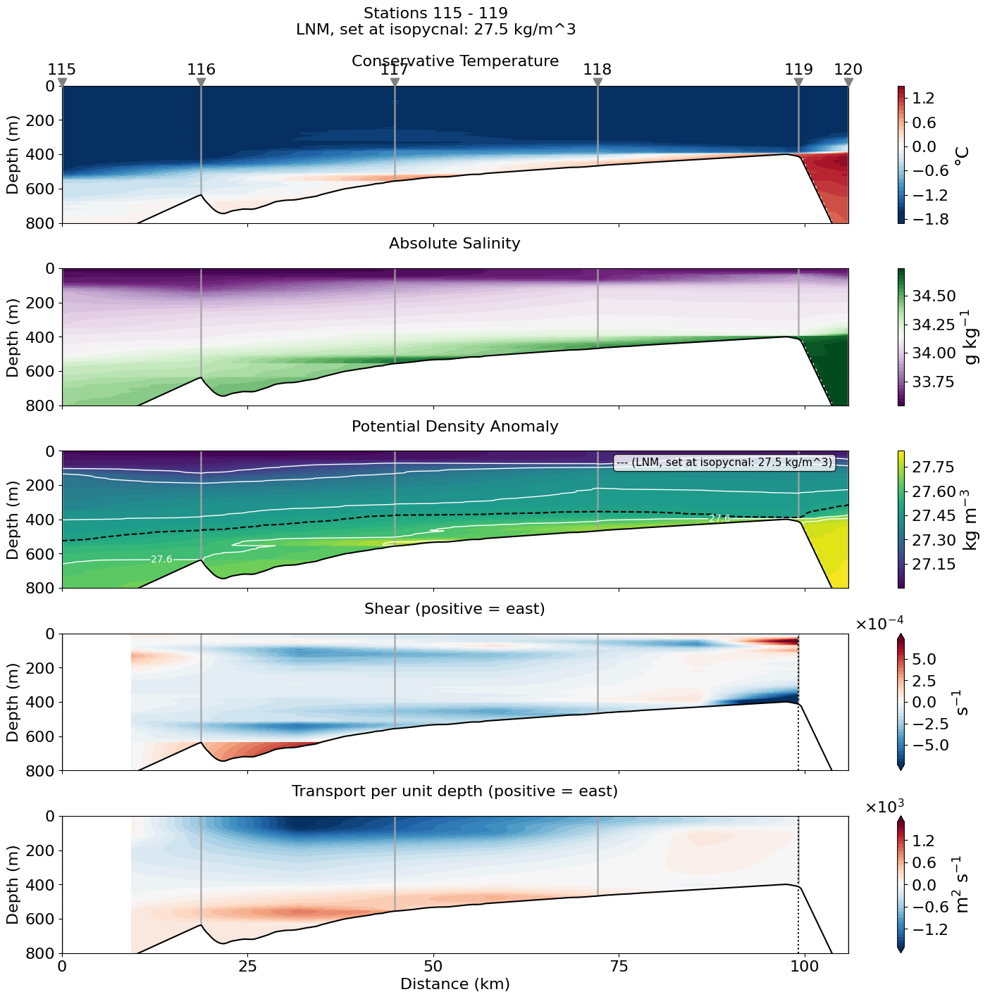

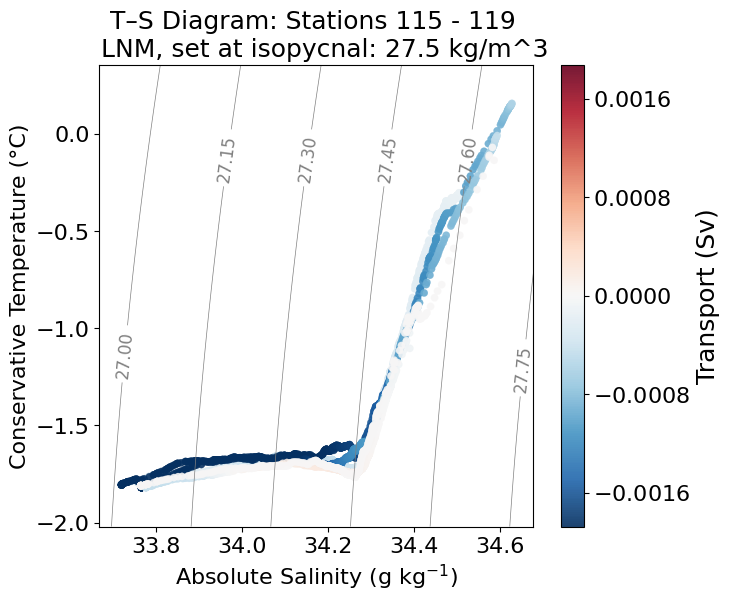

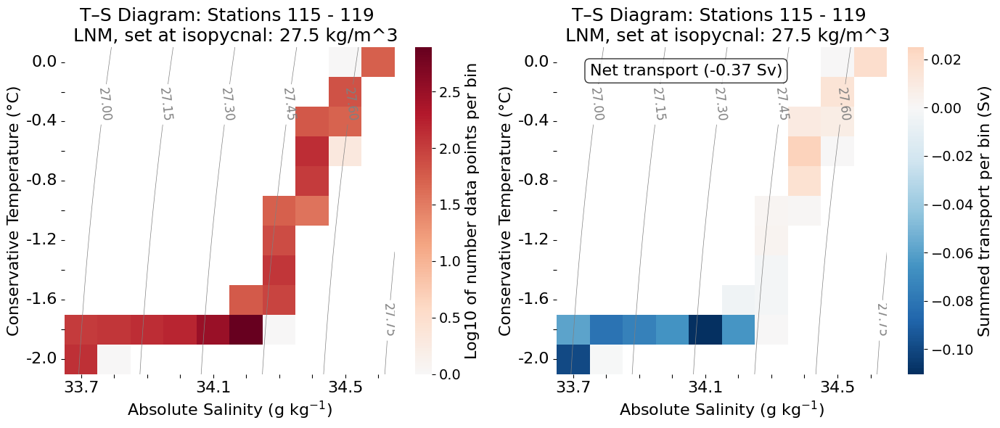

In [ ]:
#station cross sections
use = np.arange(115, 120+1, 1)
# use2 = np.arange(160, 164+1, 1)

#choose if the section is mostly latitude or longitude oriented
# maybe can partition by both later
latlon = 'lat'
latlon_label = "Latitude"
inflow  = "east"

# select data from stations in our use list
amdf_cross_sec = amdf.loc[amdf['sta'].isin(use),:]
lat_119 = amdf_cross_sec.loc[amdf_cross_sec.sta == 119, 'lat'].iloc[0]

isotherm_temp = None 
max_depth = 800
method = "lnm_isopycnal"
lnm_depth = None
isopycnal_dens = 27.5
max_latlon = lat_119 

# method: "zero_profile" (zero transport per station pair), "zero_section" (zero transport
# over the whole section), or "lnm" (level of no motion, set lnm_depth below)
# method = "lnm_isotherm"


title = "Stations 115 - 119" #, LNM = 400 m"

make_cross_sec_plots(amdf_cross_sec, latlon, latlon_label, inflow, use, max_depth, title, method = method, lnm_depth = lnm_depth, g = 9.81, rho = 1025, dz = 1, 
                    isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens, max_latlon=lat_119, x_axis="distance_km", tick_interval_km=25)


make_TS_plots(use, amdf_cross_sec, title, latlon, inflow,
              method=method, lnm_depth=lnm_depth, isotherm_temp=isotherm_temp, isopycnal_dens = isopycnal_dens, max_latlon=max_latlon)

df_west = cross_section_depth(use, amdf_cross_sec, lnm_depth, g=9.81, rho=1025, dz=1,
                               latlon=latlon, inflow=inflow, include_bottom_triangle=True,
                               isotherm_temp=isotherm_temp, isopycnal_dens = isopycnal_dens, max_latlon=max_latlon)


make_TS_heatmap(use, amdf_cross_sec, latlon, inflow, title, method = method, lnm_depth = lnm_depth, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens, max_latlon = max_latlon)


#### 159 - 164 

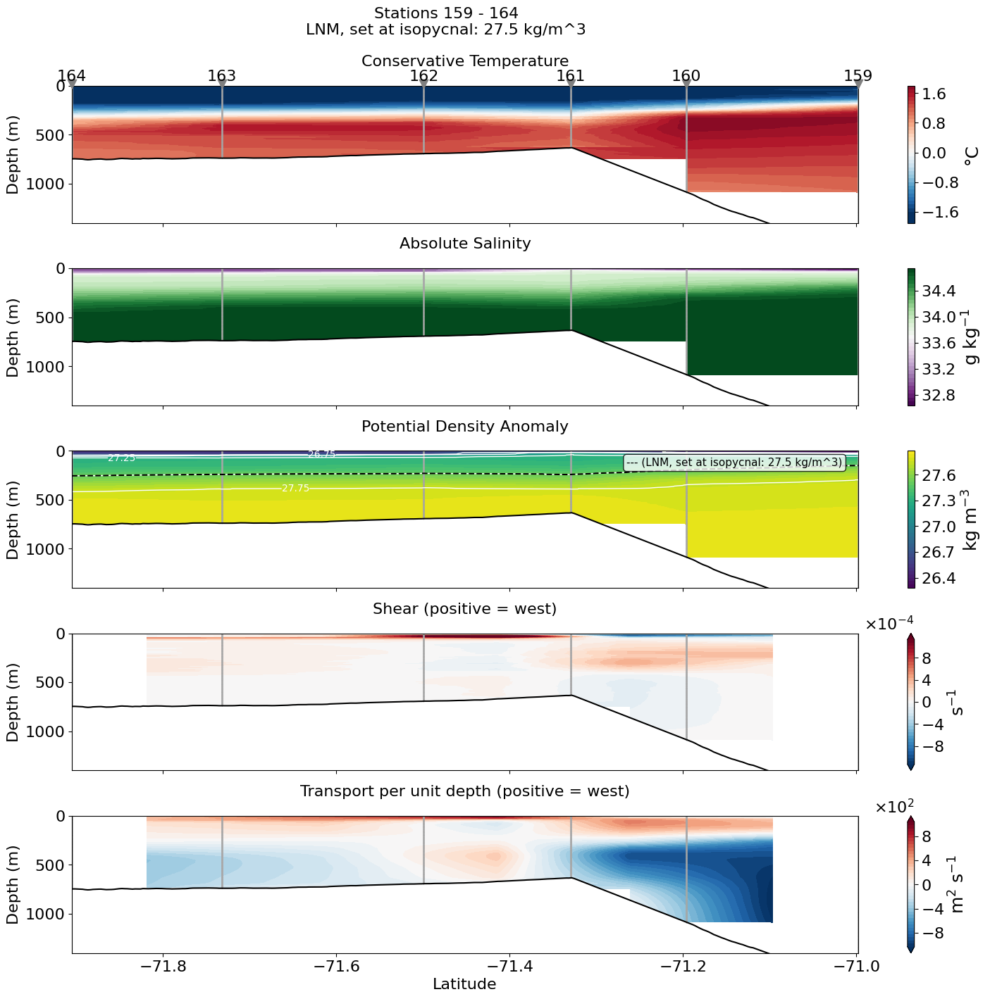

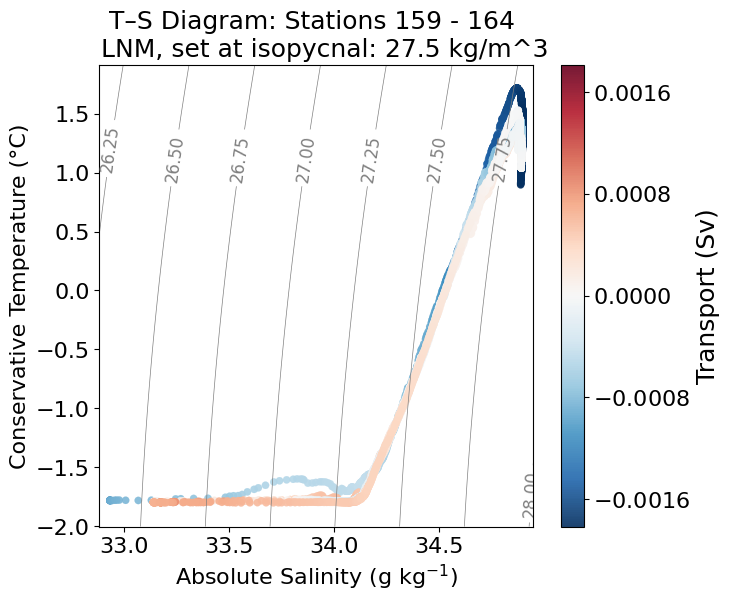

In [ ]:
#station cross sections
use = np.arange(159, 164+1, 1)

#choose if the section is mostly latitude or longitude oriented
# maybe can partition by both later
latlon = 'lat'
latlon_label = "Latitude"
inflow = "west"
# select data from stations in our use list
amdf_cross_sec = amdf.loc[amdf['sta'].isin(use),:]

# method: "zero_profile", "zero_section", or "lnm" (see method_config above)
isotherm_temp = None 
max_depth = 1400
method = "lnm_isopycnal"
lnm_depth = None
isopycnal_dens = 27.5

title = "Stations 159 - 164"

make_cross_sec_plots(amdf_cross_sec, latlon, latlon_label, inflow, use, max_depth, title, method = method, lnm_depth = lnm_depth, g = 9.81, rho = 1025, dz = 1, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens)
make_TS_plots(use, amdf_cross_sec, title, latlon, inflow, method = method, lnm_depth = lnm_depth, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens)

# pair_df = cross_section_depth(use, amdf, lnm_depth = 400, g = 9.81, rho = 1025, dz = 1, latlon = latlon, inflow = inflow, isotherm_temp = 0.0)
# plot_net_transport(pair_df, "net transport per pair 159 - 164")



#### 108 - 113 

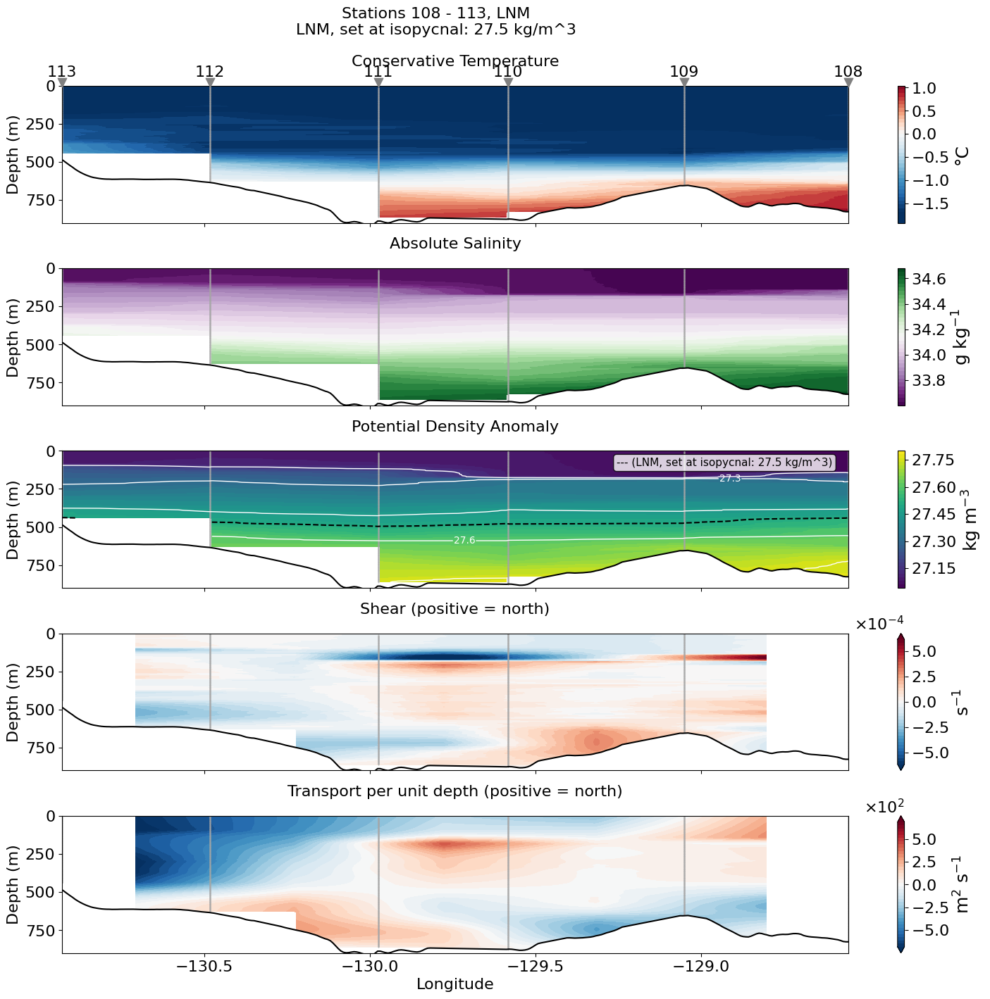

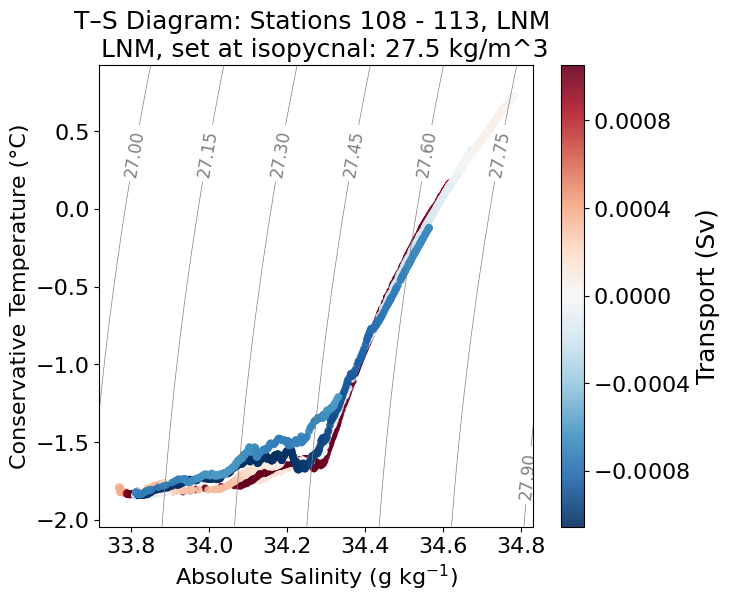

In [ ]:
#station cross sections
use = np.arange(108, 113+1, 1)

#choose if the section is mostly latitude or longitude oriented
# maybe can partition by both later
latlon = 'lon'
latlon_label = "Longitude"
inflow = None
# select data from stations in our use list
amdf_cross_sec = amdf.loc[amdf['sta'].isin(use),:]

# method: "zero_profile", "zero_section", or "lnm" (see method_config above)
isotherm_temp = None 
max_depth = 900
method = "lnm_isopycnal"
lnm_depth = None
isopycnal_dens = 27.5
title = "Stations 108 - 113, LNM"

make_cross_sec_plots(amdf_cross_sec, latlon, latlon_label, inflow, use, max_depth, title, method = method, lnm_depth = lnm_depth, g = 9.81, rho = 1025, dz = 1, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens)
make_TS_plots(use, amdf_cross_sec, title, latlon, inflow, method = method, lnm_depth = lnm_depth, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens)

pair_df = cross_section_depth(use, amdf,lnm_depth = 400, g = 9.81, rho = 1025, dz = 1, latlon = latlon, inflow = inflow, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens)
# plot_net_transport(pair_df, "net transport per pair 108 - 113")

#### 135 - 157 

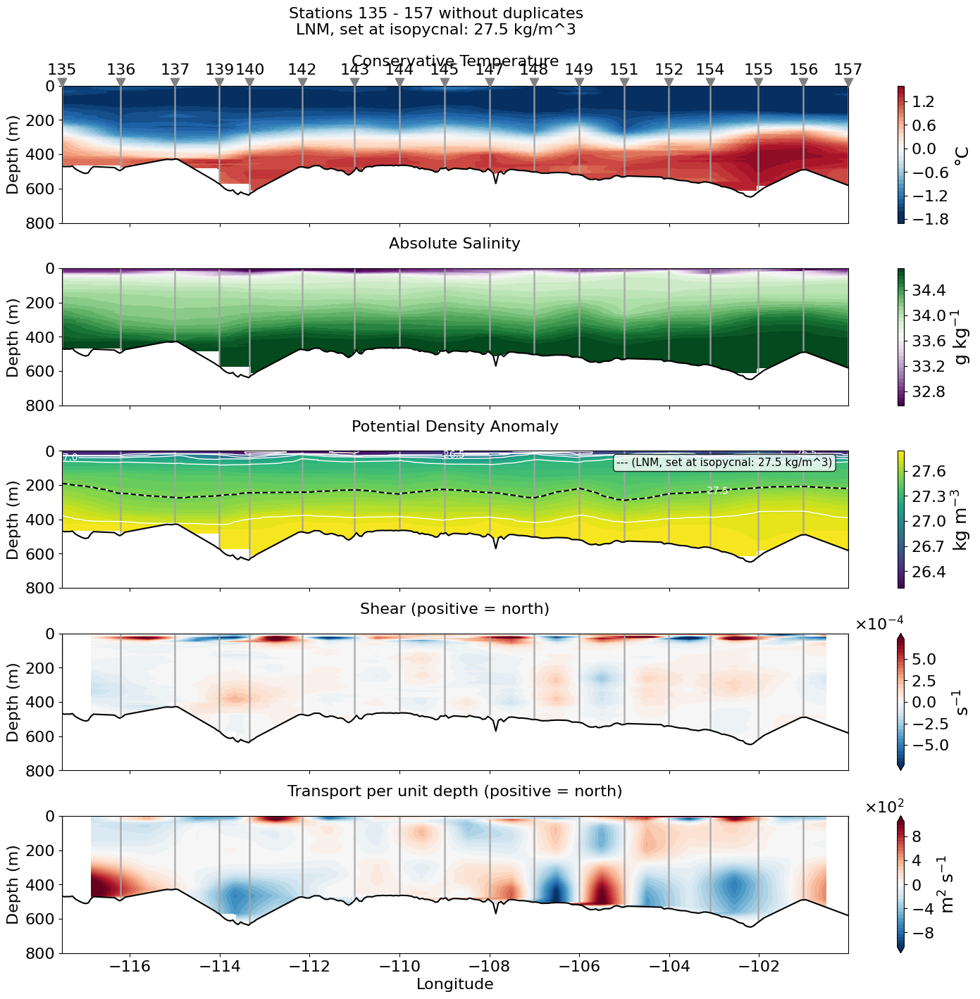

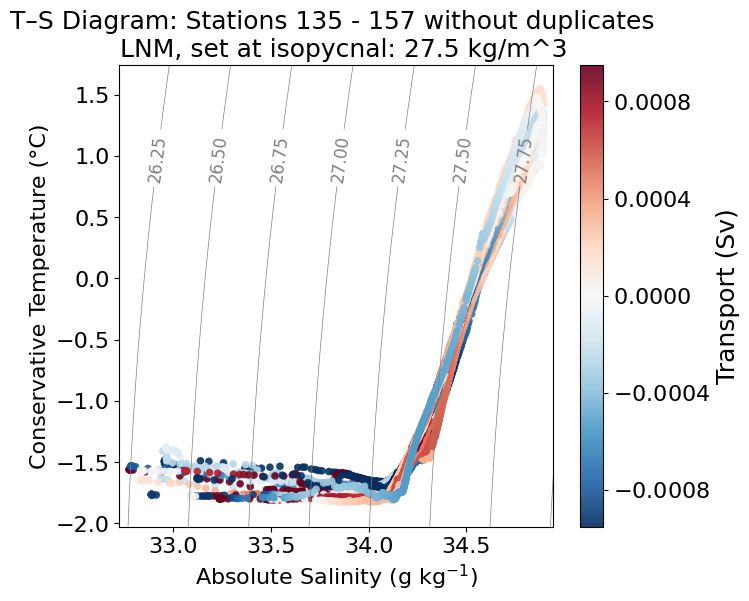

In [ ]:
use1_shelf = np.array([118, 119, 122, 123, 125, 126, 127])
use2_shelf = np.array([135, 136, 137, 139, 140, 142, 143, 144, 145, 147, 148, 149, 151, 152, 154, 155, 156, 157])
# use3_shelf = np.array([98,129,131,132,133,134,40,41,43])
use = np.hstack([use2_shelf])

latlon = 'lon'
latlon_label = "Longitude"

# select data from stations in our use list
amdf_cross_sec = amdf.loc[amdf['sta'].isin(use),:]
inflow = None
isotherm_temp = None 
max_depth = 800
method = "lnm_isopycnal"
lnm_depth = None
isopycnal_dens = 27.5
title = "Stations 135 - 157 without duplicates"

make_cross_sec_plots(amdf_cross_sec, latlon, latlon_label, inflow, use, max_depth, title, method = method, lnm_depth = lnm_depth, g = 9.81, rho = 1025,  dz = 1, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens)
make_TS_plots(use, amdf_cross_sec, title, latlon, inflow, method = method, lnm_depth = lnm_depth, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens)

pair_df = cross_section_depth(use, amdf, lnm_depth = 400, g = 9.81, rho = 1025, dz = 1, latlon = latlon, inflow = inflow,isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens)
# plot_net_transport(pair_df, "net transport per pair 135 - 157")

### ice shelves

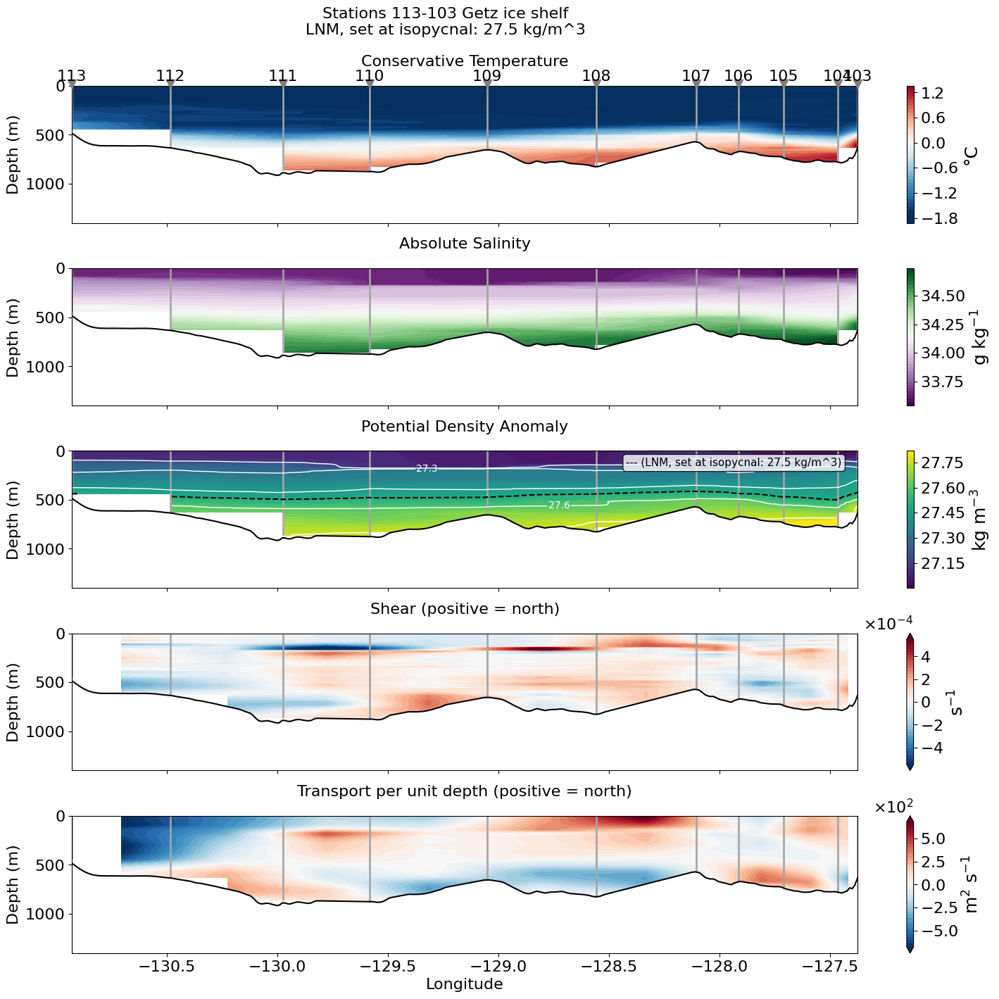

In [ ]:
use_ice = np.array(np.arange(103, 113 +1, 1))
use = np.hstack([use_ice])

latlon = 'lon'
latlon_label = "Longitude"

# select data from stations in our use list
amdf_cross_sec = amdf.loc[amdf['sta'].isin(use),:]
inflow = "north"
isotherm_temp = None 
max_depth = 1400
method = "lnm_isopycnal"
lnm_depth = None
isopycnal_dens = 27.5

title = "Stations 113-103 Getz ice shelf"

make_cross_sec_plots(amdf_cross_sec, latlon, latlon_label, inflow, use, max_depth, title, method = method, lnm_depth = lnm_depth, g = 9.81, rho = 1025,  dz = 1, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens)


    it's interesting how the deeper western iceshelf front has clearly more cdw access, increased surface meltwater 

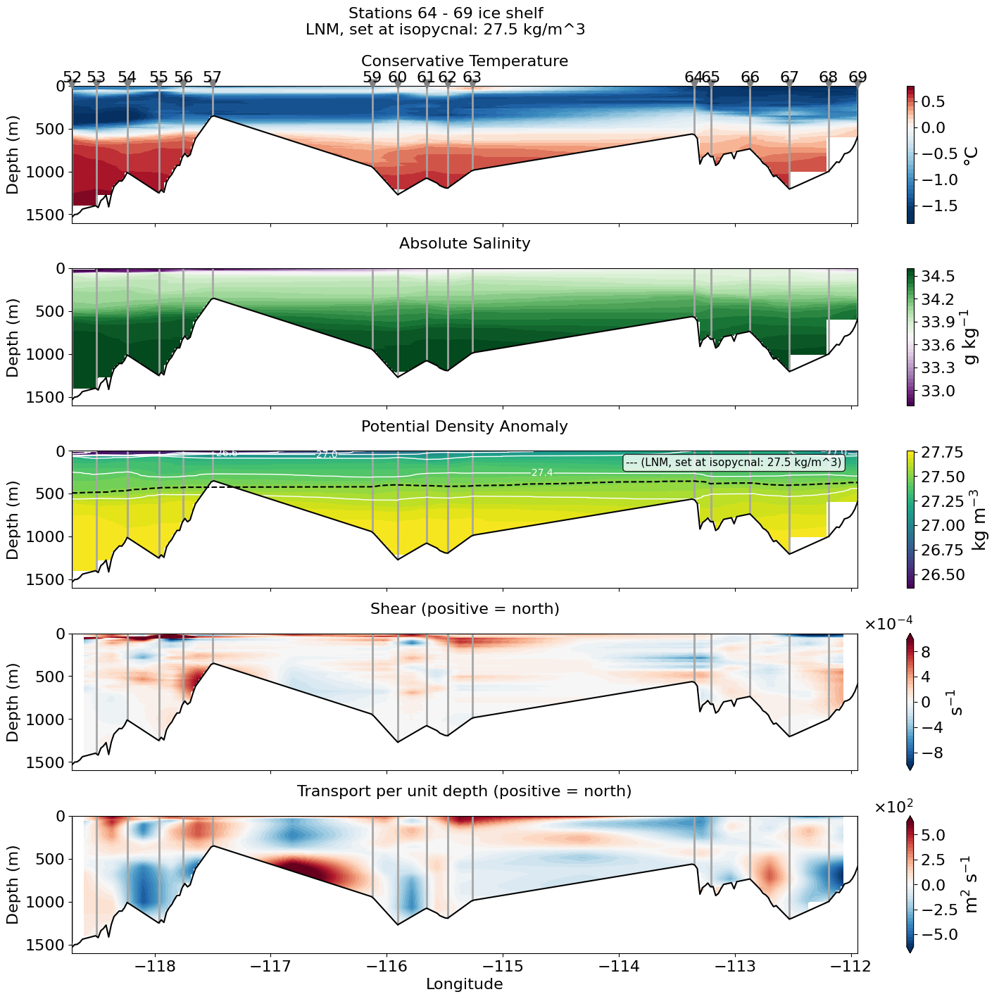

In [ ]:

use_ice_west = np.array(np.arange(52, 57 +1, 1))
use_ice_middle = np.array(np.arange(59, 63 +1, 1))
use_ice_east = np.array(np.arange(64, 69 +1, 1))

use = np.hstack([use_ice_west, use_ice_middle, use_ice_east])

latlon = 'lon'
latlon_label = "Longitude"

# select data from stations in our use list
amdf_cross_sec = amdf.loc[amdf['sta'].isin(use),:]
inflow = "north"
isotherm_temp = None 
max_depth = 1600
method = "lnm_isopycnal"
lnm_depth = None
isopycnal_dens = 27.5

title = "Stations 64 - 69 ice shelf"

make_cross_sec_plots(amdf_cross_sec, latlon, latlon_label, inflow, use, max_depth, title, method = method, lnm_depth = lnm_depth, g = 9.81, rho = 1025,  dz = 1, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens)


# Creating a box

- I want to create a rough box of transports across the shelf and along the shelf 
- This will be helpful to see the transport from open ocean the the shelf (along shelf section) and transport from other shelf seas into and out of the Amundsen (cross shelf sections)
- I may later need to add in the ice shelf sections to add a fourth boundary, start with just the three sides for now
- natural boundaries to constrain flow set by the bottom, surface, and ice shelves 


In [ ]:
# separated by longitude, along shelf 
# use_shelf_box = np.array([119, 122, 123, 125, 126, 127, 99, 98, 129, 131, 40, 132, 41, 133, 43, 134, 45])

# # separated by latitude, cross shelf 
# use_west_box = np.array([119, 118, 117, 116, 115])
# use_east_box = np.array([45, 46, 47, 48, 49, 95, 94, 93, 69])
# use_openbox = np.hstack([use_west_box, use_east_box, use_shelf_box])

use_shelf_box = np.array([120, 122, 123, 124, 126, 127,  99,  98, 129,  130, 40, 132, 42, 133, 43, 134, 44])

# separated by latitude, cross shelf 
use_west_box = np.array([120, 119, 118, 117, 116, 115])
use_east_box = np.array([44, 45, 46, 47, 48, 49, 95, 94, 93, 69])
use_openbox = np.hstack([use_west_box, use_east_box, use_shelf_box])


use_ice1 = np.array(np.arange(103, 115 +1, 1))
use_ice2 = np.array([96])
use_ice3 = np.array(np.arange(52, 57 +1, 1))
use_ice4 = np.array(np.arange(59, 69 +1, 1))
use_ice = np.hstack([use_ice1, use_ice2, use_ice3, use_ice4])
use_closedbox = np.hstack([use_west_box, use_east_box, use_shelf_box, use_ice])




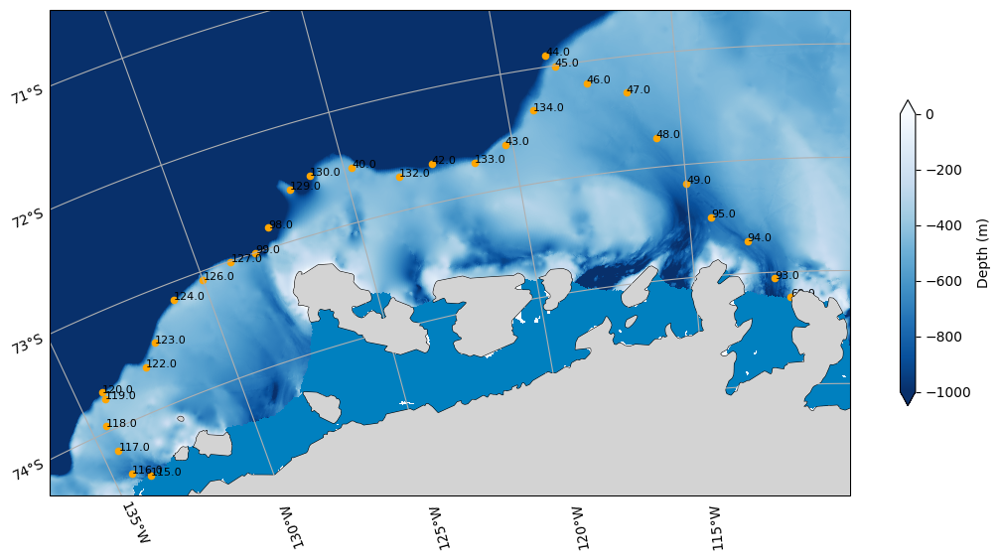

In [ ]:
#%%
# 3. Setup the Figure and Projection
fig = plt.figure(figsize=(13, 8))
#ax = plt.axes(projection=ccrs.Orthographic(central_longitude=20, central_latitude=65))

ax = fig.add_subplot(1, 1, 1, projection=ccrs.SouthPolarStereo(central_longitude=-110))

lon_min = -133
lon_max = -110
lat_min = -74.8
lat_max = -71.7

ax.set_extent([lon_min, lon_max, lat_min, lat_max], ccrs.PlateCarree())

pth = '/home/edworak/eady-data1/Palmer/'
ds = xr.open_dataset(pth+'gebco_2025_sub_ice.nc')


# 2. Subset to the Barents Sea (if the file is global)
# GEBCO variables are usually named 'elevation' or 'z'
amsjo = ds.sel(lon=slice(-150, -90), lat=slice(-76, -68))


# 4. Plot Bathymetry
# We use 'Blues_r' for ocean depth and set a robust range
plot = amsjo.elevation.plot(
    ax=ax, 
    transform=ccrs.PlateCarree(), 
    cmap='Blues_r', 
    vmin=-1000, vmax=0,  # Barents Sea is relatively shallow (~230m avg)
    cbar_kwargs={'label': 'Depth (m)', 'shrink': 0.5,},
    zorder=0,)

ax.contourf(Lon, Lat, shelf, levels=[2,2.01], transform=ccrs.PlateCarree(),cmap='winter')

# just for shelf section plot 
amdf_box = amdf.loc[amdf['sta'].isin(use_openbox),:]
fdf_sel = amdf_box.drop_duplicates(subset=['sta'], keep='first')


ax.scatter(fdf_sel['lon'],fdf_sel['lat'],
             c='orange',marker='o',s=20,
             label='NBP0702 Stations',transform=ccrs.PlateCarree(), )


for i,row in fdf_sel.iterrows():
        ax.text(row['lon'],row['lat'],str(row['sta']), fontsize = 8, transform=ccrs.PlateCarree())

    
# 5. Add Map Features
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.LAND, facecolor='lightgrey',zorder=10)
ax.add_feature(cfeature.BORDERS, linestyle=':', alpha=0.5)

# Add gridlines
gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
gl.top_labels = False
gl.right_labels = False


#plt.title('North Sea Fixed or Floating', fontsize=14)
ax.set_aspect(1)
plt.show()


### three sided box  

#### along shelf

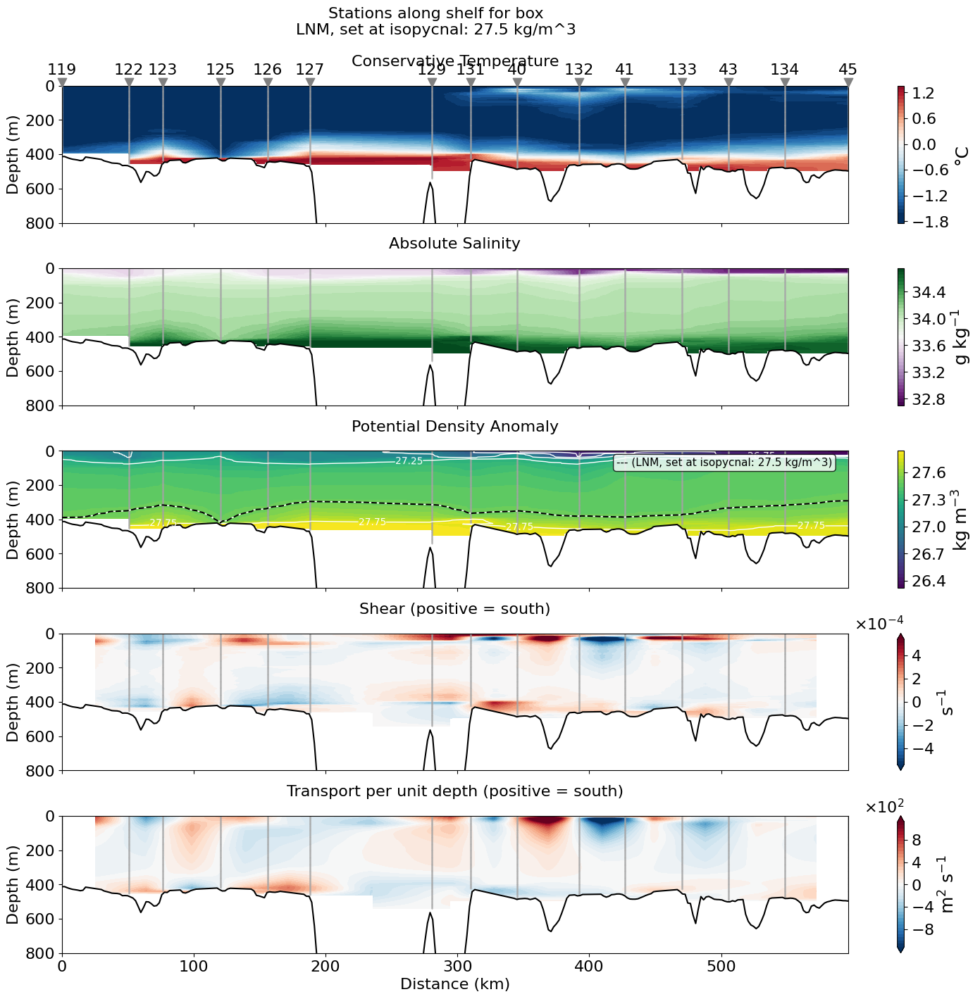

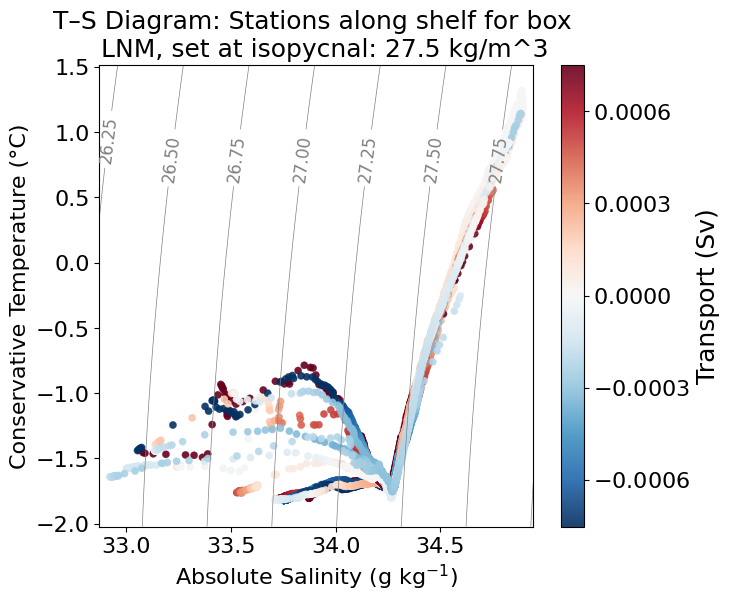

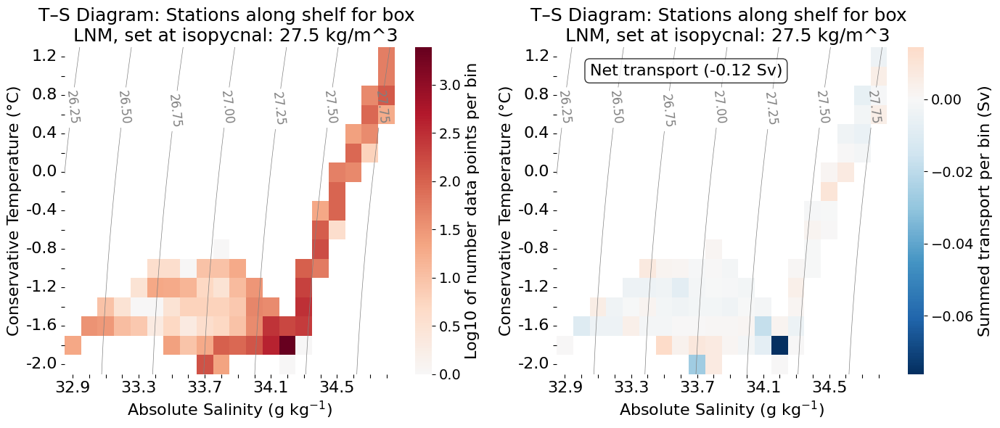

In [ ]:
# separated by longitude, along shelf
# use_shelf_box = np.array([122, 123, 125, 126, 127, 99, 98, 128, 129, 130, 131, 40, 132, 41, 133, 43, 134, 45])

#change 41 onshelf for 42 offshelf ? 
#change 125 onshelf for 124 offshelf ? 

# shallow 
use_shelf_box = np.array([119, 122, 123, 125, 126, 127,   129, 131, 40, 132, 41, 133, 43, 134, 45])

# deep 
# use_shelf_box = np.array([120, 122, 123, 124, 126, 127,  99, 98, 128,  130, 40,  42, 133, 43, 134, 44])

# middle? 
# use_shelf_box = np.array([120, 122, 123, 124, 126, 127,  99,  129,  130, 40, 132, 42, 133, 43, 134, 44])


use = np.hstack([use_shelf_box])

#choose if the section is mostly latitude or longitude oriented
# maybe can partition by both later
latlon = 'lon'
latlon_label = "Longitude"

# select data from stations in our use list
amdf_cross_sec = amdf.loc[amdf['sta'].isin(use),:]
inflow = "south"
isotherm_temp = None 
max_depth = 800
method = "lnm_isopycnal"
lnm_depth = None
isopycnal_dens = 27.5
title = "Stations along shelf for box"
max_latlon = None 

make_cross_sec_plots(amdf_cross_sec, latlon, latlon_label, inflow, use, max_depth, title, method = method, lnm_depth = lnm_depth,  g = 9.81, rho = 1025, dz = 1, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens, x_axis="distance_km", tick_interval_km=100) 
# plot_lnm_sensitivity(use, amdf, latlon, title, depths=range(300, 700, 100), g=10, rho=1000, dz=1, isotherm_temp = 0.0)
make_TS_plots(use, amdf_cross_sec, title, latlon, inflow, method = method, lnm_depth = lnm_depth, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens)

df_shelf = cross_section_depth(use, amdf_cross_sec, lnm_depth = lnm_depth, g = 9.81, rho = 1025, dz = 1, latlon = latlon, inflow = inflow, include_bottom_triangle=True, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens)

# make_TS_heatmap(df_shelf, title = title, method = method, lnm_depth = lnm_depth, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens)
make_TS_heatmap(use, amdf_cross_sec, latlon, inflow = inflow, title = title, method = method, lnm_depth = lnm_depth, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens, max_latlon = max_latlon)



#### east cross-shelf 

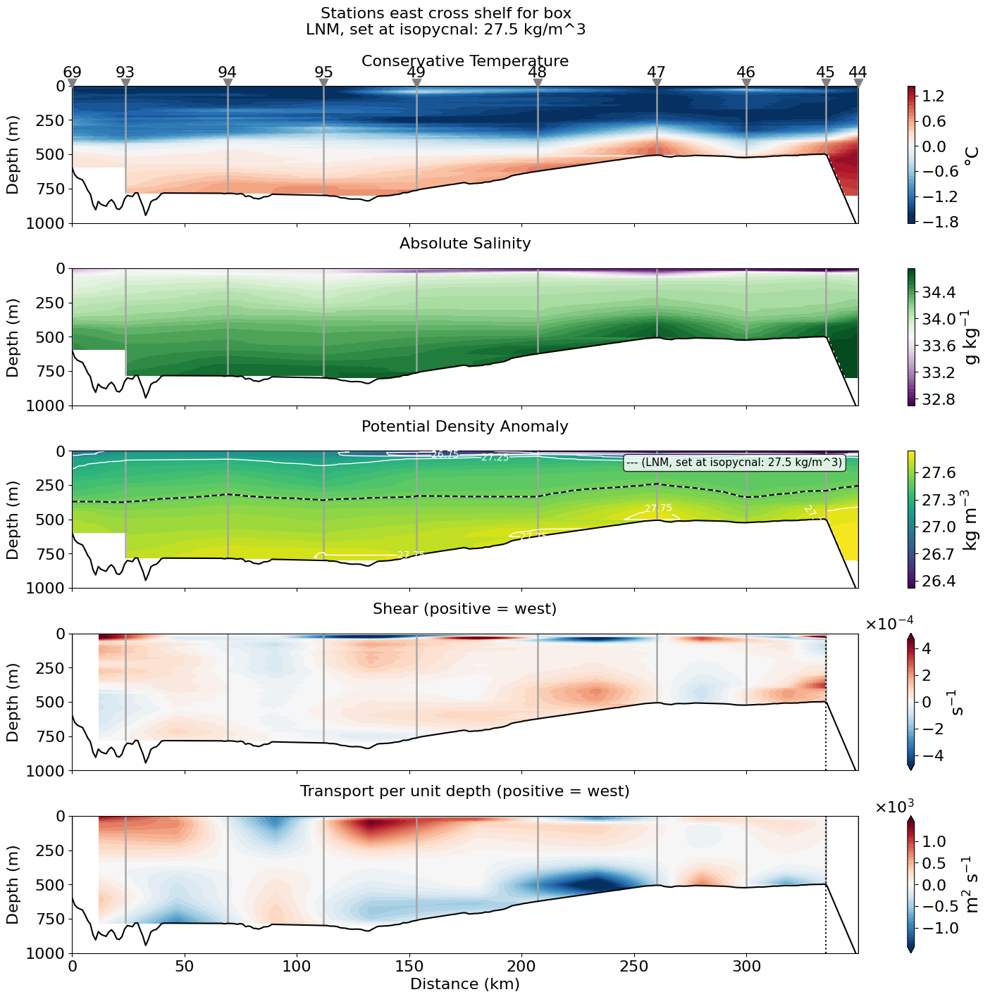

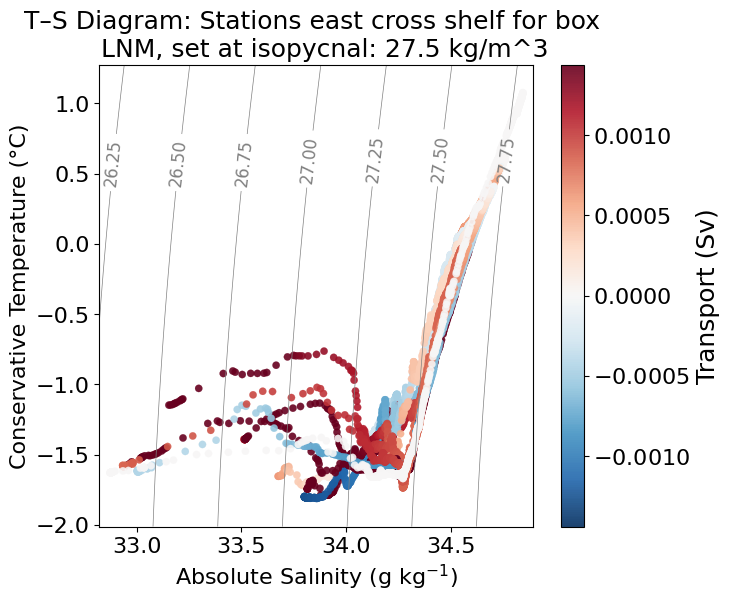

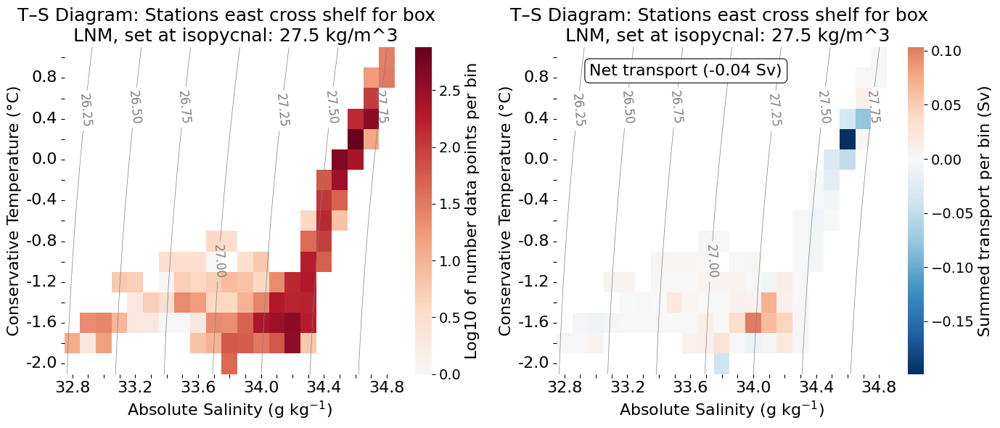

In [ ]:

# separated by latitude, cross shelf
# use_east_box = np.array([44, 45, 46, 47, 48, 49, 95, 94, 93, 69])
use_east_box = np.array([69, 93,94, 95,  49, 48, 47, 46, 45, 44])


use = np.hstack([use_east_box])

#choose if the section is mostly latitude or longitude oriented
# maybe can partition by both later
latlon = 'lat'
latlon_label = "Latitude"
# select data from stations in our use list
amdf_cross_sec = amdf.loc[amdf['sta'].isin(use),:]
lat_45 = amdf_cross_sec.loc[amdf_cross_sec.sta == 45, 'lat'].iloc[0]

amdf_cross_sec = amdf.loc[amdf['sta'].isin(use),:]
inflow = "west"
isotherm_temp = None 
max_depth = 1000
method = "lnm_isopycnal"
lnm_depth = None
isopycnal_dens = 27.5
max_latlon = lat_45
title = "Stations east cross shelf for box"

make_cross_sec_plots(amdf_cross_sec, latlon, latlon_label, inflow, use, max_depth, title, method = method, lnm_depth = lnm_depth, g = 9.81, rho = 1025, dz = 1, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens, max_latlon = max_latlon, x_axis="distance_km", tick_interval_km=50) 
# plot_lnm_sensitivity(use, amdf, latlon, title, depths=range(300, 500, 50), g=10, rho=1000, dz=1, isotherm_temp = 0.0)
make_TS_plots(use, amdf_cross_sec, title, latlon, inflow, method = method, lnm_depth = lnm_depth, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens, max_latlon = max_latlon)

# df_east = cross_section_depth(use, amdf_cross_sec, lnm_depth = lnm_depth, g = 9.81, rho = 1025, dz = 1, latlon = latlon, inflow = inflow, include_bottom_triangle=True, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens, max_latlon = lat_45)
# make_TS_heatmap(df_east, title = title, method = method, lnm_depth = lnm_depth, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens)

make_TS_heatmap(use, amdf_cross_sec, latlon, inflow, title, method = method, lnm_depth = lnm_depth, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens, max_latlon = max_latlon)


### TS heatmap combined 


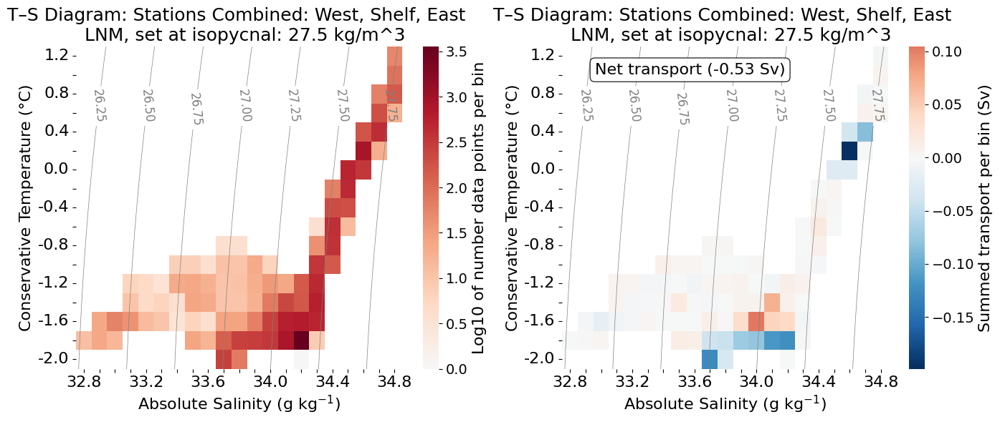

In [ ]:
# make_TS_heatmap(pair_df, title, method = "lnm_isotherm", lnm_depth = 400, isotherm_temp = None)
method = "lnm_isopycnal"
isotherm_temp = None # -0.5 
isopycnal_dens = 27.5 

# --- west section (stations 115-120) ---
use_west = np.arange(115, 120+1, 1)
amdf_west = amdf.loc[amdf['sta'].isin(use_west),:]

# --- shelf section (along-shelf box) ---
use_shelf = np.array([120, 122, 123, 125, 126, 127,  99,  129, 130, 131, 40, 132, 41, 133, 43, 134, 44])
use_shelf = np.hstack([use_shelf_box])
amdf_shelf= amdf.loc[amdf['sta'].isin(use_shelf),:]

# --- east section (cross-shelf box) ---
use_east = np.array([69, 93,94, 95,  49, 48, 47, 46, 45, 44])
use_east = np.hstack([use_east_box])
amdf_east = amdf.loc[amdf['sta'].isin(use_east),:]


use_sections = [use_east, use_shelf, use_west]
amdf_sections = [amdf_east, amdf_shelf, amdf_west]

title = "Stations Combined: West, Shelf, East"
max_latlon = [lat_45, None, lat_119]  # matches use_sections order: [east, shelf, west]
inflow = ["west", "south", "east"]    # matches use_sections order: [east, shelf, west]
lnm_depth = [None, None, None]
latlon = ["lat", "lon", "lat"]

make_TS_heatmap(use_sections, amdf_sections, latlon, inflow, title, method = method, lnm_depth = lnm_depth, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens, max_latlon = max_latlon)



# Smaller Box 
- having issues with constraining shelf transports 

In [ ]:
# separated by longitude, along shelf 
use_shelf_box = np.array([119, 122, 123, 125, 126, 127, 99])

# separated by latitude, cross shelf 
use_west_box = np.array([119, 118, 117, 116, 115])
use_east_box = np.array([99, 100, 101, 102, 103])

use_smallbox = np.hstack([use_west_box, use_east_box, use_shelf_box])

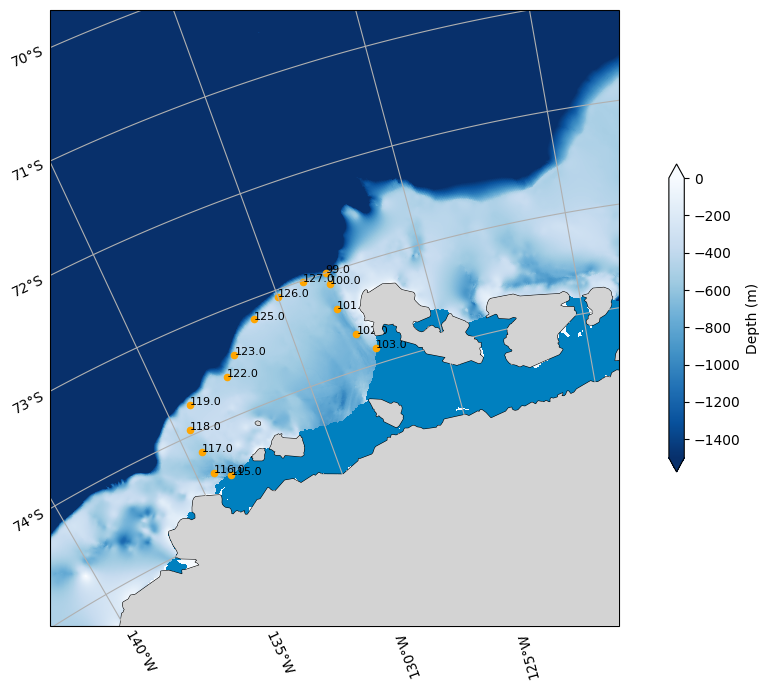

In [ ]:
# separated by longitude, along shelf 
use_shelf_box = np.array([119, 122, 123, 125, 126, 127, 99])

# separated by latitude, cross shelf 
use_west_box = np.array([119, 118, 117, 116, 115])
use_east_box = np.array([99, 100, 101, 102, 103])

use_smallbox = np.hstack([use_west_box, use_east_box, use_shelf_box])

# -----------------------------------------------

# 3. Setup the Figure and Projection
fig = plt.figure(figsize=(13, 8))
#ax = plt.axes(projection=ccrs.Orthographic(central_longitude=20, central_latitude=65))

ax = fig.add_subplot(1, 1, 1, projection=ccrs.SouthPolarStereo(central_longitude=-110))

lon_min = -135
lon_max = -120
lat_min = -76 
lat_max = -71

ax.set_extent([lon_min, lon_max, lat_min, lat_max], ccrs.PlateCarree())

pth = '/home/edworak/eady-data1/Palmer/'
ds = xr.open_dataset(pth+'gebco_2025_sub_ice.nc')


# 2. Subset to the Barents Sea (if the file is global)
# GEBCO variables are usually named 'elevation' or 'z'
amsjo = ds.sel(lon=slice(-150, -90), lat=slice(-76, -68))


# 4. Plot Bathymetry
# We use 'Blues_r' for ocean depth and set a robust range
plot = amsjo.elevation.plot(
    ax=ax, 
    transform=ccrs.PlateCarree(), 
    cmap='Blues_r', 
    vmin=-1500, vmax=0,  # Barents Sea is relatively shallow (~230m avg)
    cbar_kwargs={'label': 'Depth (m)', 'shrink': 0.5,},
    zorder=0,)

ax.contourf(Lon, Lat, shelf, levels=[2,2.01], transform=ccrs.PlateCarree(),cmap='winter')

# just for shelf section plot 
amdf_box = amdf.loc[amdf['sta'].isin(use_smallbox),:]
fdf_sel = amdf_box.drop_duplicates(subset=['sta'], keep='first')


ax.scatter(fdf_sel['lon'],fdf_sel['lat'],
             c='orange',marker='o',s=20,
             label='NBP0702 Stations',transform=ccrs.PlateCarree(), )


for i,row in fdf_sel.iterrows():
        ax.text(row['lon'],row['lat'],str(row['sta']), fontsize = 8, transform=ccrs.PlateCarree())

    
# 5. Add Map Features
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.LAND, facecolor='lightgrey',zorder=10)
ax.add_feature(cfeature.BORDERS, linestyle=':', alpha=0.5)

# Add gridlines
gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
gl.top_labels = False
gl.right_labels = False


#plt.title('North Sea Fixed or Floating', fontsize=14)
ax.set_aspect(1)
plt.show()



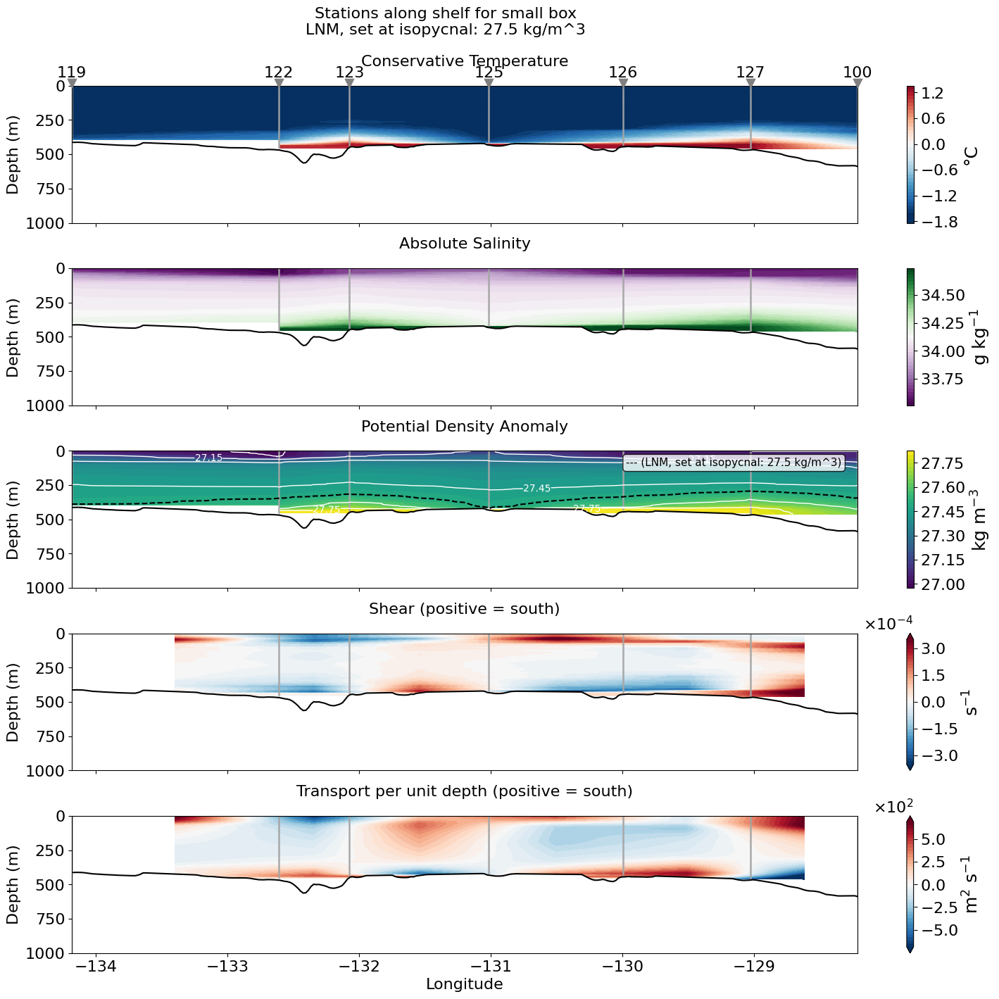

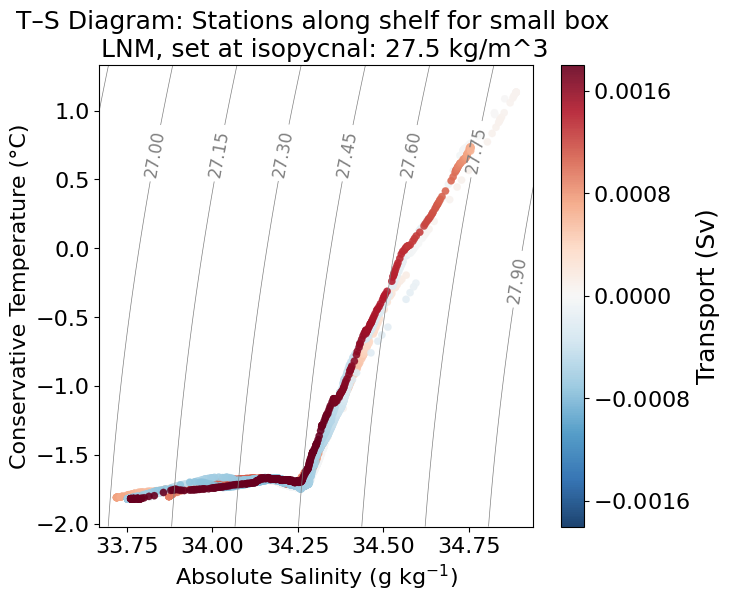

In [ ]:
# separated by longitude, along shelf
use_shelf_box = np.array([119, 122, 123, 125, 126, 127, 100])

use = np.hstack([use_shelf_box])

#choose if the section is mostly latitude or longitude oriented
# maybe can partition by both later
latlon = 'lon'
latlon_label = "Longitude"

amdf_cross_sec = amdf.loc[amdf['sta'].isin(use),:]
inflow = "south"
isotherm_temp = None 
max_depth = 1000
method = "lnm_isopycnal"
lnm_depth = None
isopycnal_dens = 27.5

title = "Stations along shelf for small box"

make_cross_sec_plots(amdf_cross_sec, latlon, latlon_label, inflow, use, max_depth, title, method = method, lnm_depth = lnm_depth,  g = 9.81, rho = 1025, dz = 1, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens) 
make_TS_plots(use, amdf_cross_sec, title, latlon, inflow, method = method, lnm_depth = lnm_depth, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens)


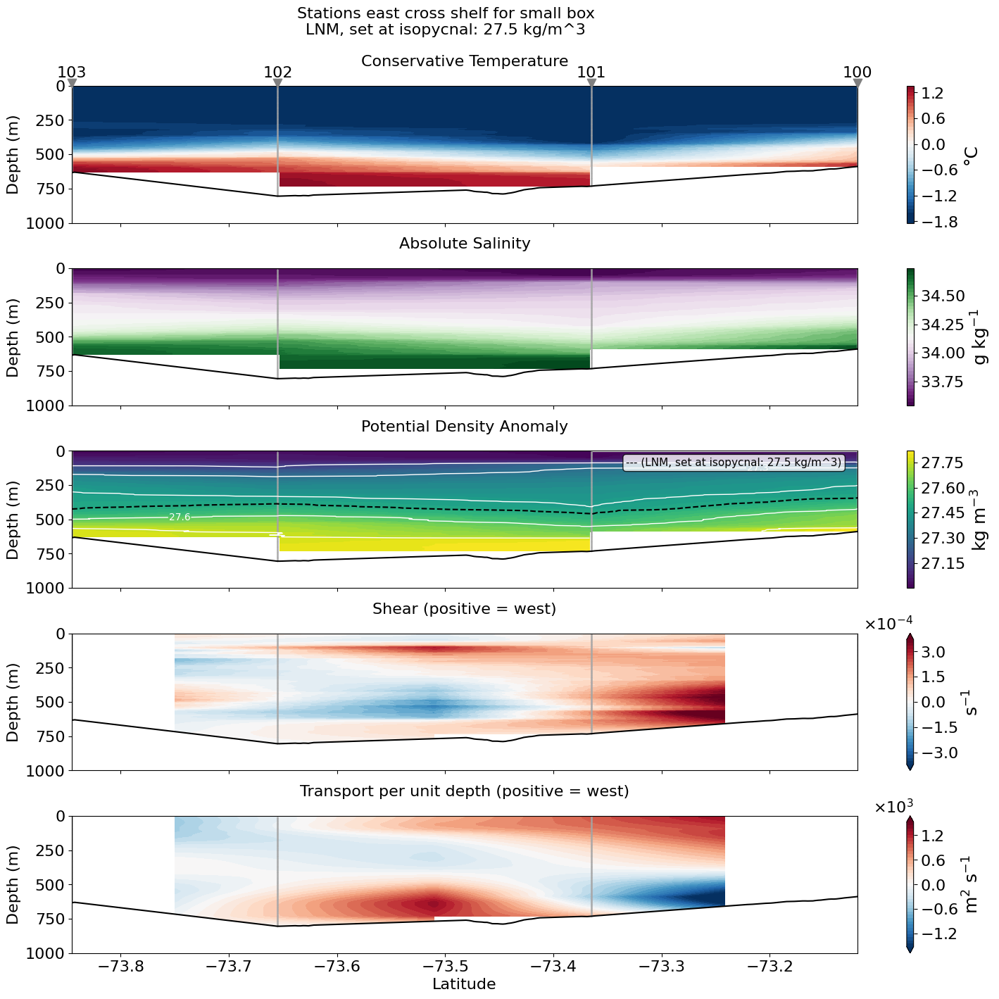

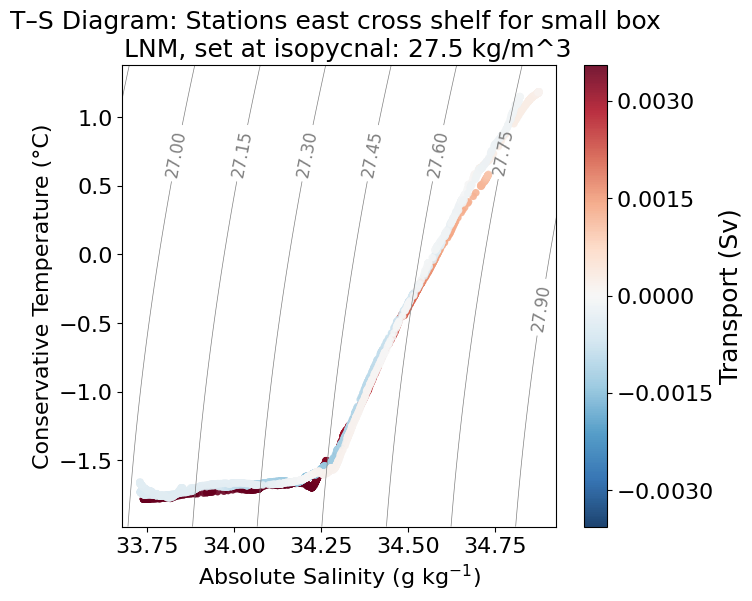

In [ ]:
# separated by latitude, cross shelf
use_east_box = np.array([100, 101, 102, 103])

use = np.hstack([use_east_box])

#choose if the section is mostly latitude or longitude oriented
# maybe can partition by both later
latlon = 'lat'
latlon_label = "Latitude"

amdf_cross_sec = amdf.loc[amdf['sta'].isin(use),:]
inflow = "west"
isotherm_temp = None 
max_depth = 1000
method = "lnm_isopycnal"
lnm_depth = None
isopycnal_dens = 27.5

title = "Stations east cross shelf for small box"

make_cross_sec_plots(amdf_cross_sec, latlon, latlon_label, inflow, use, max_depth, title, method = method, lnm_depth = lnm_depth,  g = 9.81, rho = 1025, dz = 1, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens) 
make_TS_plots(use, amdf_cross_sec, title, latlon, inflow, method = method, lnm_depth = lnm_depth, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens)

# huge shelf box 

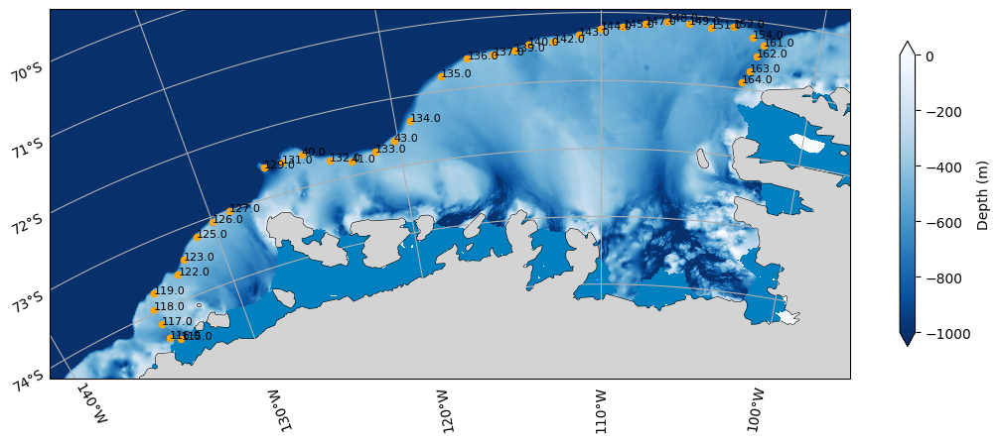

In [ ]:
#%%

use_west = np.arange(115, 119+1, 1)
use_shelf = np.array([119, 122, 123, 125, 126, 127, 129,131, 40, 132, 41, 133, 43, 134, 135, 136, 137, 139, 140, 142, 143, 144, 145, 147, 148, 149, 151, 152, 154, 161])
use_east = np.array([161, 162, 163, 164])
use_shelf = np.hstack([use_shelf])
use_east = np.hstack([use_east])

use_openbox = np.hstack([use_west, use_east, use_shelf])

# 3. Setup the Figure and Projection
fig = plt.figure(figsize=(13, 8))
#ax = plt.axes(projection=ccrs.Orthographic(central_longitude=20, central_latitude=65))

ax = fig.add_subplot(1, 1, 1, projection=ccrs.SouthPolarStereo(central_longitude=-110))

# lon_min = -133
# lon_max = -110
# lat_min = -74.8
# lat_max = -71.7

lon_min = -135
lon_max = -99
lat_min = -75 
lat_max = -70.6


ax.set_extent([lon_min, lon_max, lat_min, lat_max], ccrs.PlateCarree())

pth = '/home/edworak/eady-data1/Palmer/'
ds = xr.open_dataset(pth+'gebco_2025_sub_ice.nc')


# 2. Subset to the Barents Sea (if the file is global)
# GEBCO variables are usually named 'elevation' or 'z'
amsjo = ds.sel(lon=slice(-150, -90), lat=slice(-76, -68))


# 4. Plot Bathymetry
# We use 'Blues_r' for ocean depth and set a robust range
plot = amsjo.elevation.plot(
    ax=ax, 
    transform=ccrs.PlateCarree(), 
    cmap='Blues_r', 
    vmin=-1000, vmax=0,  # Barents Sea is relatively shallow (~230m avg)
    cbar_kwargs={'label': 'Depth (m)', 'shrink': 0.5,},
    zorder=0,)

ax.contourf(Lon, Lat, shelf, levels=[2,2.01], transform=ccrs.PlateCarree(),cmap='winter')

# just for shelf section plot 
amdf_box = amdf.loc[amdf['sta'].isin(use_openbox),:]
fdf_sel = amdf_box.drop_duplicates(subset=['sta'], keep='first')


ax.scatter(fdf_sel['lon'],fdf_sel['lat'],
             c='orange',marker='o',s=20,
             label='NBP0702 Stations',transform=ccrs.PlateCarree(), )


for i,row in fdf_sel.iterrows():
        ax.text(row['lon'],row['lat'],str(row['sta']), fontsize = 8, transform=ccrs.PlateCarree())

    
# 5. Add Map Features
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.LAND, facecolor='lightgrey',zorder=10)
ax.add_feature(cfeature.BORDERS, linestyle=':', alpha=0.5)

# Add gridlines
gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
gl.top_labels = False
gl.right_labels = False


#plt.title('North Sea Fixed or Floating', fontsize=14)
ax.set_aspect(1)
plt.show()


### very long shelf section 

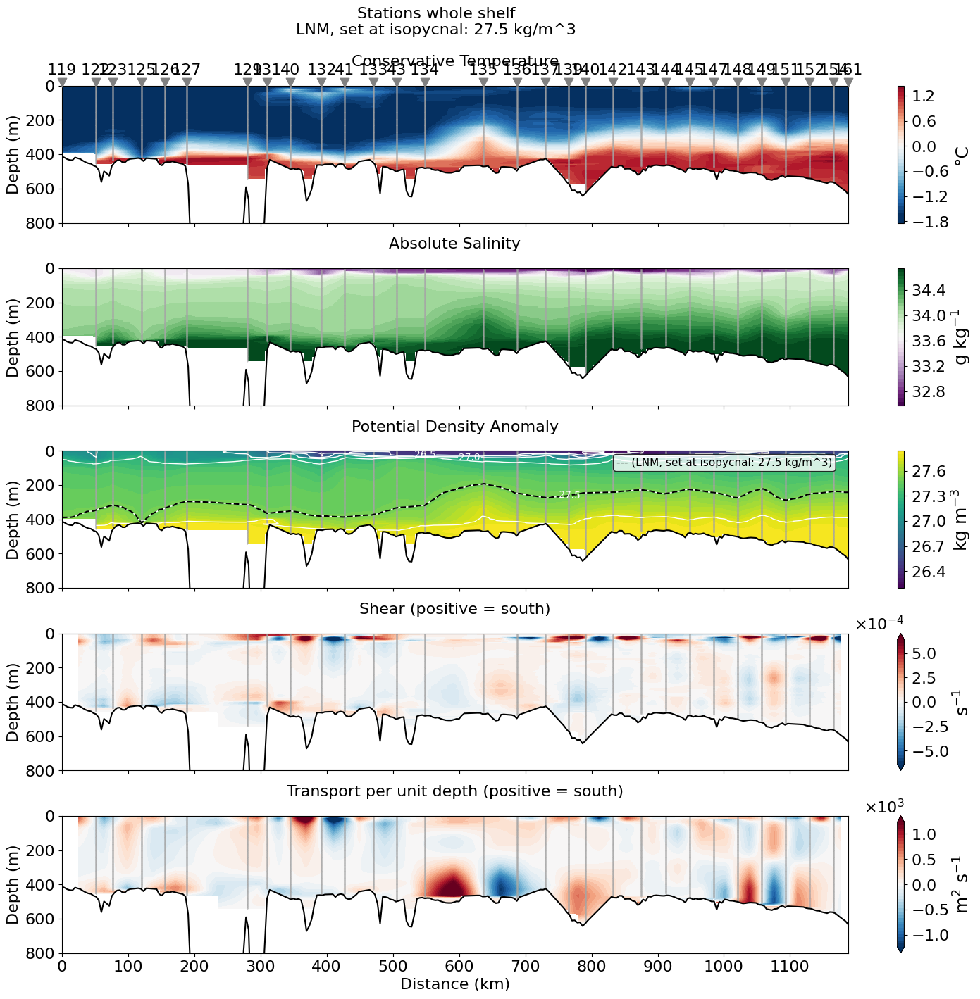

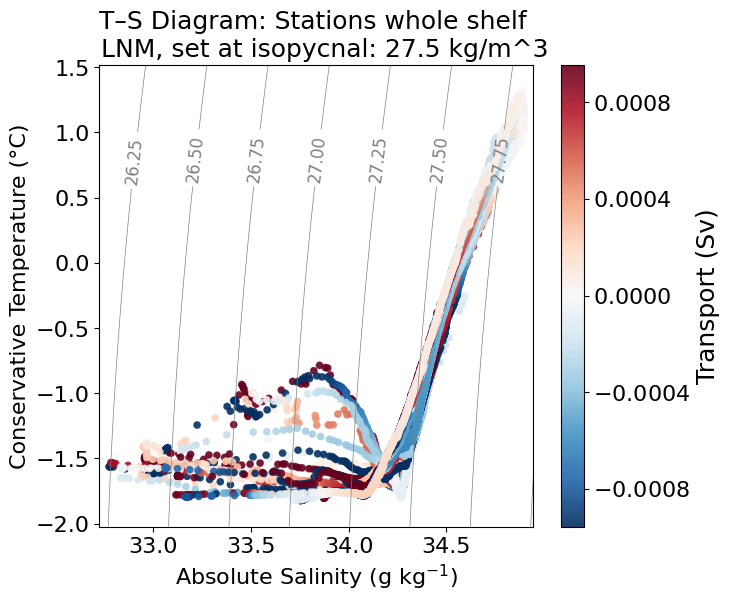

In [ ]:
# separated by latitude, cross shelf
# use1_shelf = np.array([118, 119, 122, 123, 125, 126, 127])
# use2_shelf = np.array([135, 136, 137, 139, 140, 142, 143, 144, 145, 147, 148, 149, 151, 152, 154, 155, 156, 157])
# use3_shelf = np.array([98,129,131,132,133,134,40,41,43])

# remove the spikes in density V structures 123, 127, 135, 149
# use_shelf = np.array([118, 119, 122, 125, 126,  129,131, 40, 132, 41, 133, 43, 134,  136, 137, 139, 140, 142, 143, 144, 145, 147, 148,  151, 152, 154, 155, 156])
use_shelf = np.array([119, 122, 123, 125, 126, 127, 129, 131, 40, 132, 41, 133, 43, 134, 135, 136, 137, 139, 140, 142, 143, 144, 145, 147, 148, 149, 151, 152, 154, 161])
use = np.hstack([use_shelf])


#choose if the section is mostly latitude or longitude oriented
# maybe can partition by both later
latlon = 'lon'
latlon_label = "Longitude"

amdf_cross_sec = amdf.loc[amdf['sta'].isin(use),:]
inflow = "south"
isotherm_temp = None 
max_depth = 800
method = "lnm_isopycnal"
lnm_depth = None
isopycnal_dens = 27.5


title = "Stations whole shelf"

make_cross_sec_plots(amdf_cross_sec, latlon, latlon_label, inflow, use, max_depth, title, method = method, lnm_depth = lnm_depth, g = 9.81, rho = 1025, dz = 1, 
                     isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens, x_axis="distance_km", tick_interval_km=100) 
# plot_lnm_sensitivity(use, amdf, latlon, title, depths=range(250, 500, 50), g=10, rho=1000, dz=1, isotherm_temp = 0.0)
make_TS_plots(use, amdf_cross_sec, title, latlon, inflow, method = method, lnm_depth = lnm_depth, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens)


# df_shelf = cross_section_depth(use, amdf_cross_sec, lnm_depth = lnm_depth, g = 9.81, rho = 1025, dz = 1, latlon = latlon, inflow = inflow, 
#                                include_bottom_triangle=True, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens)
# make_TS_heatmap(df_shelf, title = title, method = method, lnm_depth = lnm_depth, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens)


### very eastern cross shelf 

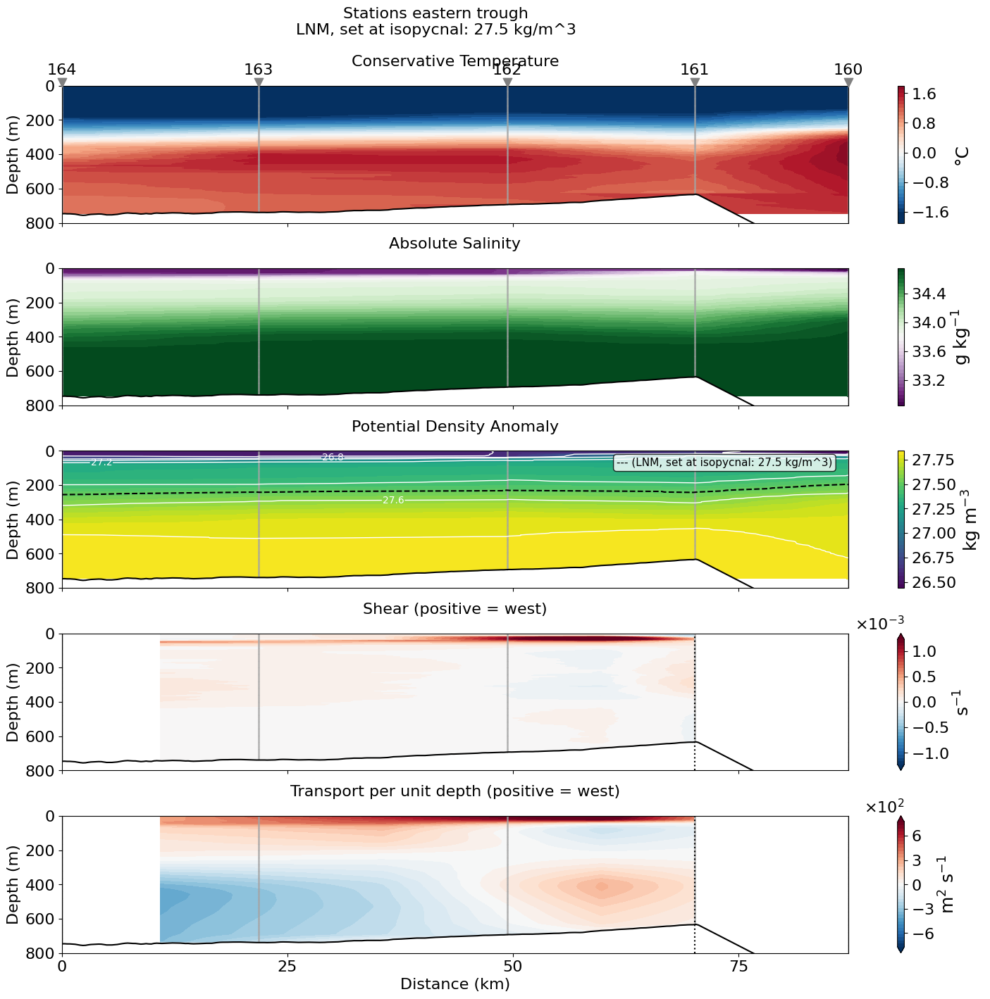

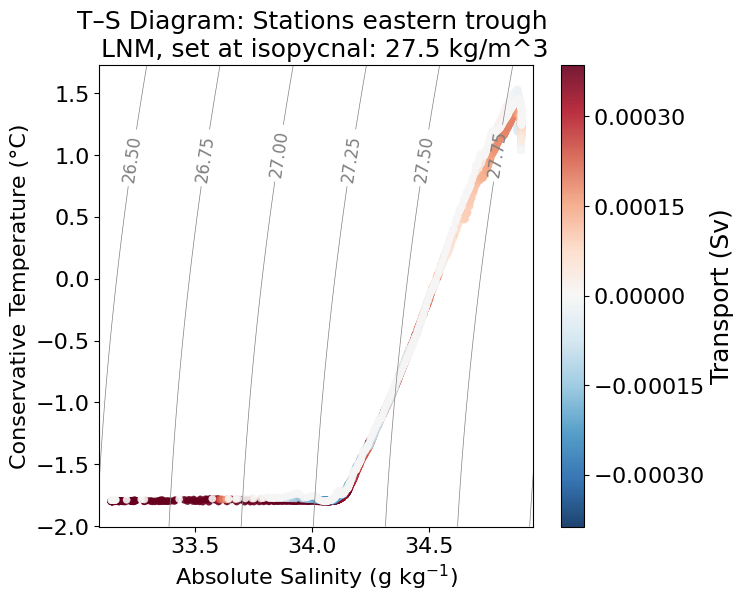

In [ ]:
# use_east = np.array([164, 163, 162, 155, 156])
# use_east = np.array([160, 161, 162, 163, 164])
use_east = np.array([164, 163, 162, 161, 160])

use = np.hstack([use_east])

#choose if the section is mostly latitude or longitude oriented
# maybe can partition by both later
latlon = 'lat'
latlon_label = "Latitude"
# select data from stations in our use list
amdf_cross_sec = amdf.loc[amdf['sta'].isin(use),:]
lat_161 = amdf_cross_sec.loc[amdf_cross_sec.sta == 161, 'lat'].iloc[0]

inflow = "west"
isotherm_temp = None 
max_depth = 800
method = "lnm_isopycnal"
lnm_depth = None
isopycnal_dens = 27.5
max_latlon = lat_161
title = "Stations eastern trough"


make_cross_sec_plots(amdf_cross_sec, latlon, latlon_label, inflow, use, max_depth, title, method = method, lnm_depth = lnm_depth, g = 9.81, rho = 1025, dz = 1, 
                     isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens, max_latlon = lat_161, x_axis="distance_km", tick_interval_km=25) 
make_TS_plots(use, amdf_cross_sec, title, latlon, inflow, method = method, lnm_depth = lnm_depth, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens, max_latlon = max_latlon)

# df_east = cross_section_depth(use, amdf_cross_sec, lnm_depth = lnm_depth, g = 9.81, rho = 1025, dz = 1, latlon = latlon, inflow = inflow, 
#                               include_bottom_triangle=True, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens, max_latlon = lat_161)
# make_TS_heatmap(df_east, title = title, method = method, lnm_depth = lnm_depth, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens)

# df_east.transport_per_depth_lnm_isotherm




### TS combined 

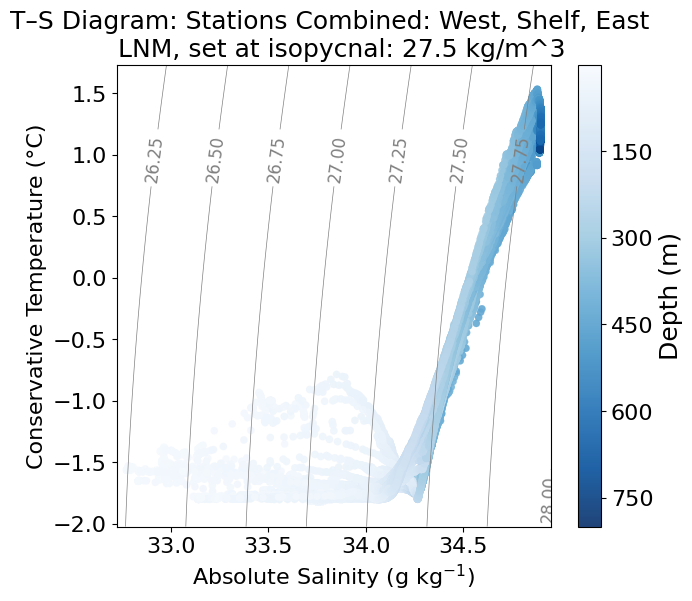

In [ ]:
# make_TS_heatmap(pair_df, title, method = "lnm_isotherm", lnm_depth = 400, isotherm_temp = None)

isotherm_temp = None 
method = "lnm_isopycnal"
lnm_depth = None
isopycnal_dens = 27.5


# --- west section (stations 115-120) ---
use_west = np.arange(115, 120+1, 1)
latlon = 'lat'
inflow = "east"
lnm_depth = 330
isotherm_temp = -0.5 
amdf_cross_sec = amdf.loc[amdf['sta'].isin(use_west),:]
df_west = cross_section_depth(use_west, amdf_cross_sec, lnm_depth = lnm_depth, g = 9.81, rho = 1025, dz = 1, latlon = latlon, 
                              inflow = inflow, include_bottom_triangle=True, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens, max_latlon=lat_119)

# --- shelf section (along-shelf box) ---
use_shelf_box = np.array([119, 122, 123, 125, 126, 127, 129, 131, 40, 132, 41, 133, 43, 134, 135, 136, 137, 139, 140, 142, 143, 144, 145, 147, 148, 149, 151, 152, 154, 161])
use_shelf = np.hstack([use_shelf_box])
latlon = 'lon'
inflow = "south"
lnm_depth = 400
amdf_cross_sec = amdf.loc[amdf['sta'].isin(use_shelf),:]
df_shelf = cross_section_depth(use_shelf, amdf_cross_sec, lnm_depth = lnm_depth, g = 9.81, rho = 1025, dz = 1, latlon = latlon, 
                               inflow = inflow, include_bottom_triangle=True, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens)

# --- east section (cross-shelf box) ---
use_east = np.array([164, 163, 162, 161, 160])
use_east = np.hstack([use_east])
latlon = 'lat'
inflow = "west"
lnm_depth = 400
amdf_cross_sec = amdf.loc[amdf['sta'].isin(use_east),:]
df_east = cross_section_depth(use_east, amdf_cross_sec, lnm_depth = lnm_depth, g = 9.81, rho = 1025, dz = 1, latlon = latlon, 
                              inflow = inflow, include_bottom_triangle=True, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens, max_latlon=lat_161)

df_concat = pd.concat([df_west, df_shelf, df_east])

title = "Stations Combined: West, Shelf, East"

make_combined_TS_plots(df_concat, title, method = method, lnm_depth = 400, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens)



### TS heatmap combined 

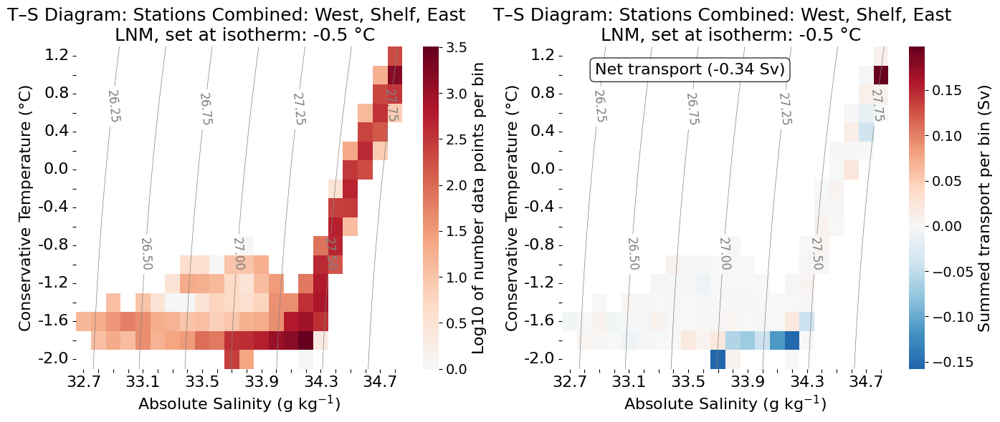

In [ ]:
# make_TS_heatmap(pair_df, title, method = "lnm_isotherm", lnm_depth = 400, isotherm_temp = None)

isotherm_temp = -0.5 
max_depth = 1000
method = "lnm_isotherm"
lnm_depth = None
isopycnal_dens = None

# --- east section (cross-shelf box) ---
use_east = np.array([164, 163, 162, 161, 160])
use_east = np.hstack([use_east_box])
amdf_east = amdf.loc[amdf['sta'].isin(use_east),:]

# --- shelf section (along-shelf box) ---
use_shelf_box = np.array([119, 122, 123, 125, 126, 127, 129, 131, 40, 132, 41, 133, 43, 134, 135, 136, 137, 139, 140, 142, 143, 144, 145, 147, 148, 149, 151, 152, 154, 161])
use_shelf = np.hstack([use_shelf_box])
amdf_shelf= amdf.loc[amdf['sta'].isin(use_shelf),:]

# --- west section (stations 115-120) ---
use_west = np.arange(115, 120+1, 1)
amdf_west = amdf.loc[amdf['sta'].isin(use_west),:]


use_sections = [use_east, use_shelf, use_west]
amdf_sections = [amdf_east, amdf_shelf, amdf_west]

title = "Stations Combined: West, Shelf, East"
max_latlon = [lat_161, None, lat_119]  # matches use_sections order: [east, shelf, west]
inflow = ["west", "south", "east"]    # matches use_sections order: [east, shelf, west]
lnm_depth = [None, None, None]
latlon = ["lat", "lon", "lat"]

make_TS_heatmap(use_sections, amdf_sections, latlon, inflow, title, method = method, lnm_depth = lnm_depth, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens, max_latlon = max_latlon)



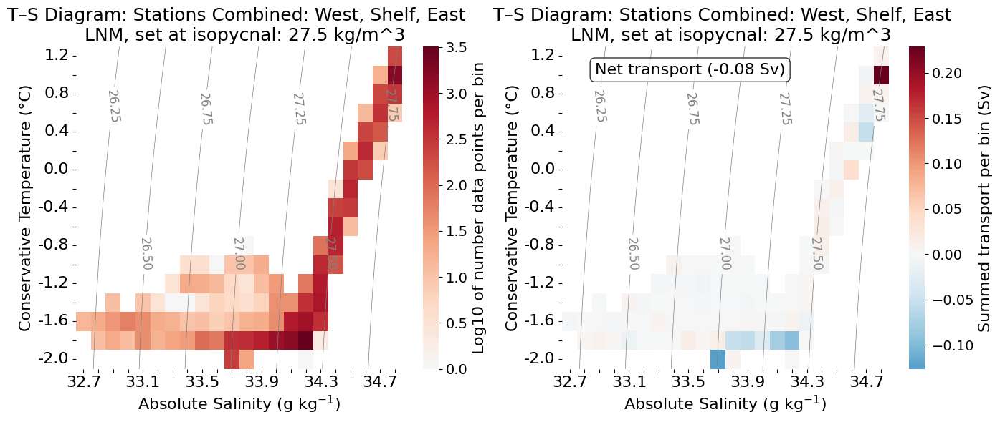

In [ ]:
isotherm_temp = None 
max_depth = 1000
method = "lnm_isopycnal"
lnm_depth = None
isopycnal_dens = 27.5

# --- east section (cross-shelf box) ---
use_east = np.array([164, 163, 162, 161, 160])
use_east = np.hstack([use_east_box])
amdf_east = amdf.loc[amdf['sta'].isin(use_east),:]

# --- shelf section (along-shelf box) ---
use_shelf_box = np.array([119, 122, 123, 125, 126, 127, 129, 131, 40, 132, 41, 133, 43, 134, 135, 136, 137, 139, 140, 142, 143, 144, 145, 147, 148, 149, 151, 152, 154, 161])
use_shelf = np.hstack([use_shelf_box])
amdf_shelf= amdf.loc[amdf['sta'].isin(use_shelf),:]

# --- west section (stations 115-120) ---
use_west = np.arange(115, 120+1, 1)
amdf_west = amdf.loc[amdf['sta'].isin(use_west),:]


use_sections = [use_east, use_shelf, use_west]
amdf_sections = [amdf_east, amdf_shelf, amdf_west]

title = "Stations Combined: West, Shelf, East"
max_latlon = [lat_161, None, lat_119]  # matches use_sections order: [east, shelf, west]
inflow = ["west", "south", "east"]    # matches use_sections order: [east, shelf, west]
lnm_depth = [None, None, None]
latlon = ["lat", "lon", "lat"]

make_TS_heatmap(use_sections, amdf_sections, latlon, inflow, title, method = method, lnm_depth = lnm_depth, isotherm_temp = isotherm_temp, isopycnal_dens = isopycnal_dens, max_latlon = max_latlon)



# Density Depth overturning 
### Ruan,2021 figure 10 
- Display of overturning transport in depth space versus density space 
- Summed over all depths, transport integrated from bottom density bin to top 

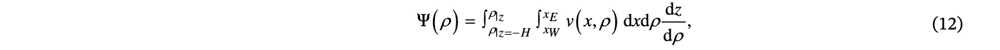
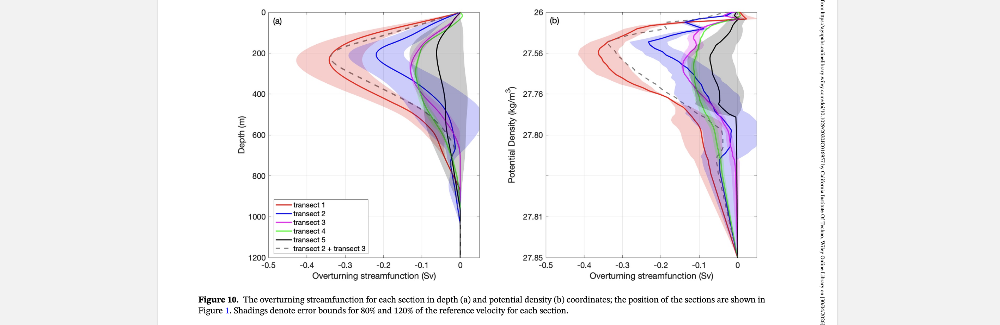

## overturning plot (like ruan fig 10)

Notes: 
- If the overturning plot crosses the zero line / reverses sign over the profile then theres stacked flows coming in and out 
- if it is a smooth curve theres one layer coming in and one layer going out - deep inflow, surface outflow 
- something is happening along the shelf? 



### western amundsen (medium) box

(<Figure size 1600x600 with 2 Axes>,
 array([<Axes: title={'center': 'Depth space'}, xlabel='Transport cummulatively summed high : low density (sv)', ylabel='depth (m)'>,
        <Axes: title={'center': 'Density space'}, xlabel='Transport cummulatively summed high : low density (sv)', ylabel='potential density anomaly kg/m^3'>],
       dtype=object))

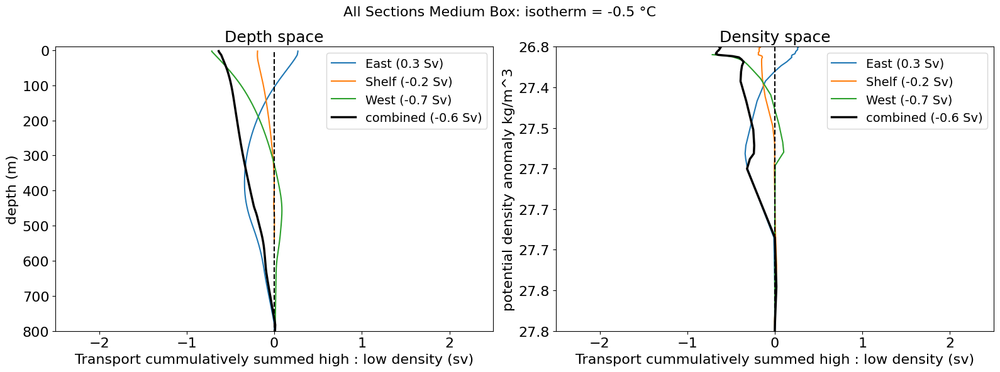

In [ ]:
"""use_west_box = np.arange(115, 119+1, 1)
use_east = np.array([45, 46, 47, 48, 49, 95, 94, 93, 69])
use_shelf = np.array([119, 122, 123, 125, 126, 127,  99, 98, 129, 131, 40, 132, 41, 133, 43, 134, 45])
"""
# a bit deeper version 

use_west_box = np.arange(115, 120+1, 1)
use_east = np.array([69, 93,94, 95,  49, 48, 47, 46, 45, 44])
use_shelf = np.array([119, 122, 123, 125, 126, 127,  129, 131, 40, 132, 41, 133, 43, 134, 45])


use_east_box = np.hstack([use_east])
use_shelf_box = np.hstack([use_shelf])

use_sections = [use_east_box, use_shelf_box, use_west_box]
labels = ["East", "Shelf",  "West"]
inflow = ["west", "south", "east"]
max_latlon = [lat_45, None, lat_119]

method = "lnm_isotherm"
isotherm_temp = -0.5 
isopycnal_dens = None 
max_depth = 800

plot_overturning_sections(use_sections, labels, d_rho=0.05, latlon = ["lat", "lon", "lat"], inflow = inflow, lnm_depth = None, method = method,
    suptitle="All Sections Medium Box: isotherm = -0.5 °C", include_bottom_triangle=True, isotherm_temp=isotherm_temp, isopycnal_dens = isopycnal_dens, 
    combine_sections = True, max_latlon=max_latlon, max_depth = max_depth)


(<Figure size 1600x600 with 2 Axes>,
 array([<Axes: title={'center': 'Depth space'}, xlabel='Transport cummulatively summed high : low density (sv)', ylabel='depth (m)'>,
        <Axes: title={'center': 'Density space'}, xlabel='Transport cummulatively summed high : low density (sv)', ylabel='potential density anomaly kg/m^3'>],
       dtype=object))

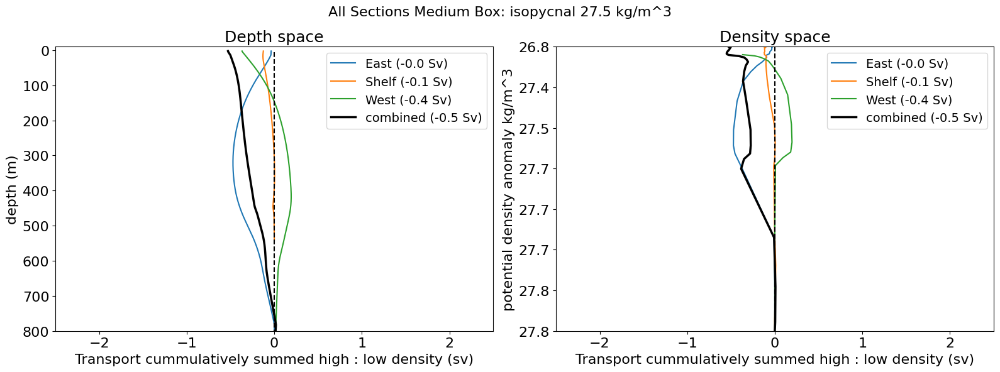

In [ ]:

# a bit deeper version 

use_west_box = np.arange(115, 120+1, 1)
use_east = np.array([69, 93,94, 95,  49, 48, 47, 46, 45, 44])
use_shelf = np.array([119, 122, 123, 125, 126, 127,  129, 131, 40, 132, 41, 133, 43, 134, 45])


use_east_box = np.hstack([use_east])
use_shelf_box = np.hstack([use_shelf])

use_sections = [use_east_box, use_shelf_box, use_west_box]
labels = ["East", "Shelf",  "West"]
inflow = ["west", "south", "east"]
max_latlon = [lat_45, None, lat_119]

method = "lnm_isopycnal"
isotherm_temp = None
isopycnal_dens = 27.5 
max_depth = 800 

plot_overturning_sections(use_sections, labels, d_rho=0.05, latlon = ["lat", "lon", "lat"], inflow = inflow, lnm_depth = None, method = method,
    suptitle="All Sections Medium Box: isopycnal 27.5 kg/m^3", include_bottom_triangle=True, isotherm_temp=isotherm_temp, isopycnal_dens = isopycnal_dens, 
    combine_sections = True, max_latlon=max_latlon, max_depth = max_depth)


Notes 
- stratification is very weak near the bottom, a large volume of shelf water sits in a compact density band
- a lot of cumulative transport fits into that band when I bin by density
- weak stratification so from 1200 to 1400 meters there just isnt a large density change, super small density bin corresponding to large depth space bin 


### all sections for whole amundsen (large) box 

(<Figure size 1600x600 with 2 Axes>,
 array([<Axes: title={'center': 'Depth space'}, xlabel='Transport cummulatively summed high : low density (sv)', ylabel='depth (m)'>,
        <Axes: title={'center': 'Density space'}, xlabel='Transport cummulatively summed high : low density (sv)', ylabel='potential density anomaly kg/m^3'>],
       dtype=object))

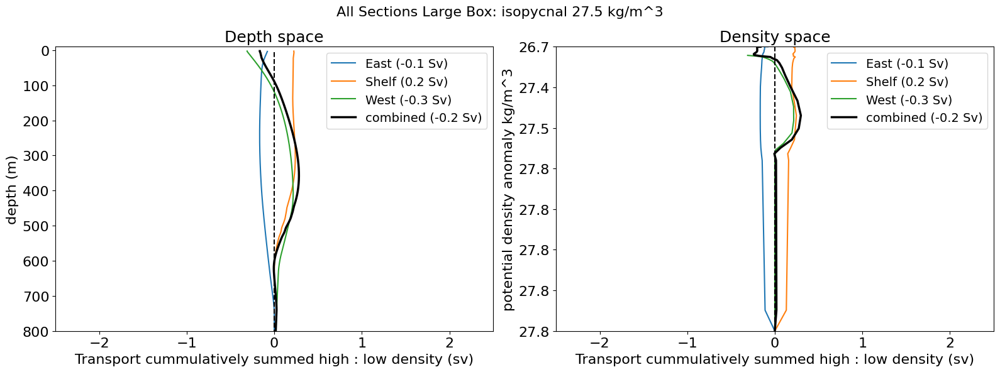

In [ ]:

# --- east section (cross-shelf box) ---
use_east = np.array([164, 163, 162, 161, 160])
use_east = np.hstack([use_east])

# --- shelf section (along-shelf box) ---
use_shelf = np.array([119, 122, 123, 125, 126, 127, 129, 131, 40, 132, 41, 133, 43, 134, 135, 136, 137, 139, 140, 142, 143, 144, 145, 147, 148, 149, 151, 152, 154, 161])
use_shelf = np.hstack([use_shelf])

# --- west section (stations 115-120) ---
use_west = np.arange(115, 120+1, 1)

title = "Stations Combined: West, Shelf, East"

use_sections = [use_east, use_shelf, use_west]
labels = ["East", "Shelf",  "West"]
max_latlon = [lat_161, None, lat_119]  # matches use_sections order: [east, shelf, west]
inflow = ["west", "south", "east"]

method = "lnm_isopycnal"
isotherm_temp = None
isopycnal_dens = 27.49
max_depth = 800 

plot_overturning_sections(use_sections, labels, d_rho=0.05, latlon = ["lat", "lon", "lat"], inflow = inflow, lnm_depth = None, method = method,
    suptitle="All Sections Large Box: isopycnal 27.5 kg/m^3", include_bottom_triangle=True, isotherm_temp=isotherm_temp, isopycnal_dens = isopycnal_dens, 
    combine_sections = True, max_latlon=max_latlon, max_depth = max_depth)


(<Figure size 1600x600 with 2 Axes>,
 array([<Axes: title={'center': 'Depth space'}, xlabel='Transport cummulatively summed high : low density (sv)', ylabel='depth (m)'>,
        <Axes: title={'center': 'Density space'}, xlabel='Transport cummulatively summed high : low density (sv)', ylabel='potential density anomaly kg/m^3'>],
       dtype=object))

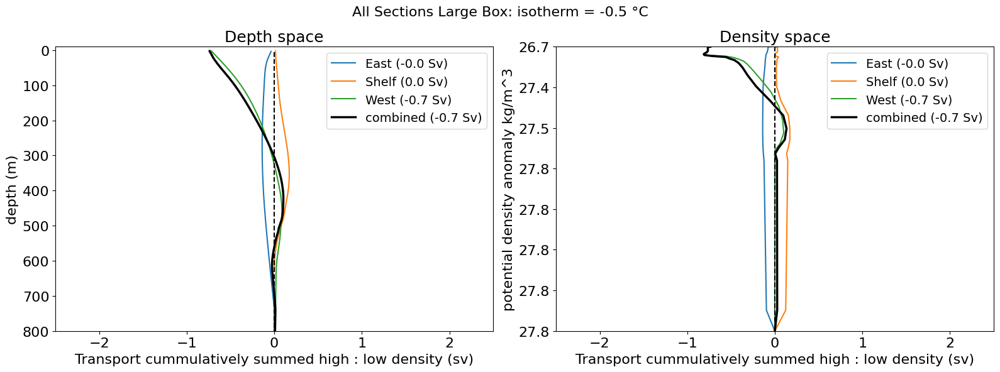

In [ ]:

# --- east section (cross-shelf box) ---
use_east = np.array([164, 163, 162, 161, 160])
use_east = np.hstack([use_east])

# --- shelf section (along-shelf box) ---
use_shelf = np.array([119, 122, 123, 125, 126, 127, 129, 131, 40, 132, 41, 133, 43, 134, 135, 136, 137, 139, 140, 142, 143, 144, 145, 147, 148, 149, 151, 152, 154, 161])
use_shelf = np.hstack([use_shelf])

# --- west section (stations 115-120) ---
use_west = np.arange(115, 120+1, 1)

title = "Stations Combined: West, Shelf, East"

use_sections = [use_east, use_shelf, use_west]
labels = ["East", "Shelf",  "West"]
max_latlon = [lat_161, None, lat_119]  # matches use_sections order: [east, shelf, west]
inflow = ["west", "south", "east"]

method = "lnm_isotherm"
isotherm_temp = -0.5 
isopycnal_dens = None 
max_depth = 800 

plot_overturning_sections(use_sections, labels, d_rho=0.05, latlon = ["lat", "lon", "lat"], inflow = inflow, lnm_depth = None, method = method,
    suptitle="All Sections Large Box: isotherm = -0.5 °C", include_bottom_triangle=True, isotherm_temp=isotherm_temp, isopycnal_dens = isopycnal_dens, 
    combine_sections = True, max_latlon=max_latlon, max_depth = max_depth)


### eastern box 

(<Figure size 1600x600 with 2 Axes>,
 array([<Axes: title={'center': 'Depth space'}, xlabel='Transport cummulatively summed high : low density (sv)', ylabel='depth (m)'>,
        <Axes: title={'center': 'Density space'}, xlabel='Transport cummulatively summed high : low density (sv)', ylabel='potential density anomaly kg/m^3'>],
       dtype=object))

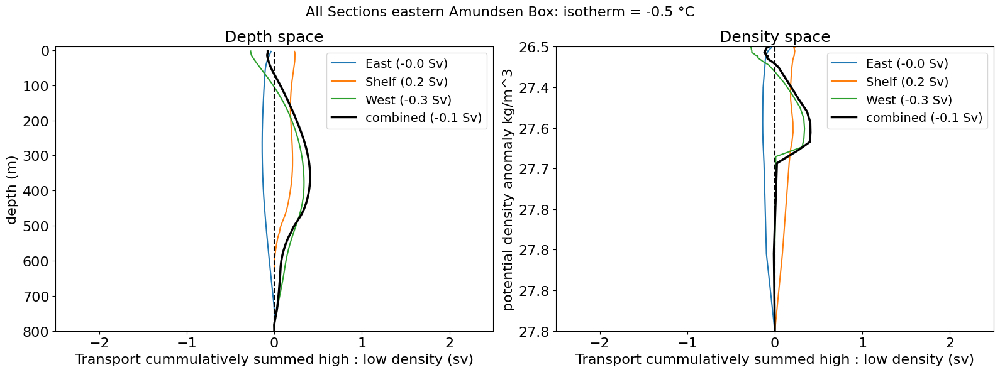

In [ ]:
# make_TS_heatmap(pair_df, title, method = "lnm_isotherm", lnm_depth = 400, isotherm_temp = None)
method = "lnm_isotherm"

use_shelf_box = np.array([45, 135, 136, 137, 139, 140, 142, 143, 144, 145, 147, 148, 149, 151, 152, 154, 161])
use_shelf = np.hstack([use_shelf_box])

# separated by latitude, cross shelf 
use_west_box = np.array([69, 93,94, 95,  49, 48, 47, 46, 45, 44])
use_west = np.hstack([use_west_box])

use_east_box = np.array([164, 163, 162, 161, 160])
use_east = np.hstack([use_east_box])


title = "Stations Combined: West, Shelf, East"

use_sections = [use_east, use_shelf, use_west]
labels = ["East", "Shelf",  "West"]
max_latlon = [lat_161, None, lat_45]  # matches use_sections order: [east, shelf, west]
inflow = ["west", "south", "east"]

method = "lnm_isotherm"
isotherm_temp = -0.5 
isopycnal_dens = None 
max_depth = 800 

plot_overturning_sections(use_sections, labels, d_rho=0.05, latlon = ["lat", "lon", "lat"], inflow = inflow, lnm_depth = None, method = method,
    suptitle="All Sections eastern Amundsen Box: isotherm = -0.5 °C", include_bottom_triangle=True, isotherm_temp=isotherm_temp, isopycnal_dens = isopycnal_dens, 
    combine_sections = True, max_latlon=max_latlon, max_depth = max_depth)


### iceshelves 

(<Figure size 1600x600 with 2 Axes>,
 array([<Axes: title={'center': 'Depth space'}, xlabel='Transport cummulatively summed high : low density (sv)', ylabel='depth (m)'>,
        <Axes: title={'center': 'Density space'}, xlabel='Transport cummulatively summed high : low density (sv)', ylabel='potential density anomaly kg/m^3'>],
       dtype=object))

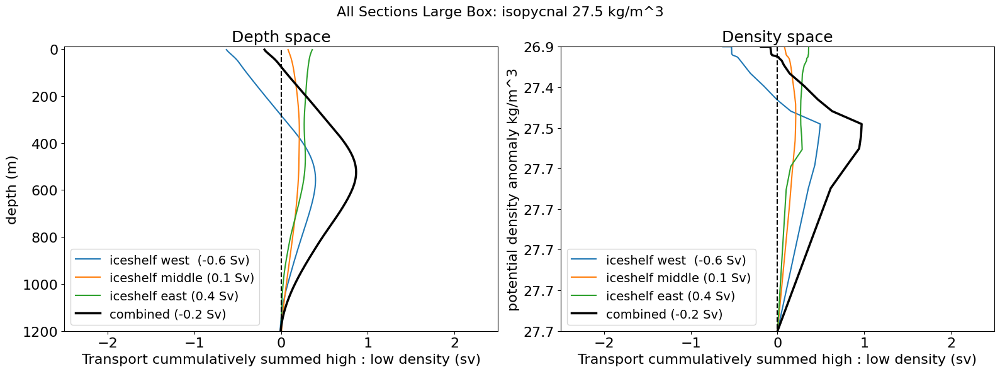

In [ ]:
use_ice_west = np.array(np.arange(52, 57 +1, 1))
use_ice_middle = np.array(np.arange(59, 63 +1, 1))
use_ice_east = np.array(np.arange(64, 69 +1, 1))
use_ice = [use_ice_west, use_ice_middle, use_ice_east]


title = "Ice Shelves"
labels = ["iceshelf west ", "iceshelf middle",  "iceshelf east"]
max_latlon = [None, None, None]  # matches use_sections order: [east, shelf, west]

method = "lnm_isopycnal"
isotherm_temp = None
isopycnal_dens = 27.45
latlon = ["lon", "lon", "lon"] 
inflow = ["south", "south", "south"]
max_depth = 1200 

plot_overturning_sections(use_ice, labels, d_rho=0.05, latlon = latlon, inflow = inflow, lnm_depth = None, method = method,
    suptitle="All Sections Large Box: isopycnal 27.5 kg/m^3", include_bottom_triangle=True, isotherm_temp=isotherm_temp, isopycnal_dens = isopycnal_dens, 
    combine_sections = True, max_latlon=max_latlon, max_depth = max_depth)
